# CancerIL-Skin — Revised Paper Pipeline (v2, GPU-only)

**CancerIL-Skin: Cancer-Class Expansion from HAM10000 to MILK10k with External Validation on DDI**

This version rebuilds the experimental pipeline around the weaknesses that would block a Q1 / A* submission. Every change maps to a specific reviewer concern:

| Reviewer concern (v1) | What this notebook does now |
|---|---|
| Single seed, SD undefined | **5 independent replicates**: each seed re-trains Stage 1, re-draws the MILK10k lesion split and re-trains every Stage-2 method. Mean ± SD, 95% t-CIs, paired t-tests and Wilcoxon with Holm correction. |
| No established continual-learning baselines | Adds **LwF, EWC, Experience Replay (herding exemplars), DER++**, a **joint-training upper bound** and a **Stage-1-only** reference, alongside your ablations. |
| Setting is not really class-incremental | Two protocols: **CDI** (class + domain incremental: old classes recur from a new source, your original setting, now named honestly) and **STRICT** (old cancer classes are *absent* from Stage-2 training, so forgetting is a real threat). |
| Cancer-FN term may only shift the operating point | Adds a **cancer-weighted-CE baseline**, **threshold-free** metrics (AUROC), **sensitivity at fixed specificity**, a **validation-derived operating point** transferred to test/DDI, and **DeLong tests**. |
| MAL_OTH has 9 lesions (1 in test) | Dropped by default (`MAL_OTH_POLICY`), reported transparently. |
| No λ sensitivity; checkpoints chosen on new-task F1 only | **Validation-only tuning** of every method's key hyper-parameter (baselines too, for fairness), a one-at-a-time λ sweep for the proposed loss, and model selection on the **harmonic mean of old- and new-task validation balanced accuracy**. |
| Stage-1 validation set of 193 images | Lesion-grouped hold-out from HAM training (if the lesion-groupings CSV is present) **plus** the official validation set. |
| Stage 2 overfits (train F1 0.8 vs val 0.5) | Stronger GPU augmentation, weight EMA, discriminative learning rates, early stopping, flip-TTA at final inference. |
| Mixed MILK modalities | Modality is read from MILK metadata; per-modality results reported; optional single-modality training. |

### GPU optimisation for an RTX 4070 SUPER (12 GB)
Training and augmentation run **only on the GPU**. Images are decoded **once** (multi-threaded) into a uint8 cache at 336 px; every epoch then streams raw bytes through a double-buffered pinned-memory stager, and random-resized-crop, rotation, flips and colour jitter all run on the GPU. There are no DataLoader worker processes (which are fragile under Jupyter on Windows) and no per-step host synchronisation. The model uses bf16 autocast (Ada supports bf16 natively, so no loss scaling), channels-last memory, TF32 matmuls and fused AdamW. Batch size is **32** (+16 replay images for rehearsal methods), which stays comfortably under 12 GB for EfficientNet-B3 at 300 px with a frozen teacher.

> **First run: keep `SMOKE_TEST = True`** (config cell). It runs the entire pipeline end-to-end on small subsets in under about an hour and writes to a separate `_SMOKE` folder. When it finishes without errors, set `SMOKE_TEST = False` for the real run. The real run is **resume-safe**: every finished run is written to disk, so you can stop the kernel and re-run all cells at any time.

## 0. Environment check (GPU required)

In [1]:
import os
import sys
import platform
from pathlib import Path

import torch

print("Python :", sys.version.split()[0])
print("Torch  :", torch.__version__, "| CUDA build:", torch.version.cuda)
print("OS     :", platform.platform())
if not torch.cuda.is_available():
    raise RuntimeError(
        "This notebook is GPU-only and CUDA is not available. Install a CUDA build of PyTorch "
        "(https://pytorch.org/get-started/locally/) and restart the kernel."
    )
_props = torch.cuda.get_device_properties(0)
print(f"GPU    : {_props.name} | {_props.total_memory / 1024**3:.1f} GB | compute capability {_props.major}.{_props.minor}")
print("bf16   :", torch.cuda.is_bf16_supported())

Python : 3.14.7
Torch  : 2.13.0+cu132 | CUDA build: 13.2
OS     : Windows-11-10.0.26300-SP0
GPU    : NVIDIA GeForce RTX 4070 SUPER | 12.0 GB | compute capability 8.9
bf16   : True


## 1. Configuration

In [2]:
# ============================================================
# 0. SMOKE TEST  (set to False for the real paper run)
# ============================================================
SMOKE_TEST = False

# ============================================================
# 1. RUN PLAN
# ============================================================
SEEDS = [42, 1337, 2026, 7, 314]   # 5 replicates: Stage-1 init, MILK split, Stage-2 init/order all vary
TUNE_SEEDS = SEEDS[:1]             # validation-only hyper-parameter tuning replicate(s)
PROTOCOLS = ["CDI", "STRICT"]      # see Section 15
RUN_TUNING = True
RUN_MAIN = True
DETERMINISTIC = True               # cuDNN deterministic kernels (slower, reproducible)
HAM_SPLIT_SEED = 42                # the HAM train/val hold-out is fixed across replicates
VERBOSE_EPOCHS = False             # print every Stage-2 epoch (Stage 1 always prints)

# ============================================================
# 2. DATA DECISIONS
# ============================================================
MAL_OTH_POLICY = "drop"            # "drop" (recommended: 9 lesions in total) or "keep"
STAGE2_MODALITY = "both"           # "both", "dermoscopic" or "clinical"
HAM_VAL_FRACTION_FROM_TRAIN = 0.15 # lesion-grouped hold-out from HAM train (needs lesion-groupings CSV)
MILK_VAL_FRACTION = 0.15
MILK_TEST_FRACTION = 0.15

# ============================================================
# 3. GPU / THROUGHPUT  (RTX 4070 SUPER, 12 GB)
# ============================================================
IMG_SIZE = 300                     # EfficientNet-B3 native resolution
CACHE_SIZE = 336                   # decoded once to 336x336 uint8; random-resized-crop to 300 on GPU
BATCH_SIZE = 32
REPLAY_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 128
AMP_DTYPE = "bf16"
CHANNELS_LAST = True
CACHE_THREADS = 16                 # CPU threads for the one-time JPEG decode (i5-14600K: 20 threads)
EVAL_TTA = True                    # 4-way flip TTA for final inference only (val + test, same setting)
USE_IMAGENET_WEIGHTS = True

# ============================================================
# 4. OPTIMISATION
# ============================================================
STAGE1_EPOCHS, STAGE1_PATIENCE = 40, 10
STAGE2_EPOCHS, STAGE2_PATIENCE = 30, 8
WARMUP_EPOCHS = 1
LR_BACKBONE_S1, LR_HEAD_S1 = 3e-4, 1e-3
LR_BACKBONE_S2, LR_HEAD_S2 = 1e-4, 1e-3
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 5.0
EMA_HALFLIFE_EPOCHS = 0.5          # weight-EMA half-life, independent of dataset size
CLASS_BALANCED_CE = True           # sqrt-inverse-frequency CE weights, identical for every method
SELECTION = "joint_val"            # "joint_val": H-mean(HAM-val bal-acc, MILK-val bal-acc); "new_only": MILK-val only

AUG_AREA = (0.60, 1.00)
AUG_ROT_DEG = 180.0                # lesions have no canonical orientation
AUG_BRIGHTNESS, AUG_CONTRAST, AUG_SATURATION = 0.20, 0.20, 0.15

# ============================================================
# 5. METHODS  (defaults; replaced by validation-tuned values when RUN_TUNING)
# ============================================================
KD_TEMP = 2.0
DEFAULT_HP = {
    "kd": 0.5, "proto": 0.2, "fn": 2.0,          # proposed CancerIL-Skin objective
    "lwf_kd": 0.5, "ewc": 1e3, "cancer_w": 2.0,  # baselines
    "der_alpha": 0.3,
}
DER_BETA = 0.5
REPLAY_PER_CLASS = 50              # herding exemplars per old class (200 HAM images in total)
FISHER_MAX_IMAGES = 3000
TUNING_GRIDS = {
    "kd":        [0.25, 0.5, 1.0, 2.0],
    "proto":     [0.05, 0.1, 0.2, 0.5],
    "fn":        [0.5, 1.0, 2.0, 4.0],
    "lwf_kd":    [0.25, 0.5, 1.0, 2.0],
    "ewc":       [1e2, 1e3, 1e4, 1e5],
    "cancer_w":  [1.5, 2.0, 3.0, 4.0],
    "der_alpha": [0.1, 0.3, 0.5, 1.0],
}

# ============================================================
# 6. EVALUATION
# ============================================================
TARGET_SENSITIVITY = 0.90          # operating point chosen on MILK validation, applied to test + DDI
FIXED_SPECIFICITIES = (0.80, 0.90)
PRIMARY_METHOD = "CancerIL_Full"

# ============================================================
# 7. PATHS
# ============================================================
HAM_ROOT = r"D:\Project\New folder\Dataset\HAM10K"
MILK_ROOT = r"D:\Project\New folder\Dataset\MILK10K"
DDI_ROOT = r"D:\Project\New folder\Dataset\DDI"
BASE_OUTPUT = Path(r"D:\Project\New folder\canceril_skin_outputs_v2")
SAVE_STAGE2_CHECKPOINTS = True     # ~43 MB per run

# ------------------------------------------------------------
SMOKE_MAX_TRAIN = None
if SMOKE_TEST:
    SEEDS = [42, 1337]
    TUNE_SEEDS = [42]
    STAGE1_EPOCHS, STAGE1_PATIENCE = 2, 2
    STAGE2_EPOCHS, STAGE2_PATIENCE = 2, 2
    TUNING_GRIDS = {k: v[:2] for k, v in TUNING_GRIDS.items()}
    SMOKE_MAX_TRAIN = 640

CACHE_DIR = BASE_OUTPUT / "cache"            # shared by smoke and real runs
OUTPUT_ROOT = BASE_OUTPUT.parent / (BASE_OUTPUT.name + "_SMOKE") if SMOKE_TEST else BASE_OUTPUT
CKPT_DIR = OUTPUT_ROOT / "checkpoints"
RUNS_DIR = OUTPUT_ROOT / "runs"
PRED_DIR = OUTPUT_ROOT / "predictions"
RESULT_DIR = OUTPUT_ROOT / "results"
FIG_DIR = OUTPUT_ROOT / "figures"
SPLIT_DIR = OUTPUT_ROOT / "splits"
for d in [CACHE_DIR, OUTPUT_ROOT, CKPT_DIR, CKPT_DIR / "stage2", RUNS_DIR, PRED_DIR, RESULT_DIR, FIG_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if SMOKE_TEST:
    print("=" * 78)
    print("SMOKE TEST MODE: tiny subsets, 2 epochs, 2 seeds. Results are NOT paper results.")
    print("Set SMOKE_TEST = False once this notebook runs end-to-end without errors.")
    print("=" * 78)
print("Outputs:", OUTPUT_ROOT.resolve())
print("Cache  :", CACHE_DIR.resolve())

Outputs: D:\Project\New folder\canceril_skin_outputs_v2
Cache  : D:\Project\New folder\canceril_skin_outputs_v2\cache


## 2. Imports, reproducibility and GPU setup

In [3]:
import json
import copy
import math
import random
import time
import hashlib
import gc
import warnings
from types import SimpleNamespace
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tv_models
from tqdm.auto import tqdm

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
)

warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device("cuda")
torch.cuda.set_device(0)
torch.backends.cudnn.benchmark = not DETERMINISTIC
torch.backends.cudnn.deterministic = DETERMINISTIC
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")

AMP = torch.bfloat16 if (AMP_DTYPE == "bf16" and torch.cuda.is_bf16_supported()) else torch.float16
USE_SCALER = AMP == torch.float16
MEMORY_FORMAT = torch.channels_last if CHANNELS_LAST else torch.contiguous_format
IMAGENET_MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD_T = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

set_seed(SEEDS[0])
print("Device:", torch.cuda.get_device_name(0), "| autocast dtype:", AMP, "| grad scaler:", USE_SCALER)

c:\Users\Debajyoti\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: NVIDIA GeForce RTX 4070 SUPER | autocast dtype: torch.bfloat16 | grad scaler: False


## 3. Dataset paths and class definitions

`MAL_OTH` has only 9 labelled lesions in MILK10k. With the default policy it is removed, so the new cancer class is `SCCKA`; report this exclusion in the paper.

In [4]:
HAM_DIRS = {
    "train_data": os.path.join(HAM_ROOT, "Training Data"),
    "train_gt":   os.path.join(HAM_ROOT, "Training Ground Truth"),
    "val_data":   os.path.join(HAM_ROOT, "Validation Data"),
    "val_gt":     os.path.join(HAM_ROOT, "Validation Ground Truth"),
    "test_data":  os.path.join(HAM_ROOT, "Test Data"),
    "test_gt":    os.path.join(HAM_ROOT, "Test Ground Truth"),
}
MILK_TRAIN_ROOT = os.path.join(MILK_ROOT, "Train")
DDI_IMG_DIR = os.path.join(DDI_ROOT, "DDI_images")
DDI_MALIGNANT_COL = "malignant"
DDI_FILE_COL = "DDI_file"

for p in [HAM_ROOT, MILK_TRAIN_ROOT, DDI_IMG_DIR, *HAM_DIRS.values()]:
    if not os.path.isdir(p):
        raise FileNotFoundError(f"Missing directory: {p}")

HAM_COLUMN_MAP = {
    "MEL": "MEL", "BCC": "BCC", "AKIEC": "AKIEC",
    "NV": "non-cancer", "BKL": "non-cancer", "DF": "non-cancer", "VASC": "non-cancer",
}
HAM_CLASSES = ["MEL", "BCC", "AKIEC", "non-cancer"]

MILK_COLUMN_MAP = {
    "MEL": "MEL", "BCC": "BCC", "AKIEC": "AKIEC",
    "SCCKA": "SCCKA", "SCC_KA": "SCCKA", "SCC/KA": "SCCKA",
    "MAL_OTH": "MAL_OTH", "MAL OTH": "MAL_OTH", "OTHER_MALIGNANT": "MAL_OTH",
    "NV": "non-cancer", "BKL": "non-cancer", "DF": "non-cancer", "VASC": "non-cancer",
    "BEN_OTH": "non-cancer", "INF": "non-cancer",
}
if MAL_OTH_POLICY == "keep":
    MILK_CLASSES = ["MEL", "BCC", "AKIEC", "SCCKA", "MAL_OTH", "non-cancer"]
elif MAL_OTH_POLICY == "drop":
    MILK_CLASSES = ["MEL", "BCC", "AKIEC", "SCCKA", "non-cancer"]
else:
    raise ValueError("MAL_OTH_POLICY must be 'keep' or 'drop'")

OLD_CLASSES = list(HAM_CLASSES)
NEW_CLASSES = [c for c in MILK_CLASSES if c not in OLD_CLASSES]
CANCER_CLASSES = [c for c in MILK_CLASSES if c != "non-cancer"]
NC_IDX = MILK_CLASSES.index("non-cancer")
OLD_IDX_IN_NEW = [MILK_CLASSES.index(c) for c in OLD_CLASSES]
NEW_IDX = [MILK_CLASSES.index(c) for c in NEW_CLASSES]
CANCER_IDX = [MILK_CLASSES.index(c) for c in CANCER_CLASSES]

print("Stage-1 classes:", HAM_CLASSES)
print("Stage-2 classes:", MILK_CLASSES, "| new:", NEW_CLASSES)

Stage-1 classes: ['MEL', 'BCC', 'AKIEC', 'non-cancer']
Stage-2 classes: ['MEL', 'BCC', 'AKIEC', 'SCCKA', 'non-cancer'] | new: ['SCCKA']


## 4. Data-loading utilities

In [5]:
VALID_EXT = (".jpg", ".jpeg", ".png")


def stem(p):
    return os.path.splitext(os.path.basename(str(p)))[0]


def all_csvs(folder):
    out = []
    for dirpath, _, filenames in os.walk(folder):
        out += [os.path.join(dirpath, f) for f in filenames if f.lower().endswith(".csv")]
    return sorted(out)


def find_csv(folder_or_csv, contains=None):
    if folder_or_csv is None:
        return None
    s = str(folder_or_csv)
    if s.lower().endswith(".csv"):
        return s if os.path.isfile(s) else None
    if not os.path.isdir(s):
        return None
    cands = all_csvs(s)
    if contains:
        filtered = [c for c in cands if contains.lower() in os.path.basename(c).lower()]
        cands = filtered or cands
    return cands[0] if cands else None


def csv_columns(path):
    try:
        return set(pd.read_csv(path, nrows=2).columns)
    except Exception:
        return set()


def first_existing(columns, candidates):
    return next((c for c in candidates if c in columns), None)


def build_image_index(image_dir):
    index = {}
    for dirpath, _, filenames in os.walk(image_dir):
        for f in filenames:
            if f.lower().endswith(VALID_EXT):
                index[stem(f)] = os.path.join(dirpath, f)
    return index


def labels_from_onehot(df, column_map):
    present = [c for c in column_map if c in df.columns]
    if not present:
        raise KeyError(f"No diagnosis columns found. Columns: {list(df.columns)}")
    vals = df[present].apply(pd.to_numeric, errors="coerce").fillna(0.0)
    lab = vals.idxmax(axis=1).map(column_map)
    lab[vals.max(axis=1) < 0.5] = None
    return lab


def load_split(image_dir, gt_dir, column_map, classes):
    csv_path = find_csv(gt_dir)
    if csv_path is None:
        raise FileNotFoundError(f"No ground-truth CSV found in {gt_dir}")
    df = pd.read_csv(csv_path)
    id_col = first_existing(df.columns, ["image", "image_id"]) or df.columns[0]
    df["image_id"] = df[id_col].astype(str).map(stem)
    df["filepath"] = df["image_id"].map(build_image_index(image_dir))
    n_missing = int(df["filepath"].isna().sum())
    if n_missing:
        print(f"[WARN] {n_missing} rows in {os.path.basename(csv_path)} have no image")
    df["label"] = labels_from_onehot(df, column_map)
    df = df.dropna(subset=["filepath", "label"])
    df = df[df["label"].isin(classes)].reset_index(drop=True)
    print(f"Loaded {len(df)} images from {os.path.basename(csv_path)}")
    return df[["image_id", "filepath", "label"]]


def find_split_dir(root, keywords):
    matches = []
    for dirpath, _, _ in os.walk(root):
        if any(k.lower() in os.path.basename(dirpath).lower() for k in keywords):
            has_img = any(
                f.lower().endswith(VALID_EXT) for _, _, files in os.walk(dirpath) for f in files
            )
            if has_img:
                matches.append(dirpath)
    matches.sort(key=lambda p: (len(Path(p).parts), len(p)))
    return matches[0] if matches else None


def build_lesion_folder_index(image_dir):
    index = {}
    for entry in os.scandir(image_dir):
        if entry.is_dir():
            imgs = sorted(
                os.path.join(entry.path, f) for f in os.listdir(entry.path) if f.lower().endswith(VALID_EXT)
            )
            if imgs:
                index[entry.name] = imgs
    return index


def load_milk_lesion_labels(train_root, column_map, classes):
    csv_path = find_csv(train_root, contains="GroundTruth")
    if csv_path is None:
        raise FileNotFoundError(f"No MILK10k ground-truth CSV under {train_root}")
    df = pd.read_csv(csv_path)
    if "lesion_id" not in df.columns:
        raise KeyError(f"'lesion_id' missing in {csv_path}")
    df["label"] = labels_from_onehot(df, column_map)
    excluded = df.loc[~df["label"].isin(classes), "label"].value_counts(dropna=False)
    if len(excluded):
        print("Excluded MILK10k lesions (label not in MILK_CLASSES):")
        print(excluded.to_string())
    df = df[df["label"].isin(classes)][["lesion_id", "label"]].copy()
    df["lesion_id"] = df["lesion_id"].astype(str)
    print(f"Loaded {len(df)} labelled lesions from {os.path.basename(csv_path)}")
    return df.reset_index(drop=True)


def normalise_modality(v):
    s = str(v).lower()
    if "derm" in s:
        return "dermoscopic"
    if "clinic" in s:
        return "clinical"
    return "unknown"


def load_milk_modality(train_root):
    for p in all_csvs(train_root):
        cols = csv_columns(p)
        id_col = first_existing(cols, ["isic_id", "image_id", "image"])
        type_col = first_existing(cols, ["image_type", "modality", "type"])
        if id_col and type_col:
            m = pd.read_csv(p)
            print(f"MILK modality metadata: {os.path.basename(p)} ({id_col} -> {type_col})")
            return dict(zip(m[id_col].astype(str).map(stem), m[type_col].map(normalise_modality)))
    print("[WARN] No MILK modality metadata found; modality = 'unknown'.")
    return {}


def milk_images_for_lesions(lesion_df, lesion_index, modality_map):
    rows, n_missing = [], 0
    for r in lesion_df.itertuples(index=False):
        paths = lesion_index.get(str(r.lesion_id))
        if not paths:
            n_missing += 1
            continue
        for p in paths:
            rows.append({
                "lesion_id": str(r.lesion_id), "image_id": stem(p), "filepath": p,
                "label": r.label, "modality": modality_map.get(stem(p), "unknown"),
            })
    if n_missing:
        print(f"[WARN] {n_missing} lesions have no image folder")
    return pd.DataFrame(rows)


def parse_bool_like(v):
    if pd.isna(v):
        return None
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer, float, np.floating)):
        return bool(int(v))
    s = str(v).strip().lower()
    if s in {"1", "true", "t", "yes", "y", "malignant"}:
        return True
    if s in {"0", "false", "f", "no", "n", "benign"}:
        return False
    raise ValueError(f"Cannot interpret as boolean: {v!r}")

## 5. HAM10000 with a lesion-grouped validation set

HAM10000 contains several images per lesion. If a lesion-groupings file is anywhere under `HAM_ROOT` (`ISIC2018_Task3_Training_LesionGroupings.csv` or `HAM10000_metadata.csv`, both public), 15% of training **lesions** are held out and combined with the official 193-image validation set. Without it, the notebook falls back to the official validation set and warns you. Downloading that CSV is strongly recommended.

In [6]:
ham_train_full = load_split(HAM_DIRS["train_data"], HAM_DIRS["train_gt"], HAM_COLUMN_MAP, HAM_CLASSES)
ham_official_val = load_split(HAM_DIRS["val_data"], HAM_DIRS["val_gt"], HAM_COLUMN_MAP, HAM_CLASSES)
ham_test_df = load_split(HAM_DIRS["test_data"], HAM_DIRS["test_gt"], HAM_COLUMN_MAP, HAM_CLASSES)


def find_ham_lesion_groupings(root):
    for p in all_csvs(root):
        cols = csv_columns(p)
        if "lesion_id" in cols and ({"image", "image_id"} & cols):
            return p
    return None


grp_csv = find_ham_lesion_groupings(HAM_ROOT)
ham_official_val = ham_official_val.assign(lesion_id="val_" + ham_official_val["image_id"])
ham_test_df = ham_test_df.assign(lesion_id="test_" + ham_test_df["image_id"])

if grp_csv:
    g = pd.read_csv(grp_csv)
    id_col = "image" if "image" in g.columns else "image_id"
    lesion_map = dict(zip(g[id_col].astype(str).map(stem), g["lesion_id"].astype(str)))
    ham_train_full["lesion_id"] = ham_train_full["image_id"].map(lesion_map)
    n_miss = int(ham_train_full["lesion_id"].isna().sum())
    if n_miss:
        print(f"[WARN] {n_miss} HAM training images have no lesion id; each becomes its own group")
        ham_train_full["lesion_id"] = ham_train_full["lesion_id"].fillna("img_" + ham_train_full["image_id"])
    sgkf = StratifiedGroupKFold(
        n_splits=max(2, int(round(1 / HAM_VAL_FRACTION_FROM_TRAIN))), shuffle=True, random_state=HAM_SPLIT_SEED
    )
    tr_i, va_i = next(sgkf.split(np.zeros(len(ham_train_full)), ham_train_full["label"], groups=ham_train_full["lesion_id"]))
    ham_train_df = ham_train_full.iloc[tr_i].reset_index(drop=True)
    ham_val_df = pd.concat([ham_train_full.iloc[va_i], ham_official_val], ignore_index=True)
    assert set(ham_train_df["lesion_id"]).isdisjoint(set(ham_val_df["lesion_id"]))
    HAM_VAL_SOURCE = f"lesion-grouped {HAM_VAL_FRACTION_FROM_TRAIN:.0%} of HAM train ({os.path.basename(grp_csv)}) + official val"
else:
    print("[WARN] No HAM lesion-groupings CSV found. Falling back to the 193-image official validation set.")
    print("       Download ISIC2018_Task3_Training_LesionGroupings.csv and place it under HAM_ROOT.")
    ham_train_full["lesion_id"] = "img_" + ham_train_full["image_id"]
    ham_train_df = ham_train_full.copy()
    ham_val_df = ham_official_val.copy()
    HAM_VAL_SOURCE = "official ISIC2018 validation set only"

print("\nHAM validation source:", HAM_VAL_SOURCE)
print(pd.DataFrame({
    "train": ham_train_df["label"].value_counts(),
    "val": ham_val_df["label"].value_counts(),
    "test": ham_test_df["label"].value_counts(),
}).fillna(0).astype(int).reindex(HAM_CLASSES))

ham_train_df.to_csv(SPLIT_DIR / "ham_train_manifest.csv", index=False)
ham_val_df.to_csv(SPLIT_DIR / "ham_val_manifest.csv", index=False)
ham_test_df.to_csv(SPLIT_DIR / "ham_test_manifest.csv", index=False)

# Stage-1 artifacts (checkpoint, predictions, prototypes, exemplars, Fisher) are keyed on the
# exact HAM train/val split and Stage-1 config, so adding the lesion-groupings CSV later never
# silently reuses a Stage-1 model trained on images that are now in the validation set.
STAGE1_TAG = hashlib.sha1(json.dumps({
    "ham_val_source": HAM_VAL_SOURCE,
    "val_ids": sorted(ham_val_df["image_id"].astype(str).tolist()),
    "n_train": int(len(ham_train_df)),
    "e1": STAGE1_EPOCHS, "p1": STAGE1_PATIENCE, "lr1": [LR_BACKBONE_S1, LR_HEAD_S1],
    "img": IMG_SIZE, "smoke": SMOKE_TEST,
}, sort_keys=True).encode()).hexdigest()[:8]
if grp_csv:
    print(f"Lesion groupings: {grp_csv}")
    print(f"HAM train lesions: {ham_train_df['lesion_id'].nunique()} | held-out val lesions: "
          f"{ham_val_df['lesion_id'].nunique() - len(ham_official_val)} (+{len(ham_official_val)} official val images)")
print("Stage-1 artifact tag:", STAGE1_TAG)


Loaded 10015 images from ISIC2018_Task3_Training_GroundTruth.csv
Loaded 193 images from ISIC2018_Task3_Validation_GroundTruth.csv
Loaded 1512 images from ISIC2018_Task3_Test_GroundTruth.csv

HAM validation source: lesion-grouped 15% of HAM train (ISIC2018_Task3_Training_LesionGroupings.csv) + official val
            train   val  test
label                        
MEL           954   180   171
BCC           440    89    93
AKIEC         281    54    43
non-cancer   6909  1301  1205
Lesion groupings: D:\Project\New folder\Dataset\HAM10K\Training Data\ISIC2018_Task3_Training_LesionGroupings.csv
HAM train lesions: 6403 | held-out val lesions: 1067 (+193 official val images)
Stage-1 artifact tag: 11ce80a7


## 6. MILK10k lesions, modality and per-seed lesion-level splits

Each replicate seed draws its own stratified lesion-level train/val/test split, saved under `splits/seed*/` so runs are reproducible and resumable.

In [7]:
MILK_TRAIN_DATA = find_split_dir(MILK_TRAIN_ROOT, ("input",)) or os.path.join(MILK_TRAIN_ROOT, "MILK10k_Training_Input")
if not os.path.isdir(MILK_TRAIN_DATA):
    raise FileNotFoundError(f"Could not locate MILK10k training images under {MILK_TRAIN_ROOT}")

milk_lesion_df = load_milk_lesion_labels(MILK_TRAIN_ROOT, MILK_COLUMN_MAP, MILK_CLASSES)
milk_modality_map = load_milk_modality(MILK_TRAIN_ROOT)
milk_lesion_image_index = build_lesion_folder_index(MILK_TRAIN_DATA)
milk_all_images_df = milk_images_for_lesions(milk_lesion_df, milk_lesion_image_index, milk_modality_map)

print("\nMILK10k images by modality:")
print(milk_all_images_df["modality"].value_counts().to_string())
if STAGE2_MODALITY != "both":
    milk_all_images_df = milk_all_images_df[milk_all_images_df["modality"] == STAGE2_MODALITY].reset_index(drop=True)
    print(f"Restricted to modality = {STAGE2_MODALITY}: {len(milk_all_images_df)} images")
milk_lesion_df = milk_lesion_df[milk_lesion_df["lesion_id"].isin(set(milk_all_images_df["lesion_id"]))].reset_index(drop=True)

print("\nMILK10k labelled lesions by class:")
print(milk_lesion_df["label"].value_counts().reindex(MILK_CLASSES).to_string())


def make_milk_split(seed):
    """Stratified lesion-level split for one replicate; cached on disk."""
    d = SPLIT_DIR / f"seed{seed}"
    d.mkdir(parents=True, exist_ok=True)
    f = d / "milk_lesion_split.csv"
    if f.exists():
        split = pd.read_csv(f, dtype={"lesion_id": str})
    else:
        tr, tmp = train_test_split(
            milk_lesion_df, test_size=MILK_VAL_FRACTION + MILK_TEST_FRACTION,
            random_state=seed, stratify=milk_lesion_df["label"],
        )
        va, te = train_test_split(
            tmp, test_size=MILK_TEST_FRACTION / (MILK_VAL_FRACTION + MILK_TEST_FRACTION),
            random_state=seed, stratify=tmp["label"],
        )
        split = pd.concat([tr.assign(split="train"), va.assign(split="val"), te.assign(split="test")], ignore_index=True)
        split.to_csv(f, index=False)
    lesion_to_split = dict(zip(split["lesion_id"].astype(str), split["split"]))
    imgs = milk_all_images_df.assign(split=milk_all_images_df["lesion_id"].map(lesion_to_split))
    out = {s: imgs[imgs["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
    ids = {s: set(out[s]["lesion_id"]) for s in out}
    assert ids["train"].isdisjoint(ids["val"]) and ids["train"].isdisjoint(ids["test"]) and ids["val"].isdisjoint(ids["test"])
    return out

Excluded MILK10k lesions (label not in MILK_CLASSES):
label
MAL_OTH    9
Loaded 5231 labelled lesions from MILK10k_Training_GroundTruth.csv
MILK modality metadata: MILK10k_Training_Metadata.csv (isic_id -> image_type)

MILK10k images by modality:
modality
dermoscopic    5231
clinical       5231

MILK10k labelled lesions by class:
label
MEL            450
BCC           2522
AKIEC          303
SCCKA          473
non-cancer    1483


## 7. DDI external-validation set

In [8]:
ddi_csv = next((p for p in all_csvs(DDI_ROOT) if {DDI_FILE_COL, DDI_MALIGNANT_COL} <= csv_columns(p)), None)
if ddi_csv is None:
    raise FileNotFoundError(f"No DDI metadata CSV with {DDI_FILE_COL!r} and {DDI_MALIGNANT_COL!r} under {DDI_ROOT}")
ddi_meta = pd.read_csv(ddi_csv)


def map_ddi_subtype(disease):
    d = str(disease).lower()
    if "melanoma" in d:
        return "MEL"
    if "basal" in d and "carcinoma" in d:
        return "BCC"
    if ("squamous" in d and "carcinoma" in d) or "keratoacanth" in d:
        return "SCCKA"
    return None


ddi_index = build_image_index(DDI_IMG_DIR)
rows = []
for row_idx, r in ddi_meta.iterrows():
    fp = ddi_index.get(stem(r[DDI_FILE_COL]))
    mal = parse_bool_like(r[DDI_MALIGNANT_COL])
    if fp is None or mal is None:
        continue
    rows.append({
        "image_id": stem(fp), "filepath": fp,
        "label": "malignant" if mal else "benign",
        "disease": r.get("disease"),
        "subtype": map_ddi_subtype(r.get("disease")) if mal else None,
        "skin_tone": r.get("skin_tone"),
    })
ddi_df = pd.DataFrame(rows).reset_index(drop=True)
print(f"Loaded {len(ddi_df)} DDI images from {os.path.basename(ddi_csv)}")
print(ddi_df["label"].value_counts().to_string())
print("\nSkin tone:\n" + ddi_df["skin_tone"].value_counts(dropna=False).to_string())
print("\nMapped malignant subtypes:\n" + ddi_df["subtype"].value_counts().to_string())
ddi_df.to_csv(SPLIT_DIR / "ddi_external_manifest.csv", index=False)

Loaded 656 DDI images from ddi_metadata.csv
label
benign       485
malignant    171

Skin tone:
skin_tone
34    241
12    208
56    207

Mapped malignant subtypes:
subtype
SCCKA    53
BCC      49
MEL      21


## 8. One-time decoded image cache → one uint8 pool in RAM

All images are decoded once with a thread pool and resized to 336×336 uint8. The `.npy` caches are keyed by the exact file list, so they are rebuilt only if the data change. The whole pool (≈23k images ≈ 7.7 GB) is then held in RAM (32 GB is enough), and batches are streamed to the GPU. The first build takes roughly 10–30 minutes; later sessions load in about a minute.

In [9]:
def _decode_resize(path, size=CACHE_SIZE):
    with Image.open(path) as im:
        try:
            im.draft("RGB", (size * 2, size * 2))   # fast JPEG DCT downscale, still >= 2x target
        except Exception:
            pass
        im = im.convert("RGB").resize((size, size), Image.Resampling.BICUBIC, reducing_gap=3.0)
        return np.asarray(im, dtype=np.uint8)


def _write_cache(tmp_path, filepaths, desc):
    arr = np.lib.format.open_memmap(
        str(tmp_path), mode="w+", dtype=np.uint8, shape=(len(filepaths), CACHE_SIZE, CACHE_SIZE, 3)
    )

    def work(i):
        arr[i] = _decode_resize(filepaths[i])

    with ThreadPoolExecutor(max_workers=CACHE_THREADS) as ex:
        for _ in tqdm(ex.map(work, range(len(filepaths))), total=len(filepaths), desc=desc):
            pass
    arr.flush()
    del arr


def ensure_cache(name, filepaths):
    h = hashlib.sha1(("|".join(filepaths) + f"|{CACHE_SIZE}").encode("utf-8")).hexdigest()[:12]
    path = CACHE_DIR / f"{name}_{CACHE_SIZE}px_{h}.npy"
    if not path.exists():
        tmp = CACHE_DIR / f"{name}_{CACHE_SIZE}px_{h}.tmp.npy"
        if tmp.exists():
            tmp.unlink()
        _write_cache(tmp, filepaths, f"Decoding {name}")
        gc.collect()
        os.replace(tmp, path)
    return path


ham_paths = pd.concat([ham_train_full, ham_official_val, ham_test_df])["filepath"].drop_duplicates().tolist()
milk_paths = milk_all_images_df["filepath"].drop_duplicates().tolist()
ddi_paths = ddi_df["filepath"].drop_duplicates().tolist()

cache_files = [(ensure_cache(n, p), len(p)) for n, p in [("ham", ham_paths), ("milk", milk_paths), ("ddi", ddi_paths)]]
all_paths = ham_paths + milk_paths + ddi_paths
N_TOTAL = len(all_paths)

GLOBAL_POOL = torch.empty((N_TOTAL, CACHE_SIZE, CACHE_SIZE, 3), dtype=torch.uint8)
off = 0
for path, n in cache_files:
    mm = np.load(path, mmap_mode="r")
    for s in tqdm(range(0, n, 1024), desc=f"Loading {path.name}", leave=False):
        e = min(s + 1024, n)
        GLOBAL_POOL[off + s: off + e] = torch.from_numpy(np.ascontiguousarray(mm[s:e]))
    del mm
    off += n
gc.collect()

PATH_TO_GIDX = {p: i for i, p in enumerate(all_paths)}
for _df in [ham_train_full, ham_official_val, ham_train_df, ham_val_df, ham_test_df, milk_all_images_df, ddi_df]:
    _df["gidx"] = _df["filepath"].map(PATH_TO_GIDX).astype(np.int64)

print(f"Pool: {N_TOTAL} images, {GLOBAL_POOL.numel() / 1024**3:.2f} GB in RAM")

_preview = make_milk_split(SEEDS[0])
print(f"\nMILK split for seed {SEEDS[0]} (images): " + ", ".join(f"{k}={len(v)}" for k, v in _preview.items()))
print("Test lesions by class:")
print(_preview["test"].groupby("lesion_id")["label"].first().value_counts().reindex(MILK_CLASSES).to_string())

Loading ham_336px_980cac5341ec.npy:   0%|          | 0/12 [00:00<?, ?it/s]C:\Users\Debajyoti\AppData\Local\Temp\ipykernel_4084\3728637803.py:53: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  GLOBAL_POOL[off + s: off + e] = torch.from_numpy(np.ascontiguousarray(mm[s:e]))


Pool: 22838 images, 7.20 GB in RAM

MILK split for seed 42 (images): train=7322, val=1570, test=1570
Test lesions by class:
label
MEL            68
BCC           378
AKIEC          46
SCCKA          71
non-cancer    222


## 9. GPU data pipeline and GPU augmentation

Batches are gathered from the RAM pool into a double-buffered pinned staging area and copied asynchronously. Labels, shuffling indices and the replay buffer live on the GPU, so the training loop never forces a host synchronisation. Augmentation (random-resized crop, full rotation, flips, brightness/contrast/saturation) is a single batched affine `grid_sample` plus a few element-wise operations.

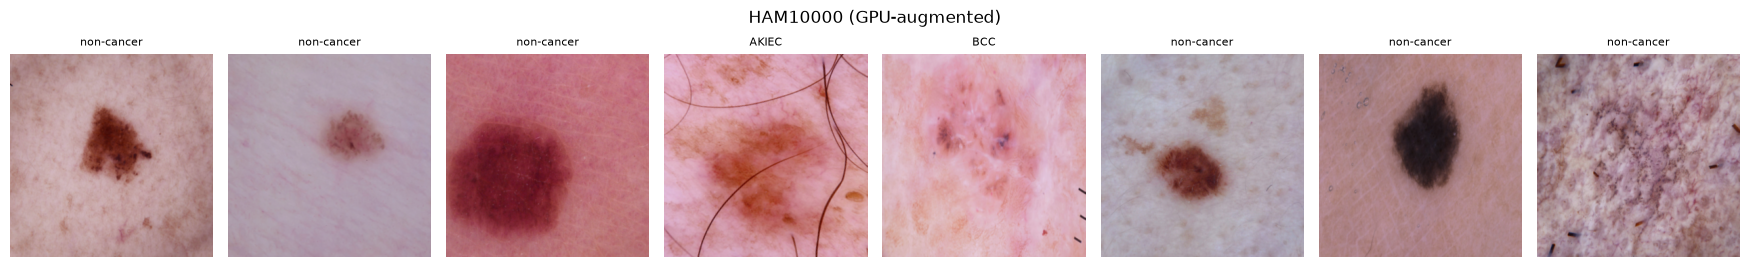

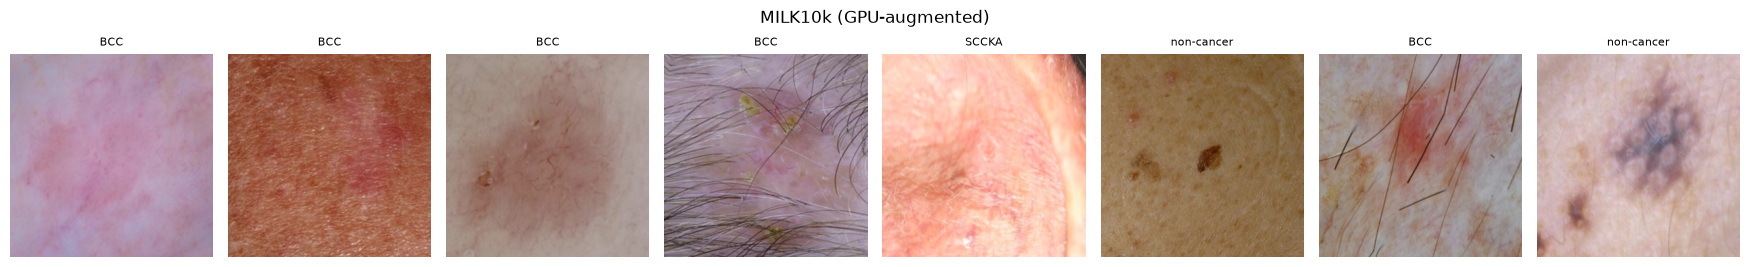

In [10]:
class PinnedStager:
    """Double-buffered pinned host staging: RAM pool -> pinned buffer -> async H2D copy."""

    def __init__(self, max_batch):
        shape = tuple(GLOBAL_POOL.shape[1:])
        self.bufs = [torch.empty((max_batch, *shape), dtype=torch.uint8).pin_memory() for _ in range(2)]
        self.events = [None, None]
        self.i = 0
        self.max_batch = max_batch

    def fetch(self, gidx_cpu):
        k = int(gidx_cpu.numel())
        assert k <= self.max_batch, (k, self.max_batch)
        i = self.i
        self.i ^= 1
        if self.events[i] is not None:
            self.events[i].synchronize()
        buf = self.bufs[i][:k]
        torch.index_select(GLOBAL_POOL, 0, gidx_cpu, out=buf)
        x = buf.to(device, non_blocking=True)
        ev = torch.cuda.Event()
        ev.record()
        self.events[i] = ev
        return x


TRAIN_STAGER = PinnedStager(BATCH_SIZE)
EVAL_STAGER = PinnedStager(EVAL_BATCH_SIZE)


def maybe_subsample(df, seed):
    if SMOKE_MAX_TRAIN is None or len(df) <= SMOKE_MAX_TRAIN:
        return df
    return df.sample(SMOKE_MAX_TRAIN, random_state=seed).reset_index(drop=True)


class GPUBatcher:
    def __init__(self, gidx, labels, batch_size, shuffle=True, drop_last=True, seed=0):
        self.gidx = torch.as_tensor(np.asarray(gidx, dtype=np.int64))
        self.labels_gpu = torch.as_tensor(np.asarray(labels, dtype=np.int64)).to(device)
        self.bs = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last and len(self.gidx) >= batch_size
        self.seed = int(seed)
        self.epoch = 0

    def __len__(self):
        n = len(self.gidx)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def __iter__(self):
        n = len(self.gidx)
        if self.shuffle:
            g = torch.Generator()
            g.manual_seed(self.seed * 100003 + self.epoch)
            order = torch.randperm(n, generator=g)
        else:
            order = torch.arange(n)
        self.epoch += 1
        order_gpu = order.to(device)
        gidx_ordered = self.gidx[order].contiguous()
        for b in range(len(self)):
            s, e = b * self.bs, min((b + 1) * self.bs, n)
            yield TRAIN_STAGER.fetch(gidx_ordered[s:e]), self.labels_gpu[order_gpu[s:e]]


class GPUReplayBuffer:
    """Small exemplar memory kept entirely in VRAM (200 images x 336^2 x 3 bytes ~ 68 MB)."""

    def __init__(self, gidx, labels):
        self.x = GLOBAL_POOL.index_select(0, torch.as_tensor(np.asarray(gidx, dtype=np.int64))).to(device)
        self.y = torch.as_tensor(np.asarray(labels, dtype=np.int64), device=device)

    def sample(self, k, gen):
        idx = torch.randint(0, self.x.shape[0], (k,), device=device, generator=gen)
        return self.x[idx], self.y[idx]


def _normalize(x):
    return (x - IMAGENET_MEAN_T) / IMAGENET_STD_T


@torch.no_grad()
def gpu_train_augment(x_u8, gen):
    B = x_u8.shape[0]
    x = x_u8.permute(0, 3, 1, 2).float().div_(255.0)

    def U(lo, hi):
        return torch.rand(B, device=device, generator=gen) * (hi - lo) + lo

    area = U(*AUG_AREA)
    ratio = torch.exp(U(math.log(3 / 4), math.log(4 / 3)))
    sw = torch.sqrt(area * ratio).clamp(max=1.0)
    sh = torch.sqrt(area / ratio).clamp(max=1.0)
    tx = U(-1.0, 1.0) * (1.0 - sw)
    ty = U(-1.0, 1.0) * (1.0 - sh)
    ang = U(-AUG_ROT_DEG, AUG_ROT_DEG) * (math.pi / 180.0)
    fx = 1.0 - 2.0 * (torch.rand(B, device=device, generator=gen) < 0.5).float()
    fy = 1.0 - 2.0 * (torch.rand(B, device=device, generator=gen) < 0.5).float()
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([
        torch.stack([cos * sw * fx, -sin * sh * fy, tx], dim=1),
        torch.stack([sin * sw * fx, cos * sh * fy, ty], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, (B, 3, IMG_SIZE, IMG_SIZE), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    x = x * U(1 - AUG_BRIGHTNESS, 1 + AUG_BRIGHTNESS).view(B, 1, 1, 1)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * U(1 - AUG_CONTRAST, 1 + AUG_CONTRAST).view(B, 1, 1, 1) + m
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    x = (x - gray) * U(1 - AUG_SATURATION, 1 + AUG_SATURATION).view(B, 1, 1, 1) + gray
    return _normalize(x.clamp_(0.0, 1.0)).contiguous(memory_format=MEMORY_FORMAT)


@torch.no_grad()
def gpu_eval_preprocess(x_u8):
    x = x_u8.permute(0, 3, 1, 2).float().div_(255.0)
    if x.shape[-1] != IMG_SIZE:
        x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False, antialias=True)
    return _normalize(x).contiguous(memory_format=MEMORY_FORMAT)


def show_augmented(df, class_list, title, n=8, seed=SEEDS[0]):
    sample = df.sample(min(n, len(df)), random_state=seed).reset_index(drop=True)
    g = torch.Generator(device=device)
    g.manual_seed(seed)
    x = gpu_train_augment(TRAIN_STAGER.fetch(torch.as_tensor(sample["gidx"].values[:BATCH_SIZE])), g)
    x = (x * IMAGENET_STD_T + IMAGENET_MEAN_T).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
    fig, axes = plt.subplots(1, len(sample), figsize=(2.2 * len(sample), 2.7))
    for ax, img, lab in zip(np.atleast_1d(axes), x, sample["label"]):
        ax.imshow(img)
        ax.set_title(lab, fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_augmented(ham_train_df, HAM_CLASSES, "HAM10000 (GPU-augmented)")
show_augmented(_preview["train"], MILK_CLASSES, "MILK10k (GPU-augmented)")

## 10. Model, classifier expansion, EMA, optimiser

In [11]:
class CancerILModel(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        weights = tv_models.EfficientNet_B3_Weights.DEFAULT if pretrained else None
        backbone = tv_models.efficientnet_b3(weights=weights)
        self.features = backbone.features
        self.avgpool = backbone.avgpool
        self.embed_dim = backbone.classifier[1].in_features
        self.dropout = nn.Dropout(p=0.3)
        self.classifier = nn.Linear(self.embed_dim, num_classes)

    def forward(self, x, return_embedding=False):
        pooled = torch.flatten(self.avgpool(self.features(x)), 1)
        logits = self.classifier(self.dropout(pooled))
        return (logits, pooled) if return_embedding else logits


def build_model(num_classes, pretrained):
    return CancerILModel(num_classes, pretrained=pretrained).to(device).to(memory_format=MEMORY_FORMAT)


def expand_classifier(old_model, old_classes, new_classes):
    """Copy the Stage-1 backbone and the rows of shared classes into a larger head."""
    new_model = CancerILModel(len(new_classes), pretrained=False)
    new_model.features.load_state_dict(old_model.features.state_dict())
    with torch.no_grad():
        for j, c in enumerate(new_classes):
            if c in old_classes:
                i = old_classes.index(c)
                new_model.classifier.weight[j].copy_(old_model.classifier.weight[i])
                new_model.classifier.bias[j].copy_(old_model.classifier.bias[i])
    return new_model.to(device).to(memory_format=MEMORY_FORMAT)


class ModelEMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = float(decay)
        esd, msd = self.module.state_dict(), model.state_dict()
        self.float_pairs = [(esd[k], msd[k]) for k in esd if esd[k].dtype.is_floating_point]
        self.other_pairs = [(esd[k], msd[k]) for k in esd if not esd[k].dtype.is_floating_point]

    @torch.no_grad()
    def update(self):
        torch._foreach_lerp_([e for e, _ in self.float_pairs], [m for _, m in self.float_pairs], 1.0 - self.decay)
        for e, m in self.other_pairs:
            e.copy_(m)


def make_optimizer(model, lr_backbone, lr_head):
    groups = [
        {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": lr_backbone},
        {"params": [p for p in model.classifier.parameters() if p.requires_grad], "lr": lr_head},
    ]
    try:
        return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY, fused=True)
    except (TypeError, RuntimeError):
        return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)


def make_scheduler(opt, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.01, 0.5 * (1.0 + math.cos(math.pi * min(1.0, t))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


def state_dict_cpu(model):
    return {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}


def load_state_dict_compat(path):
    return torch.load(path, map_location=device, weights_only=True)

## 11. Inference, metrics and statistics

Every run saves its raw probability arrays, so every table and figure below can be recomputed without touching the GPU. Statistical tools: DeLong AUROC CIs and paired DeLong tests, sensitivity at fixed specificity, validation-derived thresholds, paired t / Wilcoxon tests with Holm correction.

In [12]:
@torch.no_grad()
def predict_probs(model, gidx, tta=False):
    model.eval()
    g = torch.as_tensor(np.asarray(gidx, dtype=np.int64))
    outs = []
    for s in range(0, len(g), EVAL_BATCH_SIZE):
        x = gpu_eval_preprocess(EVAL_STAGER.fetch(g[s:s + EVAL_BATCH_SIZE]))
        views = [x, x.flip(3), x.flip(2), x.flip(2).flip(3)] if tta else [x]
        p = None
        with torch.autocast("cuda", dtype=AMP):
            for v in views:
                q = F.softmax(model(v).float(), dim=1)
                p = q if p is None else p + q
        outs.append(p / len(views))
    if not outs:
        return np.zeros((0, model.classifier.out_features), dtype=np.float32)
    return torch.cat(outs).cpu().numpy().astype(np.float32)


@torch.no_grad()
def extract_embeddings(model, gidx):
    model.eval()
    g = torch.as_tensor(np.asarray(gidx, dtype=np.int64))
    outs = []
    for s in tqdm(range(0, len(g), EVAL_BATCH_SIZE), desc="Embeddings", leave=False):
        x = gpu_eval_preprocess(EVAL_STAGER.fetch(g[s:s + EVAL_BATCH_SIZE]))
        with torch.autocast("cuda", dtype=AMP):
            _, e = model(x, return_embedding=True)
        outs.append(e.float())
    return torch.cat(outs)


def pad_to_milk(p_old):
    """Place Stage-1 (4-class) probabilities into the Stage-2 class space (new classes = 0)."""
    out = np.zeros((p_old.shape[0], len(MILK_CLASSES)), dtype=np.float32)
    out[:, OLD_IDX_IN_NEW] = p_old
    return out


def hmean(a, b):
    return float(2 * a * b / (a + b)) if (a + b) > 0 else 0.0


def bal_acc(y, pred, classes=None):
    y, pred = np.asarray(y), np.asarray(pred)
    cls = np.unique(y) if classes is None else [c for c in classes if (y == c).any()]
    return float(np.mean([(pred[y == c] == c).mean() for c in cls])) if len(cls) else float("nan")


def multiclass_ece(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def binary_ece(p, y, n_bins=15):
    p, y = np.asarray(p, float), np.asarray(y, int)
    pred = (p >= 0.5).astype(int)
    conf = np.where(pred == 1, p, 1 - p)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def multiclass_summary(probs, y, class_list):
    y = np.asarray(y)
    pred = probs.argmax(1)
    present = [i for i in range(len(class_list)) if (y == i).any()]
    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=present, zero_division=0)
    per_class = pd.DataFrame({
        "class": [class_list[i] for i in present], "precision": prec, "recall": rec, "f1": f1, "support": sup,
    })
    return {
        "acc": float((pred == y).mean()),
        "bal_acc": bal_acc(y, pred, present),
        "macro_f1": float(np.mean(f1)) if len(f1) else float("nan"),
        "ece": multiclass_ece(probs, y),
        "per_class": per_class,
        "pred": pred,
    }


def lesion_aggregate(img_df, probs):
    """Average image probabilities within each lesion -> one decision per lesion."""
    tmp = pd.DataFrame(probs, columns=list(range(probs.shape[1])))
    tmp["lesion_id"] = img_df["lesion_id"].values
    g = tmp.groupby("lesion_id", sort=True).mean()
    labels = img_df.groupby("lesion_id", sort=True)["label"].first().loc[g.index]
    y = np.array([MILK_CLASSES.index(l) for l in labels])
    return g.to_numpy(dtype=np.float64), y, g.index.to_numpy()


def binary_at_threshold(y, p, thr):
    y, pred = np.asarray(y, int), (np.asarray(p, float) >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    sens = tp / (tp + fn) if (tp + fn) else float("nan")
    spec = tn / (tn + fp) if (tn + fp) else float("nan")
    ppv = tp / (tp + fp) if (tp + fp) else float("nan")
    return {"sens": sens, "spec": spec, "ppv": ppv, "bal_acc": (sens + spec) / 2}


def threshold_for_sensitivity(y, p, target):
    """Largest threshold whose sensitivity on (y, p) is >= target (predict positive if p >= thr)."""
    pos = np.sort(np.asarray(p, float)[np.asarray(y) == 1])
    if len(pos) == 0:
        return 0.5
    k = int(np.floor((1.0 - target) * len(pos)))
    return float(pos[min(max(k, 0), len(pos) - 1)])


def sens_at_spec(y, p, spec):
    if len(np.unique(y)) < 2:
        return float("nan")
    fpr, tpr, _ = roc_curve(y, p)
    ok = fpr <= (1.0 - spec) + 1e-12
    return float(tpr[ok].max()) if ok.any() else 0.0


# ---------- DeLong (Sun & Xu, 2014, fast algorithm) ----------
def _midrank(x):
    order = np.argsort(x, kind="mergesort")
    z = x[order]
    n = len(x)
    t = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = t
    return out


def _fast_delong(preds, m):
    """preds: (k, n) with the m positives in the first m columns."""
    k, n_all = preds.shape
    n = n_all - m
    pos, neg = preds[:, :m], preds[:, m:]
    tx = np.array([_midrank(pos[r]) for r in range(k)])
    ty = np.array([_midrank(neg[r]) for r in range(k)])
    tz = np.array([_midrank(preds[r]) for r in range(k)])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return aucs, cov


def delong_auc_ci(y, p, alpha=0.95):
    y, p = np.asarray(y, int), np.asarray(p, float)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    order = np.argsort(-y, kind="mergesort")
    aucs, cov = _fast_delong(p[order][None, :], int(y.sum()))
    se = math.sqrt(max(cov[0, 0], 0.0))
    z = stats.norm.ppf(1 - (1 - alpha) / 2)
    return float(aucs[0]), float(max(0.0, aucs[0] - z * se)), float(min(1.0, aucs[0] + z * se))


def delong_test(y, p1, p2):
    """Two-sided paired DeLong test. Returns (auc1, auc2, p_value)."""
    y = np.asarray(y, int)
    order = np.argsort(-y, kind="mergesort")
    preds = np.vstack([np.asarray(p1, float), np.asarray(p2, float)])[:, order]
    aucs, cov = _fast_delong(preds, int(y.sum()))
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 1e-15:
        return float(aucs[0]), float(aucs[1]), 1.0
    z = abs(aucs[0] - aucs[1]) / math.sqrt(var)
    return float(aucs[0]), float(aucs[1]), float(2 * stats.norm.sf(z))


def t_ci(vals, alpha=0.95):
    v = np.asarray(vals, float)
    v = v[np.isfinite(v)]
    n = len(v)
    if n == 0:
        return float("nan"), float("nan"), float("nan"), float("nan")
    mean = float(v.mean())
    if n == 1:
        return mean, float("nan"), float("nan"), float("nan")
    sd = float(v.std(ddof=1))
    half = stats.t.ppf(1 - (1 - alpha) / 2, n - 1) * sd / math.sqrt(n)
    return mean, sd, mean - half, mean + half


def holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    idx = np.where(ok)[0]
    if len(idx) == 0:
        return out
    order = idx[np.argsort(p[idx])]
    m = len(order)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out

## 12. Generic GPU trainer (bf16 autocast, weight EMA, early stopping)

The training loop never calls `.item()` per step; losses are accumulated on the GPU and read once per epoch. Model selection is done on the EMA weights.

In [13]:
def fit(model, loader, compute_loss, val_fn, *, epochs, patience, lr_backbone, lr_head, seed, desc, verbose=True):
    opt = make_optimizer(model, lr_backbone, lr_head)
    steps = len(loader)
    sched = make_scheduler(opt, epochs * steps, WARMUP_EPOCHS * steps)
    ema = ModelEMA(model, 0.5 ** (1.0 / max(1.0, EMA_HALFLIFE_EPOCHS * steps)))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    gen = torch.Generator(device=device)
    gen.manual_seed(int(seed))

    best_score, best_state, best_info, wait, history = -np.inf, None, {}, 0, []
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        run_loss = torch.zeros((), device=device)
        part_sums, n_steps = {}, 0
        pbar = tqdm(loader, total=steps, desc=f"{desc} e{epoch:02d}", leave=False)
        for x_u8, y in pbar:
            x = gpu_train_augment(x_u8, gen)
            with torch.autocast("cuda", dtype=AMP):
                loss, parts = compute_loss(model, x, y, gen)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(opt)
            scaler.update()
            sched.step()
            ema.update()
            run_loss += loss.detach()
            for k, v in parts.items():
                part_sums[k] = part_sums.get(k, 0.0) + v.detach()
            n_steps += 1
            if n_steps % 50 == 0:
                pbar.set_postfix(loss=f"{(run_loss / n_steps).item():.4f}")

        train_loss = float((run_loss / max(n_steps, 1)).item())
        if not math.isfinite(train_loss):
            raise FloatingPointError(f"{desc}: non-finite training loss at epoch {epoch}")
        score, info = val_fn(ema.module)
        score = float(score) if np.isfinite(score) else -1.0
        row = {
            "epoch": epoch, "train_loss": train_loss,
            **{f"train_{k}": float((v / n_steps).item()) for k, v in part_sums.items()},
            "val_score": score, **{f"val_{k}": v for k, v in info.items()},
            "lr_backbone": opt.param_groups[0]["lr"], "sec": time.time() - t0,
        }
        history.append(row)
        improved = score > best_score + 1e-6
        if improved:
            best_score, best_info, best_state, wait = score, dict(info), state_dict_cpu(ema.module), 0
        else:
            wait += 1
        if verbose:
            print(f"[{desc}] ep{epoch:02d} loss={train_loss:.4f} val={score:.4f}{' *' if improved else ''} ({row['sec']:.0f}s)")
        if wait >= patience:
            break

    model.load_state_dict(best_state)
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3
    del ema, opt
    return model, pd.DataFrame(history), best_score, best_info, peak_gb


def class_weights_for(labels, n_classes, cancer_w=1.0, cancer_idx=()):
    counts = np.bincount(np.asarray(labels, dtype=np.int64), minlength=n_classes).astype(float)
    w = np.ones(n_classes)
    present = counts > 0
    if CLASS_BALANCED_CE and present.any():
        w[present] = np.sqrt(counts[present].sum() / counts[present])
        w[present] *= counts[present].sum() / (w[present] * counts[present]).sum()
    for c in cancer_idx:
        w[c] *= cancer_w
    return torch.tensor(w, dtype=torch.float32, device=device)

## 13. Stage 1: HAM10000 (one model per replicate seed)

In [14]:
def train_stage1(seed):
    ckpt = CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.pt"
    pred_path = PRED_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.npz"
    if ckpt.exists():
        model = build_model(len(HAM_CLASSES), pretrained=False)
        model.load_state_dict(load_state_dict_compat(ckpt))
        print(f"Loaded Stage-1 checkpoint for seed {seed}")
    else:
        set_seed(seed)
        model = build_model(len(HAM_CLASSES), pretrained=USE_IMAGENET_WEIGHTS)
        tr = maybe_subsample(ham_train_df, seed)
        y_tr = tr["label"].map(HAM_CLASSES.index).values
        y_val = ham_val_df["label"].map(HAM_CLASSES.index).values
        loader = GPUBatcher(tr["gidx"].values, y_tr, BATCH_SIZE, shuffle=True, drop_last=True, seed=seed)
        cw = class_weights_for(y_tr, len(HAM_CLASSES))

        def compute_loss(m, x, y, gen):
            ce = F.cross_entropy(m(x).float(), y, weight=cw)
            return ce, {"ce": ce}

        def val_fn(m):
            s = multiclass_summary(predict_probs(m, ham_val_df["gidx"].values), y_val, HAM_CLASSES)
            return s["macro_f1"], {"acc": s["acc"], "bal_acc": s["bal_acc"], "macro_f1": s["macro_f1"]}

        model, hist, best, info, peak = fit(
            model, loader, compute_loss, val_fn, epochs=STAGE1_EPOCHS, patience=STAGE1_PATIENCE,
            lr_backbone=LR_BACKBONE_S1, lr_head=LR_HEAD_S1, seed=seed, desc=f"Stage1 s{seed}",
        )
        torch.save(model.state_dict(), ckpt)
        hist.to_csv(RESULT_DIR / f"stage1_history_{STAGE1_TAG}_seed{seed}.csv", index=False)
        print(f"Stage 1 seed {seed}: best HAM-val macro-F1 = {best:.4f} | peak VRAM {peak:.2f} GB")

    if not pred_path.exists():
        split = make_milk_split(seed)
        preds = {
            "ham_val": predict_probs(model, ham_val_df["gidx"].values, tta=EVAL_TTA),
            "ham_test": predict_probs(model, ham_test_df["gidx"].values, tta=EVAL_TTA),
            "milk_val": predict_probs(model, split["val"]["gidx"].values, tta=EVAL_TTA),
            "milk_test": predict_probs(model, split["test"]["gidx"].values, tta=EVAL_TTA),
            "ddi": predict_probs(model, ddi_df["gidx"].values, tta=EVAL_TTA),
        }
        np.savez_compressed(pred_path, **preds)
    del model
    torch.cuda.empty_cache()


for seed in SEEDS:
    train_stage1(seed)

y_ham_test_4 = ham_test_df["label"].map(HAM_CLASSES.index).values
rows = []
for seed in SEEDS:
    p = np.load(PRED_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.npz")["ham_test"]
    s = multiclass_summary(p, y_ham_test_4, HAM_CLASSES)
    rows.append({"seed": seed, "acc": s["acc"], "bal_acc": s["bal_acc"], "macro_f1": s["macro_f1"], "ece": s["ece"]})
stage1_table = pd.DataFrame(rows)
stage1_table.to_csv(RESULT_DIR / "stage1_ham_test_by_seed.csv", index=False)
display(stage1_table.round(4))
print("Stage-1 HAM test (mean ± SD): " + ", ".join(
    f"{m}={stage1_table[m].mean():.4f}±{stage1_table[m].std(ddof=1) if len(stage1_table) > 1 else float('nan'):.4f}"
    for m in ["acc", "bal_acc", "macro_f1"]
))

Loaded Stage-1 checkpoint for seed 42
Loaded Stage-1 checkpoint for seed 1337
Loaded Stage-1 checkpoint for seed 2026
Loaded Stage-1 checkpoint for seed 7
Loaded Stage-1 checkpoint for seed 314


,seed,acc,bal_acc,macro_f1,ece
0,42,0.8604,0.7980,0.7373,0.0256
1,1337,0.8810,0.7718,0.7647,0.0736
2,2026,0.8829,0.7475,0.7485,0.0713
3,7,0.8909,0.7861,0.7774,0.0530
4,314,0.8783,0.7817,0.7566,0.0512


Stage-1 HAM test (mean ± SD): acc=0.8787±0.0112, bal_acc=0.7770±0.0190, macro_f1=0.7569±0.0153


## 14. Stage-2 components: teacher, prototypes, herding exemplars, Fisher, losses

Everything per seed comes from that seed's Stage-1 model and is cached on disk. The prototypes and the herding exemplar set (iCaRL herding on L2-normalised Stage-1 embeddings, `REPLAY_PER_CLASS` per old class) are computed once. The diagonal Fisher for EWC uses labels sampled from the model's predictive distribution on up to `FISHER_MAX_IMAGES` HAM training images.

In [15]:
def herding_select(feats, m):
    mu = feats.mean(0)
    running = np.zeros_like(mu)
    avail = np.ones(len(feats), dtype=bool)
    chosen = []
    for k in range(1, m + 1):
        d = (((running[None, :] + feats) / k - mu[None, :]) ** 2).sum(1)
        d[~avail] = np.inf
        i = int(np.argmin(d))
        chosen.append(i)
        avail[i] = False
        running += feats[i]
    return chosen


_SEED_CACHE = {}


def get_seed_resources(seed):
    if seed in _SEED_CACHE:
        return _SEED_CACHE[seed]
    _SEED_CACHE.clear()
    gc.collect()
    torch.cuda.empty_cache()

    stage1 = build_model(len(HAM_CLASSES), pretrained=False)
    stage1.load_state_dict(load_state_dict_compat(CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.pt"))
    stage1.eval()
    for p in stage1.parameters():
        p.requires_grad_(False)

    proto_path = CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{seed}_prototypes.npz"
    buffer_path = CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{seed}_herding_buffer.csv"
    if not (proto_path.exists() and buffer_path.exists()):
        emb = extract_embeddings(stage1, ham_train_df["gidx"].values).cpu().numpy()
        labels = ham_train_df["label"].values
        np.savez(proto_path, **{c: emb[labels == c].mean(0) for c in HAM_CLASSES})
        rows = []
        for c in HAM_CLASSES:
            idx = np.where(labels == c)[0]
            f = emb[idx] / np.clip(np.linalg.norm(emb[idx], axis=1, keepdims=True), 1e-12, None)
            for j in herding_select(f, min(REPLAY_PER_CLASS, len(idx))):
                rows.append({"gidx": int(ham_train_df["gidx"].values[idx[j]]), "label": c})
        pd.DataFrame(rows).to_csv(buffer_path, index=False)

    protos = np.load(proto_path)
    proto_mat = torch.zeros(len(MILK_CLASSES), stage1.embed_dim, device=device)
    has_proto = torch.zeros(len(MILK_CLASSES), dtype=torch.bool, device=device)
    for c in HAM_CLASSES:
        i = MILK_CLASSES.index(c)
        proto_mat[i] = torch.as_tensor(protos[c], device=device)
        has_proto[i] = True
    buf = pd.read_csv(buffer_path)
    buffer = GPUReplayBuffer(buf["gidx"].values, buf["label"].map(MILK_CLASSES.index).values)

    res = SimpleNamespace(
        seed=seed, stage1=stage1, proto_mat=proto_mat, has_proto=has_proto.float(),
        buffer=buffer, split=make_milk_split(seed), fisher=None,
    )
    _SEED_CACHE[seed] = res
    return res


def get_fisher(res):
    if res.fisher is not None:
        return res.fisher
    path = CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{res.seed}_fisher.pt"
    if path.exists():
        fisher = {k: v.to(device) for k, v in torch.load(path, map_location="cpu", weights_only=True).items()}
    else:
        model = copy.deepcopy(res.stage1).eval()
        for p in model.parameters():
            p.requires_grad_(True)
        fisher = {n: torch.zeros_like(p, dtype=torch.float32) for n, p in model.named_parameters()}
        rng = np.random.default_rng(res.seed)
        pick = rng.choice(len(ham_train_df), size=min(FISHER_MAX_IMAGES, len(ham_train_df)), replace=False)
        g = torch.as_tensor(ham_train_df["gidx"].values[pick])
        gen = torch.Generator(device=device)
        gen.manual_seed(res.seed)
        n_seen = 0
        for s in tqdm(range(0, len(g), BATCH_SIZE), desc="Fisher", leave=False):
            x = gpu_eval_preprocess(EVAL_STAGER.fetch(g[s:s + BATCH_SIZE]))
            model.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=AMP):
                logits = model(x).float()
            y = torch.multinomial(F.softmax(logits.detach(), 1), 1, generator=gen).squeeze(1)
            F.cross_entropy(logits, y).backward()
            for n, p in model.named_parameters():
                if p.grad is not None:
                    fisher[n] += p.grad.float().pow(2) * x.shape[0]
            n_seen += x.shape[0]
        fisher = {n: f / n_seen for n, f in fisher.items()}
        torch.save({k: v.cpu() for k, v in fisher.items()}, path)
        del model
    star = {n: p.detach().clone().float() for n, p in res.stage1.named_parameters()}
    res.fisher = (fisher, star)
    return res.fisher


OLD_IDX_T = torch.tensor(OLD_IDX_IN_NEW, device=device)


def kd_loss(student_logits, teacher_logits, T=KD_TEMP):
    s = student_logits[:, OLD_IDX_T]
    return F.kl_div(F.log_softmax(s / T, 1), F.softmax(teacher_logits / T, 1), reduction="batchmean") * T * T


def cancer_fn_loss(logits, labels):
    """Penalise non-cancer probability mass on true-cancer samples: mean of -log(1 - p_noncancer)."""
    is_cancer = (labels != NC_IDX).float()
    p_nc = F.softmax(logits, 1)[:, NC_IDX].clamp(1e-6, 1 - 1e-6)
    return (-torch.log1p(-p_nc) * is_cancer).sum() / is_cancer.sum().clamp(min=1.0)


def prototype_loss(emb, labels, proto_mat, has_proto):
    mask = has_proto[labels]
    d = (emb - proto_mat[labels]).pow(2).mean(1)
    return (d * mask).sum() / mask.sum().clamp(min=1.0)


def ewc_penalty(model, fisher, star):
    total = torch.zeros((), device=device)
    for n, p in model.named_parameters():
        if n not in fisher:
            continue
        q = p[OLD_IDX_T] if n.startswith("classifier.") else p
        total = total + (fisher[n] * (q.float() - star[n]).pow(2)).sum()
    return 0.5 * total

## 15. Protocols and the Stage-2 run manager

| Protocol | Stage-2 training data | What it tests |
|---|---|---|
| **CDI** (class + domain incremental) | All MILK10k training classes. Old classes recur from a new source. | Your original setting, described honestly. Forgetting here mixes interference with domain shift. |
| **STRICT** (cancer-class incremental) | MILK10k `SCCKA` + `non-cancer` only. Old cancer classes (MEL, BCC, AKIEC) are **absent**. | Classic catastrophic forgetting of old cancer types. The harder, standard CL benchmark. |

In both protocols, evaluation covers **all** classes. Every run is identified by a hash of (protocol, seed, method spec, global config). Finished runs are never recomputed, so the notebook can be stopped and resumed at any point.

In [16]:
_NUMERIC_SPEC = ["kd", "proto", "fn", "ewc", "cancer_w", "der_alpha", "der_beta"]


def spec(**kw):
    base = dict(kd=0.0, proto=0.0, fn=0.0, ewc=0.0, cancer_w=1.0, replay="none", der_alpha=0.0, der_beta=0.0, joint=False)
    unknown = set(kw) - set(base)
    assert not unknown, unknown
    base.update(kw)
    for k in _NUMERIC_SPEC:
        base[k] = float(base[k])
    return base


CONFIG_SIGNATURE = hashlib.sha1(json.dumps({
    "smoke": SMOKE_TEST, "smoke_max": SMOKE_MAX_TRAIN, "img": IMG_SIZE, "cache": CACHE_SIZE, "bs": BATCH_SIZE,
    "rbs": REPLAY_BATCH_SIZE, "e2": STAGE2_EPOCHS, "p2": STAGE2_PATIENCE, "lr2": [LR_BACKBONE_S2, LR_HEAD_S2],
    "wd": WEIGHT_DECAY, "ema": EMA_HALFLIFE_EPOCHS, "cb": CLASS_BALANCED_CE, "sel": SELECTION, "T": KD_TEMP,
    "aug": [AUG_AREA, AUG_ROT_DEG, AUG_BRIGHTNESS, AUG_CONTRAST, AUG_SATURATION], "tta": EVAL_TTA,
    "classes": MILK_CLASSES, "mod": STAGE2_MODALITY, "rpc": REPLAY_PER_CLASS, "ham_val": HAM_VAL_SOURCE,
}, sort_keys=True).encode()).hexdigest()[:8]


def run_key(protocol, seed, sp):
    h = hashlib.sha1(json.dumps(sp, sort_keys=True).encode()).hexdigest()[:10]
    return f"{protocol}__{h}__{CONFIG_SIGNATURE}__s{seed}"


def visible_classes(protocol):
    if protocol == "CDI":
        return list(MILK_CLASSES)
    if protocol == "STRICT":
        return NEW_CLASSES + ["non-cancer"]
    raise ValueError(protocol)


def run_stage2(protocol, seed, sp, tag=""):
    key = run_key(protocol, seed, sp)
    summ_path = RUNS_DIR / f"{key}.json"
    if summ_path.exists():
        with open(summ_path, encoding="utf-8") as f:
            return json.load(f)

    t_start = time.time()
    res = get_seed_resources(seed)
    vis = visible_classes(protocol)
    tr_df = res.split["train"][res.split["train"]["label"].isin(vis)].reset_index(drop=True)
    va_df = res.split["val"][res.split["val"]["label"].isin(vis)].reset_index(drop=True)
    if sp["joint"]:
        tr_df = pd.concat([ham_train_df[["gidx", "label"]], tr_df[["gidx", "label"]]], ignore_index=True)
    tr_df = maybe_subsample(tr_df, seed)
    y_tr = tr_df["label"].map(MILK_CLASSES.index).values
    y_va = va_df["label"].map(MILK_CLASSES.index).values
    y_hv = ham_val_df["label"].map(MILK_CLASSES.index).values

    set_seed(seed)
    model = expand_classifier(res.stage1, HAM_CLASSES, MILK_CLASSES)
    loader = GPUBatcher(tr_df["gidx"].values, y_tr, BATCH_SIZE, shuffle=True, drop_last=True, seed=seed)
    cw = class_weights_for(y_tr, len(MILK_CLASSES), sp["cancer_w"], CANCER_IDX)
    teacher = res.stage1 if (sp["kd"] > 0 or sp["replay"] == "derpp") else None
    fisher = get_fisher(res) if sp["ewc"] > 0 else None
    buffer = res.buffer if sp["replay"] in ("er", "derpp") else None

    def compute_loss(m, x, y, gen):
        n = x.shape[0]
        yr = None
        if buffer is not None:
            with torch.autocast("cuda", enabled=False):
                xr_u8, yr = buffer.sample(REPLAY_BATCH_SIZE, gen)
                xr = gpu_train_augment(xr_u8, gen)
            X = torch.cat([x, xr])
        else:
            X = x
        logits, emb = m(X, return_embedding=True)
        logits, emb = logits.float(), emb.float()
        lc = logits[:n]
        parts = {}
        ce = F.cross_entropy(lc, y, weight=cw)
        parts["ce"] = ce
        loss = ce
        t_logits = None
        if teacher is not None:
            with torch.no_grad():
                t_logits = teacher(X).float()
        if sp["replay"] == "er":
            ce_r = F.cross_entropy(logits[n:], yr)
            parts["replay_ce"] = ce_r
            loss = loss + ce_r
        elif sp["replay"] == "derpp":
            mse = F.mse_loss(logits[n:][:, OLD_IDX_T], t_logits[n:])
            ce_r = F.cross_entropy(logits[n:], yr)
            parts["der_mse"], parts["replay_ce"] = mse, ce_r
            loss = loss + sp["der_alpha"] * mse + sp["der_beta"] * ce_r
        if sp["kd"] > 0:
            l = kd_loss(lc, t_logits[:n])
            parts["kd"] = l
            loss = loss + sp["kd"] * l
        if sp["proto"] > 0:
            l = prototype_loss(emb[:n], y, res.proto_mat, res.has_proto)
            parts["proto"] = l
            loss = loss + sp["proto"] * l
        if sp["fn"] > 0:
            l = cancer_fn_loss(logits, torch.cat([y, yr])) if sp["replay"] == "er" else cancer_fn_loss(lc, y)
            parts["fn"] = l
            loss = loss + sp["fn"] * l
        if fisher is not None:
            l = ewc_penalty(m, *fisher)
            parts["ewc"] = l
            loss = loss + sp["ewc"] * l
        return loss, parts

    def val_fn(m):
        new_s = bal_acc(y_va, predict_probs(m, va_df["gidx"].values).argmax(1))
        info = {"milk_val_bal_acc": new_s}
        if SELECTION == "joint_val":
            old_s = bal_acc(y_hv, predict_probs(m, ham_val_df["gidx"].values).argmax(1))
            info["ham_val_bal_acc"] = old_s
            return hmean(old_s, new_s), info
        return new_s, info

    model, hist, best, info, peak = fit(
        model, loader, compute_loss, val_fn, epochs=STAGE2_EPOCHS, patience=STAGE2_PATIENCE,
        lr_backbone=LR_BACKBONE_S2, lr_head=LR_HEAD_S2, seed=seed, desc=f"{protocol}|{tag}|s{seed}",
        verbose=VERBOSE_EPOCHS,
    )

    preds = {
        "ham_val": predict_probs(model, ham_val_df["gidx"].values, tta=EVAL_TTA),
        "ham_test": predict_probs(model, ham_test_df["gidx"].values, tta=EVAL_TTA),
        "milk_val": predict_probs(model, res.split["val"]["gidx"].values, tta=EVAL_TTA),
        "milk_test": predict_probs(model, res.split["test"]["gidx"].values, tta=EVAL_TTA),
        "ddi": predict_probs(model, ddi_df["gidx"].values, tta=EVAL_TTA),
    }
    np.savez_compressed(PRED_DIR / f"{key}.npz", **preds)
    if SAVE_STAGE2_CHECKPOINTS:
        torch.save(model.state_dict(), CKPT_DIR / "stage2" / f"{key}.pt")
    hist.to_csv(RUNS_DIR / f"{key}_history.csv", index=False)

    summary = {
        "key": key, "protocol": protocol, "seed": int(seed), "tag": tag, "spec": sp,
        "best_val_score": float(best), "best_val_info": {k: float(v) for k, v in info.items()},
        "epochs_run": int(len(hist)), "train_images": int(len(tr_df)),
        "peak_vram_gb": round(float(peak), 2), "minutes": round((time.time() - t_start) / 60, 2),
    }
    tmp = summ_path.with_suffix(".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)
    os.replace(tmp, summ_path)
    print(f"[done] {protocol:6s} | {tag:28s} | seed {seed} | val={best:.4f} | {summary['epochs_run']} ep | "
          f"{summary['minutes']:.1f} min | peak {summary['peak_vram_gb']} GB")
    del model, preds
    gc.collect()
    torch.cuda.empty_cache()
    return summary

## 16. Method registry

| Group | Method | Loss |
|---|---|---|
| Reference | `Stage1_Only` | No Stage 2 (cannot predict new classes). |
| Exemplar-free baseline | `Naive_FT` | CE |
| | `LwF` | CE + λ·KD(old logits) |
| | `EWC` | CE + λ·Fisher penalty |
| | `LwF_CancerWCE` | CE with cancer classes up-weighted + KD: the obvious simpler competitor to the cancer-FN term |
| Proposed + ablations | `No_KD`, `No_Prototype`, `No_CancerFN`, `CancerIL_Full` | CE + λ_KD·KD + λ_P·prototype + λ_FN·cancer-FN |
| Rehearsal (200 exemplars) | `ER` | CE + CE(replay) |
| | `DERpp` | CE + α·MSE(replay logits vs Stage-1 logits) + β·CE(replay) |
| | `CancerIL_Full_ER` | proposed objective + replay (tests complementarity) |
| Upper bound | `Joint_UpperBound` | CE on HAM train ∪ MILK train |

**DER++ note:** the buffer is filled once at the end of Stage 1, so the stored logits are the Stage-1 model's logits. We recompute them from the frozen Stage-1 model on the augmented replay view, which equals DER++ in a two-stage setting up to augmentation. State this in the paper.

In [17]:
METHOD_GROUPS = OrderedDict([
    ("Stage1_Only", "Reference"),
    ("Naive_FT", "Exemplar-free baseline"),
    ("LwF", "Exemplar-free baseline"),
    ("EWC", "Exemplar-free baseline"),
    ("LwF_CancerWCE", "Exemplar-free baseline"),
    ("No_KD", "Proposed (ablation)"),
    ("No_Prototype", "Proposed (ablation)"),
    ("No_CancerFN", "Proposed (ablation)"),
    ("CancerIL_Full", "Proposed"),
    ("ER", "Rehearsal"),
    ("DERpp", "Rehearsal"),
    ("CancerIL_Full_ER", "Proposed + rehearsal"),
    ("Joint_UpperBound", "Upper bound"),
])
METHOD_ORDER = list(METHOD_GROUPS)


def build_methods(hp):
    kd, pr, fn = hp["kd"], hp["proto"], hp["fn"]
    return OrderedDict([
        ("Naive_FT", spec()),
        ("LwF", spec(kd=hp["lwf_kd"])),
        ("EWC", spec(ewc=hp["ewc"])),
        ("LwF_CancerWCE", spec(kd=hp["lwf_kd"], cancer_w=hp["cancer_w"])),
        ("No_KD", spec(proto=pr, fn=fn)),
        ("No_Prototype", spec(kd=kd, fn=fn)),
        ("No_CancerFN", spec(kd=kd, proto=pr)),
        ("CancerIL_Full", spec(kd=kd, proto=pr, fn=fn)),
        ("ER", spec(replay="er")),
        ("DERpp", spec(replay="derpp", der_alpha=hp["der_alpha"], der_beta=DER_BETA)),
        ("CancerIL_Full_ER", spec(kd=kd, proto=pr, fn=fn, replay="er")),
        ("Joint_UpperBound", spec(joint=True)),
    ])

## 17. Validation-only hyper-parameter tuning (baselines and proposed method)

Each baseline's key hyper-parameter and each λ of the proposed loss are selected on **validation data only**: the best mean validation score over `TUNE_SEEDS`. The proposed λs use coordinate search (λ_KD, then λ_proto, then λ_FN). The same runs provide the λ-sensitivity analysis. The test sets are never used for any choice.

In [18]:
def tune_protocol(protocol):
    hp_path = RESULT_DIR / f"tuned_hparams_{protocol}.json"
    log_path = RESULT_DIR / f"tuning_log_{protocol}.csv"
    hp = dict(DEFAULT_HP)
    log = []

    def search(axis, make):
        scores = {}
        for v in TUNING_GRIDS[axis]:
            vals = []
            for s in TUNE_SEEDS:
                summ = run_stage2(protocol, s, make(float(v)), tag=f"tune:{axis}={v:g}")
                vals.append(summ["best_val_score"])
                log.append({"protocol": protocol, "axis": axis, "value": float(v), "seed": s,
                            "key": summ["key"], "val_score": summ["best_val_score"]})
            scores[float(v)] = float(np.mean(vals))
        best = max(scores, key=scores.get)
        print(f"[{protocol}] {axis:9s}: " + "  ".join(f"{k:g}->{s:.4f}" for k, s in scores.items()) + f"  | selected {best:g}")
        return best

    hp["lwf_kd"] = search("lwf_kd", lambda v: spec(kd=v))
    hp["ewc"] = search("ewc", lambda v: spec(ewc=v))
    hp["cancer_w"] = search("cancer_w", lambda v: spec(kd=hp["lwf_kd"], cancer_w=v))
    hp["der_alpha"] = search("der_alpha", lambda v: spec(replay="derpp", der_alpha=v, der_beta=DER_BETA))
    hp["kd"] = search("kd", lambda v: spec(kd=v, proto=DEFAULT_HP["proto"], fn=DEFAULT_HP["fn"]))
    hp["proto"] = search("proto", lambda v: spec(kd=hp["kd"], proto=v, fn=DEFAULT_HP["fn"]))
    hp["fn"] = search("fn", lambda v: spec(kd=hp["kd"], proto=hp["proto"], fn=v))

    pd.DataFrame(log).to_csv(log_path, index=False)
    with open(hp_path, "w", encoding="utf-8") as f:
        json.dump(hp, f, indent=2)
    return hp


TUNED_HP = {}
for protocol in PROTOCOLS:
    TUNED_HP[protocol] = tune_protocol(protocol) if RUN_TUNING else dict(DEFAULT_HP)
    print(f"{protocol} hyper-parameters:", TUNED_HP[protocol])

[CDI] lwf_kd   : 0.25->0.6919  0.5->0.6830  1->0.6699  2->0.6407  | selected 0.25
[CDI] ewc      : 100->0.6950  1000->0.6931  10000->0.6841  100000->0.6771  | selected 100
[CDI] cancer_w : 1.5->0.7020  2->0.7087  3->0.7099  4->0.7126  | selected 4
[CDI] der_alpha: 0.1->0.7312  0.3->0.7260  0.5->0.7273  1->0.7285  | selected 0.1
[CDI] kd       : 0.25->0.7044  0.5->0.7123  1->0.6982  2->0.6781  | selected 0.5
[CDI] proto    : 0.05->0.7131  0.1->0.7113  0.2->0.7123  0.5->0.7136  | selected 0.5
[CDI] fn       : 0.5->0.6903  1->0.7064  2->0.7136  4->0.7085  | selected 2
CDI hyper-parameters: {'kd': 0.5, 'proto': 0.5, 'fn': 2.0, 'lwf_kd': 0.25, 'ewc': 100.0, 'cancer_w': 4.0, 'der_alpha': 0.1}
[STRICT] lwf_kd   : 0.25->0.5748  0.5->0.6099  1->0.6516  2->0.7101  | selected 2
[STRICT] ewc      : 100->0.5697  1000->0.5660  10000->0.5589  100000->0.5484  | selected 100
[STRICT] cancer_w : 1.5->0.7235  2->0.7259  3->0.7151  4->0.7137  | selected 2
[STRICT] der_alpha: 0.1->0.8552  0.3->0.8512  0.5-

## 18. Main experiments: all methods × all protocols × all seeds

The loop is seed-major, so complete replicates accumulate first. With `SMOKE_TEST = False`, expect roughly 150–170 Stage-2 runs (some tuning runs are reused automatically). At about 5–15 minutes each on an RTX 4070 SUPER, that is on the order of **1–2 days** in total. You can interrupt and resume at any time.

In [19]:
planned = []
for protocol in PROTOCOLS:
    methods = build_methods(TUNED_HP[protocol])
    for seed in SEEDS:
        for name, sp in methods.items():
            planned.append({"protocol": protocol, "method": name, "seed": seed, "key": run_key(protocol, seed, sp),
                            "group": METHOD_GROUPS[name], "spec": json.dumps(sp, sort_keys=True)})
registry_df = pd.DataFrame(planned)
registry_df.to_csv(RESULT_DIR / "main_run_registry.csv", index=False)
n_done = sum((RUNS_DIR / f"{k}.json").exists() for k in registry_df["key"])
print(f"Main runs planned: {len(registry_df)} | already finished: {n_done}")

if RUN_MAIN:
    t0 = time.time()
    for protocol in PROTOCOLS:
        methods = build_methods(TUNED_HP[protocol])
        for seed in SEEDS:
            for name, sp in methods.items():
                run_stage2(protocol, seed, sp, tag=name)
    print(f"Main experiments finished in {(time.time() - t0) / 3600:.2f} h (this session)")

Main runs planned: 120 | already finished: 120
Main experiments finished in 0.00 h (this session)


## 19. Metrics for every run (computed from saved probabilities)

**Primary MILK10k results are lesion-level** (image probabilities averaged per lesion).

Definitions:
- **Forgetting** is the drop, in percentage points, on the *same* HAM10000 test images from Stage 1 to Stage 2, measured by accuracy, balanced accuracy and macro-F1.
- **New-class recall** is the lesion-level recall of the new cancer class(es) on MILK10k test.
- **H-mean** is the harmonic mean of HAM post-expansion balanced accuracy and new-class recall: the standard stability/plasticity summary.
- **Cancer** metrics compare cancer vs non-cancer using p(cancer) = 1 − p(non-cancer). They are reported as AUROC, as sensitivity at 80%/90% specificity, and at a threshold chosen on MILK validation for 90% sensitivity. That validation threshold is then applied unchanged to MILK test and to DDI.

In [20]:
Y_HAM_TEST = ham_test_df["label"].map(MILK_CLASSES.index).values
Y_DDI = (ddi_df["label"] == "malignant").astype(int).values
_STAGE1_CACHE = {}


def stage1_preds(seed):
    if seed not in _STAGE1_CACHE:
        z = np.load(PRED_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.npz")
        _STAGE1_CACHE[seed] = {k: pad_to_milk(z[k]) for k in z.files}
    return _STAGE1_CACHE[seed]


def compute_run_metrics(protocol, method, seed, preds):
    split = make_milk_split(seed)
    s1 = stage1_preds(seed)
    row = {"protocol": protocol, "method": method, "group": METHOD_GROUPS.get(method, "Tuning"), "seed": seed}
    per_class, modality_rows, tone_rows, subtype_rows = [], [], [], []

    # ---- HAM10000: forgetting on the same test images ----
    pre = multiclass_summary(s1["ham_test"], Y_HAM_TEST, MILK_CLASSES)
    post = multiclass_summary(preds["ham_test"], Y_HAM_TEST, MILK_CLASSES)
    for k in ["acc", "bal_acc", "macro_f1"]:
        row[f"ham_pre_{k}"], row[f"ham_post_{k}"] = pre[k], post[k]
        row[f"forgetting_{k}_pp"] = 100.0 * (pre[k] - post[k])
    pre_pc, post_pc = pre["per_class"].set_index("class"), post["per_class"].set_index("class")
    for c in OLD_CLASSES:
        per_class.append({
            "protocol": protocol, "method": method, "seed": seed, "dataset": "HAM_test", "class": c,
            "pre_recall": pre_pc.loc[c, "recall"], "post_recall": post_pc.loc[c, "recall"],
            "forgetting_recall_pp": 100.0 * (pre_pc.loc[c, "recall"] - post_pc.loc[c, "recall"]),
            "support": int(post_pc.loc[c, "support"]),
        })

    # ---- MILK10k lesion level (primary) ----
    lp, ly, _ = lesion_aggregate(split["test"], preds["milk_test"])
    ls = multiclass_summary(lp, ly, MILK_CLASSES)
    row.update(milk_lesion_acc=ls["acc"], milk_lesion_bal_acc=ls["bal_acc"],
               milk_lesion_macro_f1=ls["macro_f1"], milk_lesion_ece=ls["ece"])
    new_present = [c for c in NEW_IDX if (ly == c).any()]
    row["milk_new_recall"] = float(np.mean([(ls["pred"][ly == c] == c).mean() for c in new_present])) if new_present else float("nan")
    old_mask = np.isin(ly, OLD_IDX_IN_NEW)
    row["milk_old_bal_acc"] = bal_acc(ly[old_mask], ls["pred"][old_mask])
    row["h_mean"] = hmean(row["ham_post_bal_acc"], row["milk_new_recall"])
    for r in ls["per_class"].itertuples(index=False):
        per_class.append({"protocol": protocol, "method": method, "seed": seed, "dataset": "MILK_lesion_test",
                          "class": r[0], "precision": r[1], "post_recall": r[2], "f1": r[3], "support": int(r[4])})

    # ---- MILK10k image level + per modality ----
    iy = split["test"]["label"].map(MILK_CLASSES.index).values
    isum = multiclass_summary(preds["milk_test"], iy, MILK_CLASSES)
    row.update(milk_img_acc=isum["acc"], milk_img_bal_acc=isum["bal_acc"], milk_img_macro_f1=isum["macro_f1"])
    for mod, g in split["test"].groupby("modality"):
        idx = g.index.values
        ms = multiclass_summary(preds["milk_test"][idx], iy[idx], MILK_CLASSES)
        modality_rows.append({"protocol": protocol, "method": method, "seed": seed, "modality": mod,
                              "n_images": len(idx), "bal_acc": ms["bal_acc"], "macro_f1": ms["macro_f1"]})

    # ---- cancer vs non-cancer, lesion level ----
    vp, vy, _ = lesion_aggregate(split["val"], preds["milk_val"])
    thr = threshold_for_sensitivity((vy != NC_IDX).astype(int), 1 - vp[:, NC_IDX], TARGET_SENSITIVITY)
    yc, pc = (ly != NC_IDX).astype(int), 1 - lp[:, NC_IDX]
    arg = binary_at_threshold(yc, (ls["pred"] != NC_IDX).astype(float), 0.5)
    vt = binary_at_threshold(yc, pc, thr)
    row.update(val_threshold=thr, milk_cancer_auroc=roc_auc_score(yc, pc),
               milk_cancer_sens_argmax=arg["sens"], milk_cancer_spec_argmax=arg["spec"],
               milk_cancer_sens_valthr=vt["sens"], milk_cancer_spec_valthr=vt["spec"])
    for sp in FIXED_SPECIFICITIES:
        row[f"milk_cancer_sens_at_spec{int(round(sp * 100))}"] = sens_at_spec(yc, pc, sp)

    # ---- DDI external validation ----
    pd_ = 1 - preds["ddi"][:, NC_IDX]
    auc, lo, hi = delong_auc_ci(Y_DDI, pd_)
    b05, bvt = binary_at_threshold(Y_DDI, pd_, 0.5), binary_at_threshold(Y_DDI, pd_, thr)
    row.update(ddi_auroc=auc, ddi_auroc_lo=lo, ddi_auroc_hi=hi, ddi_auprc=average_precision_score(Y_DDI, pd_),
               ddi_brier=brier_score_loss(Y_DDI, pd_), ddi_ece=binary_ece(pd_, Y_DDI),
               ddi_sens_05=b05["sens"], ddi_spec_05=b05["spec"], ddi_sens_valthr=bvt["sens"], ddi_spec_valthr=bvt["spec"])
    for sp in FIXED_SPECIFICITIES:
        row[f"ddi_sens_at_spec{int(round(sp * 100))}"] = sens_at_spec(Y_DDI, pd_, sp)
    for tone, g in ddi_df.groupby("skin_tone"):
        idx = g.index.values
        b = binary_at_threshold(Y_DDI[idx], pd_[idx], thr)
        tone_rows.append({"protocol": protocol, "method": method, "seed": seed, "skin_tone": tone, "n": len(idx),
                          "n_malignant": int(Y_DDI[idx].sum()),
                          "auroc": roc_auc_score(Y_DDI[idx], pd_[idx]) if len(np.unique(Y_DDI[idx])) == 2 else float("nan"),
                          "sens_valthr": b["sens"], "spec_valthr": b["spec"]})
    for st in ["MEL", "BCC", "SCCKA"]:
        idx = np.where(ddi_df["subtype"].values == st)[0]
        if len(idx):
            subtype_rows.append({"protocol": protocol, "method": method, "seed": seed, "subtype": st, "n": len(idx),
                                 "recall_valthr": float((pd_[idx] >= thr).mean())})
    return row, per_class, modality_rows, tone_rows, subtype_rows


def collect_metrics(entries):
    out = {k: [] for k in ["runs", "per_class", "modality", "tone", "subtype"]}
    for e in tqdm(entries, desc="Computing metrics"):
        if e["method"] == "Stage1_Only":
            preds = stage1_preds(e["seed"])
        else:
            p = PRED_DIR / f"{e['key']}.npz"
            if not p.exists():
                continue
            z = np.load(p)
            preds = {k: z[k] for k in z.files}
        r, pc, mo, to, su = compute_run_metrics(e["protocol"], e["method"], e["seed"], preds)
        r["key"] = e.get("key", "stage1")
        out["runs"].append(r)
        out["per_class"] += pc
        out["modality"] += mo
        out["tone"] += to
        out["subtype"] += su
    return {k: pd.DataFrame(v) for k, v in out.items()}


entries = registry_df.to_dict("records")
entries += [{"protocol": p, "method": "Stage1_Only", "seed": s, "key": "stage1"} for p in PROTOCOLS for s in SEEDS]
M = collect_metrics(entries)
runs_df = M["runs"]
runs_df["method"] = pd.Categorical(runs_df["method"], METHOD_ORDER, ordered=True)
runs_df = runs_df.sort_values(["protocol", "method", "seed"]).reset_index(drop=True)
runs_df.to_csv(RESULT_DIR / "paper_all_runs_metrics.csv", index=False)
for k in ["per_class", "modality", "tone", "subtype"]:
    M[k].to_csv(RESULT_DIR / f"paper_{k}_all_runs.csv", index=False)

missing = registry_df[~registry_df["key"].isin(set(runs_df["key"]))]
print(f"Runs with metrics: {len(runs_df)} | planned main runs still missing: {len(missing)}")

Computing metrics: 100%|██████████| 130/130 [00:09<00:00, 13.30it/s]

Runs with metrics: 130 | planned main runs still missing: 0


## 20. Main tables: mean ± SD over seeds (95% t-CI in the CSV)

In [21]:
KEY_METRICS = [
    ("ham_post_bal_acc", "HAM post BalAcc ↑"),
    ("forgetting_bal_acc_pp", "Forgetting BalAcc (pp) ↓"),
    ("milk_new_recall", "New-class recall ↑"),
    ("h_mean", "H-mean ↑"),
    ("milk_lesion_macro_f1", "MILK lesion macro-F1 ↑"),
    ("milk_lesion_bal_acc", "MILK lesion BalAcc ↑"),
    ("milk_cancer_auroc", "MILK cancer AUROC ↑"),
    ("milk_cancer_sens_at_spec80", "MILK sens@spec80 ↑"),
    ("milk_cancer_sens_valthr", "MILK sens @val-thr ↑"),
    ("milk_cancer_spec_valthr", "MILK spec @val-thr ↑"),
    ("milk_lesion_ece", "MILK lesion ECE ↓"),
    ("ddi_auroc", "DDI AUROC ↑"),
    ("ddi_sens_at_spec80", "DDI sens@spec80 ↑"),
    ("ddi_sens_valthr", "DDI sens @val-thr ↑"),
    ("ddi_spec_valthr", "DDI spec @val-thr ↑"),
]

summary_rows = []
for (protocol, method), g in runs_df.groupby(["protocol", "method"], observed=True, sort=False):
    row = {"protocol": protocol, "method": method, "group": METHOD_GROUPS[method], "n_seeds": g["seed"].nunique()}
    for m, _ in KEY_METRICS:
        mean, sd, lo, hi = t_ci(g[m].values)
        row.update({f"{m}_mean": mean, f"{m}_sd": sd, f"{m}_ci_lo": lo, f"{m}_ci_hi": hi})
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULT_DIR / "paper_summary_mean_sd_ci.csv", index=False)


def fmt(mean, sd, pct=False):
    if not np.isfinite(mean):
        return "–"
    k = 100.0 if pct else 1.0
    return f"{mean * k:.2f} ± {sd * k:.2f}" if np.isfinite(sd) else f"{mean * k:.2f}"


for protocol in PROTOCOLS:
    s = summary_df[summary_df["protocol"] == protocol]
    table = pd.DataFrame({"Method": s["method"].astype(str).values, "Group": s["group"].values})
    for m, label in KEY_METRICS:
        pct = not m.endswith("_pp")
        table[label] = [fmt(a, b, pct) for a, b in zip(s[f"{m}_mean"], s[f"{m}_sd"])]
    table.to_csv(RESULT_DIR / f"paper_table_{protocol}.csv", index=False)
    print(f"\n==== Protocol {protocol}  (values ×100 except forgetting, which is already in pp) ====")
    display(table)


==== Protocol CDI  (values ×100 except forgetting, which is already in pp) ====


,Method,Group,HAM post BalAcc ↑,Forgetting BalAcc (pp) ↓,New-class recall ↑,H-mean ↑,MILK lesion macro-F1 ↑,MILK lesion BalAcc ↑,MILK cancer AUROC ↑,MILK sens@spec80 ↑,MILK sens @val-thr ↑,MILK spec @val-thr ↑,MILK lesion ECE ↓,DDI AUROC ↑,DDI sens@spec80 ↑,DDI sens @val-thr ↑,DDI spec @val-thr ↑
0,Stage1_Only,Reference,77.70 ± 1.90,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,39.52 ± 2.74,42.41 ± 2.93,83.79 ± 1.35,73.20 ± 1.66,90.05 ± 1.69,58.00 ± 3.55,16.25 ± 5.83,62.48 ± 2.43,38.01 ± 3.70,40.00 ± 10.72,77.15 ± 10.78
1,Naive_FT,Exemplar-free baseline,74.99 ± 2.54,2.71 ± 3.51,71.83 ± 6.30,73.19 ± 2.75,72.36 ± 1.24,72.06 ± 1.47,91.06 ± 1.80,88.94 ± 3.80,90.54 ± 1.55,77.52 ± 5.26,7.09 ± 2.03,69.26 ± 1.41,47.95 ± 2.23,48.54 ± 7.65,79.05 ± 5.66
2,LwF,Exemplar-free baseline,76.65 ± 1.16,1.05 ± 1.86,75.49 ± 6.19,75.93 ± 2.92,72.58 ± 2.17,72.90 ± 2.44,90.24 ± 2.00,87.59 ± 4.40,89.94 ± 1.71,77.61 ± 4.25,11.39 ± 1.44,67.33 ± 1.90,42.81 ± 2.00,35.79 ± 4.44,84.58 ± 2.27
3,EWC,Exemplar-free baseline,74.54 ± 1.60,3.16 ± 3.00,72.39 ± 5.23,73.35 ± 2.46,72.54 ± 0.99,72.26 ± 1.12,91.23 ± 1.64,88.41 ± 4.46,90.72 ± 2.15,77.79 ± 4.69,6.52 ± 2.04,69.00 ± 1.41,47.49 ± 3.73,51.35 ± 12.26,76.16 ± 11.37
4,LwF_CancerWCE,Exemplar-free baseline,77.82 ± 1.34,-0.11 ± 2.36,80.00 ± 3.65,78.85 ± 1.85,71.52 ± 1.72,73.57 ± 2.28,89.10 ± 1.94,83.36 ± 5.35,90.15 ± 2.44,75.55 ± 5.15,9.77 ± 1.96,66.96 ± 1.20,43.27 ± 1.17,36.61 ± 9.81,83.30 ± 5.85
5,No_KD,Proposed (ablation),76.03 ± 1.15,1.67 ± 2.85,73.80 ± 6.19,74.77 ± 3.09,72.53 ± 3.01,73.74 ± 2.80,91.37 ± 1.70,89.30 ± 3.78,90.90 ± 0.95,76.89 ± 4.51,5.22 ± 1.48,68.63 ± 1.52,46.90 ± 1.77,56.84 ± 10.17,71.51 ± 9.31
6,No_Prototype,Proposed (ablation),78.65 ± 0.50,-0.95 ± 1.61,80.56 ± 3.05,79.56 ± 1.28,69.71 ± 1.24,72.62 ± 0.99,90.09 ± 1.88,86.88 ± 4.45,89.62 ± 1.47,76.98 ± 4.99,10.21 ± 2.09,67.45 ± 2.48,44.09 ± 3.64,41.52 ± 8.34,81.81 ± 5.03
7,No_CancerFN,Proposed (ablation),77.12 ± 0.96,0.58 ± 1.69,74.93 ± 8.24,75.77 ± 4.15,69.21 ± 2.12,69.77 ± 1.90,89.27 ± 2.27,84.82 ± 4.52,89.26 ± 1.81,76.53 ± 4.57,10.47 ± 1.28,66.57 ± 1.78,42.34 ± 3.11,34.62 ± 5.88,85.03 ± 5.10
8,CancerIL_Full,Proposed,78.34 ± 1.15,-0.64 ± 1.64,81.13 ± 3.81,79.65 ± 1.50,70.38 ± 1.23,73.05 ± 0.92,90.25 ± 1.88,86.60 ± 4.57,89.34 ± 1.27,77.16 ± 5.33,9.76 ± 2.03,68.04 ± 2.14,43.16 ± 4.50,41.40 ± 6.14,81.36 ± 4.68
9,ER,Rehearsal,82.71 ± 1.51,-5.01 ± 0.90,72.11 ± 3.78,76.99 ± 2.09,72.92 ± 2.08,72.14 ± 1.72,91.21 ± 1.70,89.09 ± 4.17,90.33 ± 1.92,78.24 ± 5.27,5.90 ± 1.81,67.51 ± 1.93,44.21 ± 4.97,50.64 ± 9.79,74.72 ± 9.68



==== Protocol STRICT  (values ×100 except forgetting, which is already in pp) ====


,Method,Group,HAM post BalAcc ↑,Forgetting BalAcc (pp) ↓,New-class recall ↑,H-mean ↑,MILK lesion macro-F1 ↑,MILK lesion BalAcc ↑,MILK cancer AUROC ↑,MILK sens@spec80 ↑,MILK sens @val-thr ↑,MILK spec @val-thr ↑,MILK lesion ECE ↓,DDI AUROC ↑,DDI sens@spec80 ↑,DDI sens @val-thr ↑,DDI spec @val-thr ↑
0,Stage1_Only,Reference,77.70 ± 1.90,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,39.52 ± 2.74,42.41 ± 2.93,83.79 ± 1.35,73.20 ± 1.66,90.05 ± 1.69,58.00 ± 3.55,16.25 ± 5.83,62.48 ± 2.43,38.01 ± 3.70,40.00 ± 10.72,77.15 ± 10.78
1,Naive_FT,Exemplar-free baseline,59.62 ± 3.34,18.08 ± 4.98,4.79 ± 6.19,8.02 ± 9.44,31.30 ± 1.55,34.36 ± 1.46,87.25 ± 1.65,79.38 ± 3.88,91.08 ± 1.91,66.55 ± 2.26,23.99 ± 5.40,63.89 ± 2.36,39.77 ± 2.89,38.25 ± 5.89,80.25 ± 7.29
2,LwF,Exemplar-free baseline,60.38 ± 2.35,17.33 ± 3.17,93.24 ± 2.71,73.28 ± 2.34,29.39 ± 2.52,42.26 ± 1.91,85.93 ± 1.87,76.50 ± 4.88,91.18 ± 2.52,65.74 ± 2.79,29.13 ± 3.97,65.97 ± 1.25,44.91 ± 2.08,46.32 ± 10.32,76.33 ± 9.87
3,EWC,Exemplar-free baseline,59.64 ± 3.35,18.06 ± 4.99,4.79 ± 6.19,8.02 ± 9.44,31.37 ± 1.54,34.42 ± 1.47,87.24 ± 1.66,79.34 ± 4.00,91.15 ± 1.93,66.37 ± 2.24,23.90 ± 5.47,63.87 ± 2.37,40.00 ± 2.94,38.25 ± 6.24,80.25 ± 7.42
4,LwF_CancerWCE,Exemplar-free baseline,60.34 ± 3.11,17.36 ± 3.33,92.96 ± 4.98,73.17 ± 3.67,32.09 ± 4.72,43.87 ± 2.32,86.16 ± 2.01,78.74 ± 5.47,90.22 ± 2.21,66.37 ± 1.31,27.52 ± 8.55,64.94 ± 1.75,43.39 ± 4.18,45.96 ± 9.83,75.84 ± 8.67
5,No_KD,Proposed (ablation),60.61 ± 13.44,17.09 ± 13.47,27.89 ± 39.75,24.04 ± 20.49,35.41 ± 8.52,41.01 ± 2.43,86.58 ± 2.29,78.24 ± 5.98,90.76 ± 2.33,67.54 ± 1.37,16.69 ± 14.55,64.54 ± 2.04,42.11 ± 1.98,41.29 ± 5.01,79.38 ± 5.88
6,No_Prototype,Proposed (ablation),59.01 ± 2.53,18.69 ± 3.00,96.62 ± 2.56,73.24 ± 2.09,29.51 ± 2.84,42.36 ± 1.98,85.46 ± 2.07,73.65 ± 7.64,90.54 ± 2.43,65.83 ± 2.57,32.10 ± 3.45,66.15 ± 1.67,45.38 ± 4.50,51.23 ± 7.63,72.91 ± 8.37
7,No_CancerFN,Proposed (ablation),60.50 ± 2.58,17.20 ± 3.30,93.80 ± 2.92,73.53 ± 2.24,29.24 ± 2.36,42.22 ± 1.85,85.99 ± 1.88,76.71 ± 5.13,90.97 ± 2.40,65.02 ± 3.33,29.61 ± 3.66,65.84 ± 1.37,43.04 ± 2.79,47.02 ± 11.70,75.88 ± 10.10
8,CancerIL_Full,Proposed,59.93 ± 1.97,17.77 ± 2.81,96.62 ± 2.56,73.95 ± 1.62,29.86 ± 2.72,42.64 ± 1.88,85.41 ± 1.95,73.26 ± 6.89,90.47 ± 2.26,65.83 ± 2.57,32.21 ± 3.47,65.86 ± 1.54,45.03 ± 4.40,51.11 ± 7.28,72.99 ± 9.08
9,ER,Rehearsal,77.20 ± 1.49,0.50 ± 1.20,89.86 ± 3.36,83.04 ± 2.26,23.12 ± 1.26,38.36 ± 0.60,84.31 ± 1.81,70.13 ± 7.79,90.40 ± 2.62,66.19 ± 2.01,46.62 ± 2.88,66.24 ± 0.90,43.04 ± 2.73,69.01 ± 8.82,51.96 ± 10.77


## 21. Significance: CancerIL_Full vs every other method

- **Across seeds:** paired t-test and Wilcoxon signed-rank on per-seed metrics, Holm-corrected within each (protocol, metric) family. With 5 seeds, the smallest attainable two-sided Wilcoxon p is 0.0625, so treat the paired t-test as primary and report both.
- **Within a seed:** paired DeLong tests on DDI and MILK cancer AUROC.
- **Seed ensemble on DDI:** probabilities averaged over seeds, then one DeLong test. DDI is the same image set for every seed.

In [22]:
TEST_METRICS = ["h_mean", "forgetting_bal_acc_pp", "milk_new_recall", "milk_lesion_macro_f1",
                "milk_cancer_auroc", "milk_cancer_sens_at_spec80", "ddi_auroc", "ddi_sens_at_spec80"]
sig_rows = []
for protocol in PROTOCOLS:
    d = runs_df[runs_df["protocol"] == protocol]
    full = d[d["method"] == PRIMARY_METHOD].set_index("seed")
    for metric in TEST_METRICS:
        block = []
        for method in METHOD_ORDER:
            if method == PRIMARY_METHOD:
                continue
            other = d[d["method"] == method].set_index("seed")
            common = sorted(set(full.index) & set(other.index))
            if len(common) < 2:
                continue
            diff = full.loc[common, metric].values.astype(float) - other.loc[common, metric].values.astype(float)
            t_p = stats.ttest_rel(full.loc[common, metric].values, other.loc[common, metric].values).pvalue
            w_p = stats.wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
            mean, sd, lo, hi = t_ci(diff)
            block.append({"protocol": protocol, "metric": metric, "comparison": f"{PRIMARY_METHOD} - {method}",
                          "n_seeds": len(common), "mean_diff": mean, "sd_diff": sd, "ci_lo": lo, "ci_hi": hi,
                          "p_ttest": t_p, "p_wilcoxon": w_p})
        if block:
            adj_t = holm([b["p_ttest"] for b in block])
            adj_w = holm([b["p_wilcoxon"] for b in block])
            for b, a, w in zip(block, adj_t, adj_w):
                b["p_ttest_holm"], b["p_wilcoxon_holm"] = a, w
            sig_rows += block
sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(RESULT_DIR / "significance_paired_seeds.csv", index=False)
if len(sig_df):
    display(sig_df[sig_df["metric"].isin(["h_mean", "ddi_auroc", "milk_cancer_sens_at_spec80"])].round(4))

# ---- per-seed DeLong + seed-ensemble DeLong ----
delong_rows, ens_rows = [], []
for protocol in PROTOCOLS:
    reg = registry_df[registry_df["protocol"] == protocol]
    full_keys = reg[reg["method"] == PRIMARY_METHOD].set_index("seed")["key"]
    for method in [m for m in METHOD_ORDER if m not in (PRIMARY_METHOD, "Stage1_Only")]:
        keys = reg[reg["method"] == method].set_index("seed")["key"]
        ens_full, ens_other = [], []
        for seed in SEEDS:
            if seed not in keys.index or seed not in full_keys.index:
                continue
            pf, po = PRED_DIR / f"{full_keys[seed]}.npz", PRED_DIR / f"{keys[seed]}.npz"
            if not (pf.exists() and po.exists()):
                continue
            zf, zo = np.load(pf), np.load(po)
            a1, a2, p = delong_test(Y_DDI, 1 - zf["ddi"][:, NC_IDX], 1 - zo["ddi"][:, NC_IDX])
            split = make_milk_split(seed)
            lf, ly, _ = lesion_aggregate(split["test"], zf["milk_test"])
            lo_, _, _ = lesion_aggregate(split["test"], zo["milk_test"])
            b1, b2, q = delong_test((ly != NC_IDX).astype(int), 1 - lf[:, NC_IDX], 1 - lo_[:, NC_IDX])
            delong_rows.append({"protocol": protocol, "seed": seed, "comparison": f"{PRIMARY_METHOD} vs {method}",
                                "ddi_auc_full": a1, "ddi_auc_other": a2, "ddi_p": p,
                                "milk_auc_full": b1, "milk_auc_other": b2, "milk_p": q})
            ens_full.append(1 - zf["ddi"][:, NC_IDX])
            ens_other.append(1 - zo["ddi"][:, NC_IDX])
        if ens_full:
            a1, a2, p = delong_test(Y_DDI, np.mean(ens_full, 0), np.mean(ens_other, 0))
            ens_rows.append({"protocol": protocol, "comparison": f"{PRIMARY_METHOD} vs {method}",
                             "n_seeds": len(ens_full), "ddi_auc_full_ens": a1, "ddi_auc_other_ens": a2, "delong_p": p})
delong_df, ens_df = pd.DataFrame(delong_rows), pd.DataFrame(ens_rows)
if len(ens_df):
    ens_df["delong_p_holm"] = ens_df.groupby("protocol")["delong_p"].transform(lambda s: holm(s.values))
delong_df.to_csv(RESULT_DIR / "delong_per_seed.csv", index=False)
ens_df.to_csv(RESULT_DIR / "delong_ddi_seed_ensemble.csv", index=False)
display(ens_df.round(4))

,protocol,metric,comparison,n_seeds,mean_diff,sd_diff,ci_lo,ci_hi,p_ttest,p_wilcoxon,p_ttest_holm,p_wilcoxon_holm
0,CDI,h_mean,CancerIL_Full - Stage1_Only,5,0.7965,0.0150,0.7779,0.8152,0.0000,0.0625,0.0000,0.750
1,CDI,h_mean,CancerIL_Full - Naive_FT,5,0.0646,0.0226,0.0365,0.0927,0.0031,0.0625,0.0307,0.750
2,CDI,h_mean,CancerIL_Full - LwF,5,0.0373,0.0185,0.0143,0.0603,0.0108,0.0625,0.0976,0.750
3,CDI,h_mean,CancerIL_Full - EWC,5,0.0631,0.0184,0.0402,0.0859,0.0016,0.0625,0.0171,0.750
4,CDI,h_mean,CancerIL_Full - LwF_CancerWCE,5,0.0080,0.0153,-0.0111,0.0270,0.3087,0.4375,0.6174,0.875
...,...,...,...,...,...,...,...,...,...,...,...,...
175,STRICT,ddi_auroc,CancerIL_Full - No_CancerFN,5,0.0002,0.0080,-0.0097,0.0102,0.9482,0.6250,1.0000,1.000
176,STRICT,ddi_auroc,CancerIL_Full - ER,5,-0.0037,0.0187,-0.0269,0.0194,0.6771,0.6250,1.0000,1.000
177,STRICT,ddi_auroc,CancerIL_Full - DERpp,5,0.0018,0.0120,-0.0131,0.0168,0.7517,0.8125,1.0000,1.000
178,STRICT,ddi_auroc,CancerIL_Full - CancerIL_Full_ER,5,-0.0074,0.0118,-0.0220,0.0072,0.2338,0.3125,1.0000,1.000


,protocol,comparison,n_seeds,ddi_auc_full_ens,ddi_auc_other_ens,delong_p,delong_p_holm
0,CDI,CancerIL_Full vs Naive_FT,5,0.7019,0.7190,0.0383,0.3062
1,CDI,CancerIL_Full vs LwF,5,0.7019,0.6929,0.1623,0.5976
2,CDI,CancerIL_Full vs EWC,5,0.7019,0.7191,0.0396,0.3062
3,CDI,CancerIL_Full vs LwF_CancerWCE,5,0.7019,0.6905,0.1079,0.5976
4,CDI,CancerIL_Full vs No_KD,5,0.7019,0.7145,0.1093,0.5976
5,CDI,CancerIL_Full vs No_Prototype,5,0.7019,0.6953,0.0109,0.1087
6,CDI,CancerIL_Full vs No_CancerFN,5,0.7019,0.6812,0.0066,0.0725
7,CDI,CancerIL_Full vs ER,5,0.7019,0.7014,0.9595,1.0000
8,CDI,CancerIL_Full vs DERpp,5,0.7019,0.6857,0.0996,0.5976
9,CDI,CancerIL_Full vs CancerIL_Full_ER,5,0.7019,0.6877,0.0169,0.1521


## 22. λ sensitivity (from the validation-only tuning runs)

The solid line is the **validation** score used for selection. The dashed lines show test-set metrics for the same runs, for the sensitivity figure only; they were never used to pick anything.

Computing metrics: 100%|██████████| 52/52 [00:02<00:00, 22.07it/s]


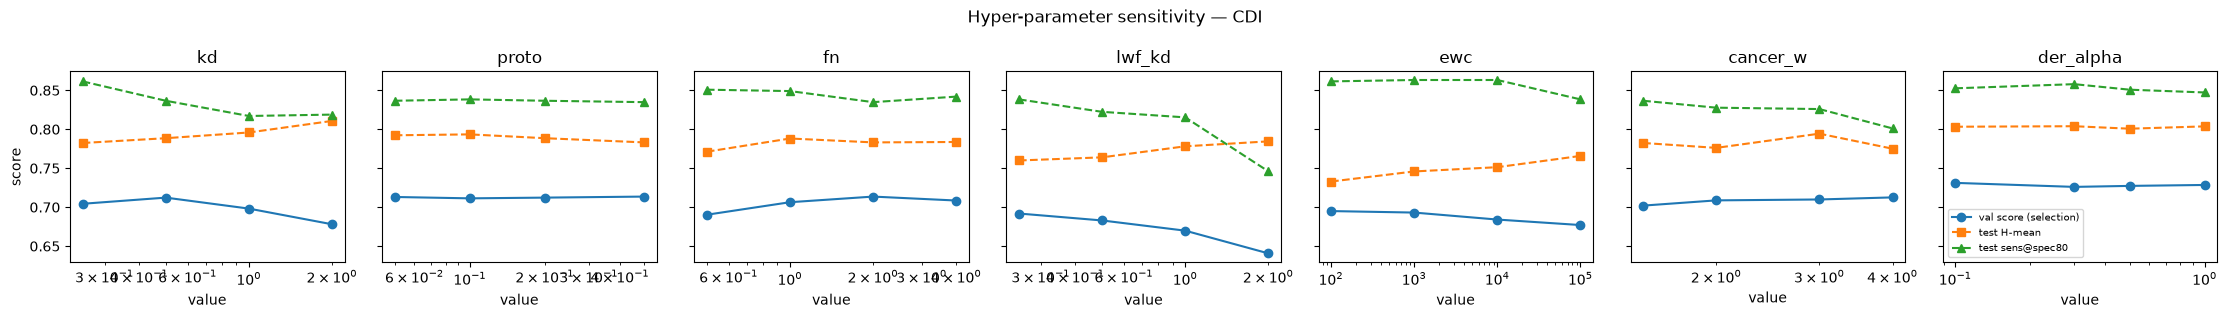

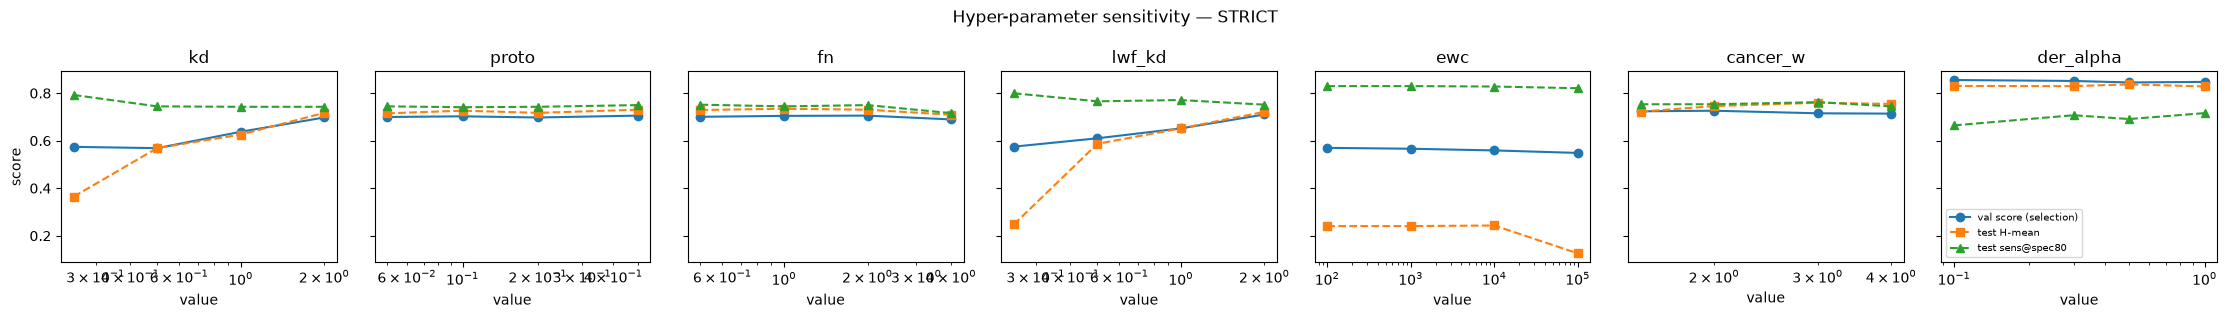

In [23]:
tune_logs = [pd.read_csv(RESULT_DIR / f"tuning_log_{p}.csv") for p in PROTOCOLS if (RESULT_DIR / f"tuning_log_{p}.csv").exists()]
if tune_logs:
    tlog = pd.concat(tune_logs, ignore_index=True)
    t_entries = [{"protocol": r.protocol, "method": "tune", "seed": int(r.seed), "key": r.key}
                 for r in tlog.drop_duplicates("key").itertuples(index=False)]
    tm = collect_metrics(t_entries)["runs"][["key", "h_mean", "milk_cancer_sens_at_spec80", "ddi_auroc"]]
    sens_df = tlog.merge(tm, on="key", how="left")
    sens_df.to_csv(RESULT_DIR / "lambda_sensitivity.csv", index=False)
    agg = sens_df.groupby(["protocol", "axis", "value"], as_index=False)[["val_score", "h_mean", "milk_cancer_sens_at_spec80", "ddi_auroc"]].mean()

    axes_to_plot = ["kd", "proto", "fn", "lwf_kd", "ewc", "cancer_w", "der_alpha"]
    for protocol in PROTOCOLS:
        a = agg[agg["protocol"] == protocol]
        fig, axs = plt.subplots(1, len(axes_to_plot), figsize=(3.2 * len(axes_to_plot), 3.2), sharey=True)
        for ax, axis in zip(axs, axes_to_plot):
            b = a[a["axis"] == axis].sort_values("value")
            if b.empty:
                ax.axis("off")
                continue
            ax.plot(b["value"], b["val_score"], marker="o", label="val score (selection)")
            ax.plot(b["value"], b["h_mean"], marker="s", linestyle="--", label="test H-mean")
            ax.plot(b["value"], b["milk_cancer_sens_at_spec80"], marker="^", linestyle="--", label="test sens@spec80")
            ax.set_xscale("log")
            ax.set_title(axis)
            ax.set_xlabel("value")
        axs[0].set_ylabel("score")
        axs[-1].legend(fontsize=7)
        fig.suptitle(f"Hyper-parameter sensitivity — {protocol}")
        plt.tight_layout()
        fig.savefig(FIG_DIR / f"lambda_sensitivity_{protocol}.png", dpi=300, bbox_inches="tight")
        plt.show()
else:
    print("No tuning logs (RUN_TUNING=False).")

## 23. Paper figures

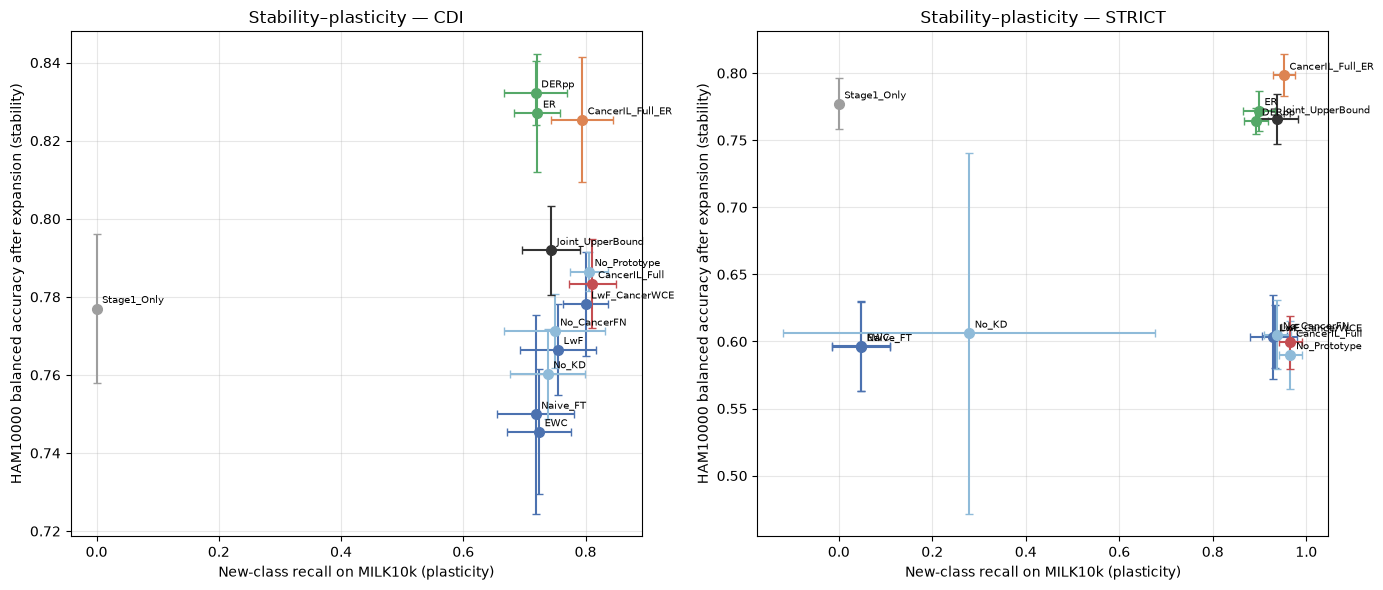

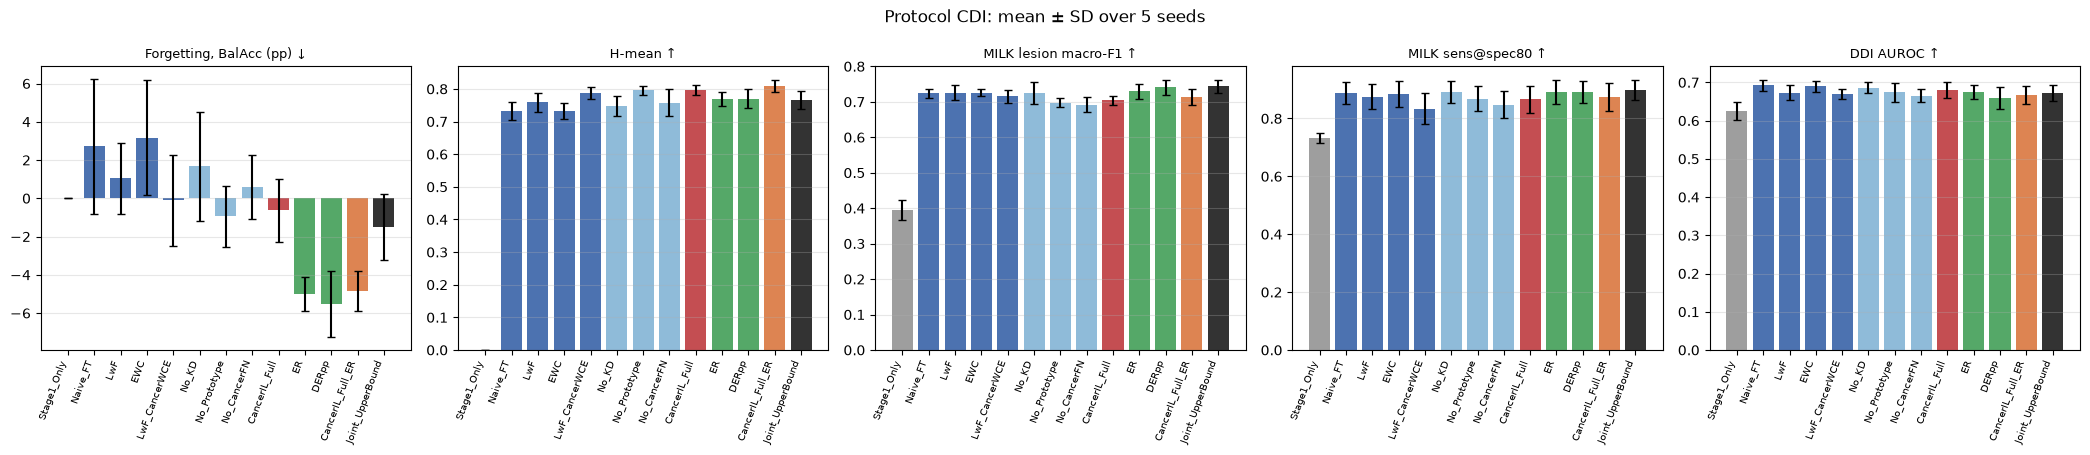

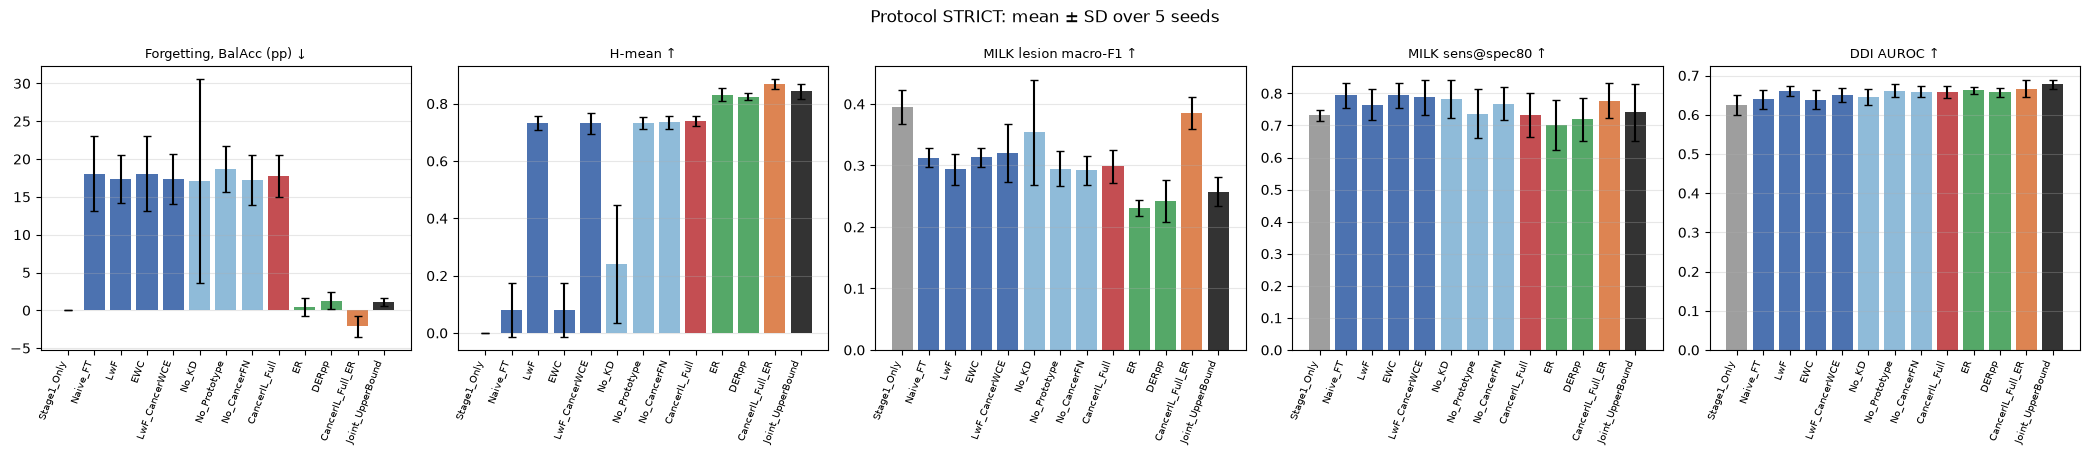

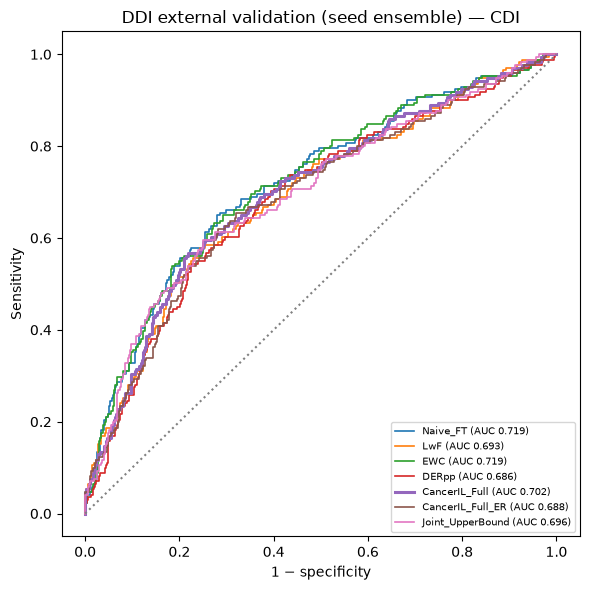

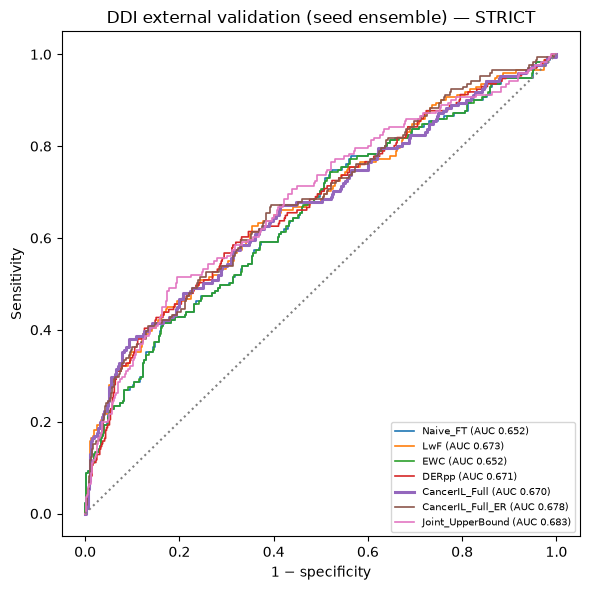

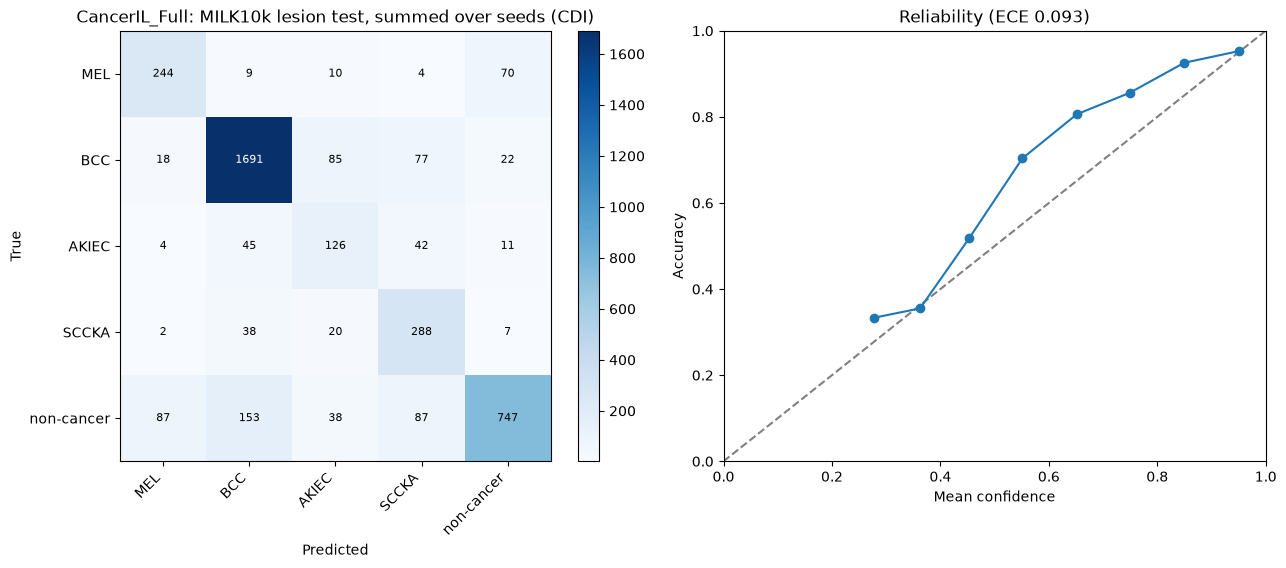

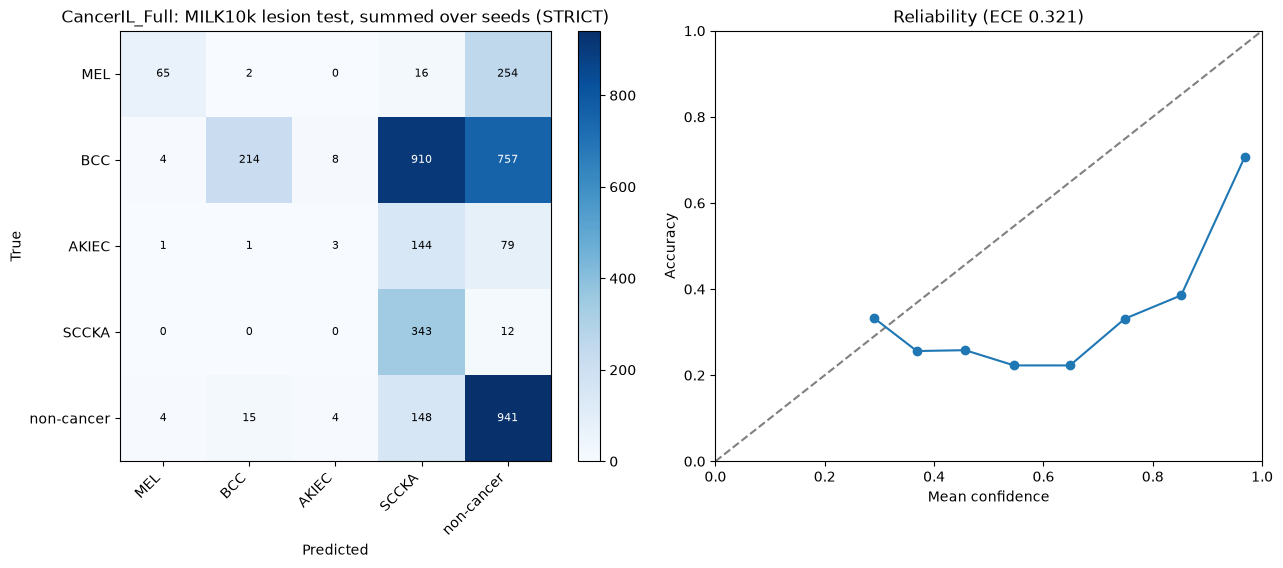

In [24]:
GROUP_COLORS = {
    "Reference": "#9e9e9e", "Exemplar-free baseline": "#4c72b0", "Proposed (ablation)": "#8fbbd9",
    "Proposed": "#c44e52", "Rehearsal": "#55a868", "Proposed + rehearsal": "#dd8452", "Upper bound": "#333333",
}


def ordered_summary(protocol):
    s = summary_df[summary_df["protocol"] == protocol].copy()
    s["method"] = pd.Categorical(s["method"].astype(str), METHOD_ORDER, ordered=True)
    return s.sort_values("method")


# (a) stability-plasticity plane
fig, axs = plt.subplots(1, len(PROTOCOLS), figsize=(7 * len(PROTOCOLS), 6), squeeze=False)
for ax, protocol in zip(axs[0], PROTOCOLS):
    s = ordered_summary(protocol)
    for r in s.itertuples(index=False):
        x, y = getattr(r, "milk_new_recall_mean"), getattr(r, "ham_post_bal_acc_mean")
        xe, ye = getattr(r, "milk_new_recall_sd"), getattr(r, "ham_post_bal_acc_sd")
        ax.errorbar(x, y, xerr=np.nan_to_num(xe), yerr=np.nan_to_num(ye), fmt="o",
                    color=GROUP_COLORS[r.group], capsize=3, markersize=7)
        ax.annotate(str(r.method), (x, y), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("New-class recall on MILK10k (plasticity)")
    ax.set_ylabel("HAM10000 balanced accuracy after expansion (stability)")
    ax.set_title(f"Stability–plasticity — {protocol}")
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "stability_plasticity.png", dpi=300, bbox_inches="tight")
plt.show()

# (b) bar charts of key metrics
BAR_METRICS = [("forgetting_bal_acc_pp", "Forgetting, BalAcc (pp) ↓"), ("h_mean", "H-mean ↑"),
               ("milk_lesion_macro_f1", "MILK lesion macro-F1 ↑"), ("milk_cancer_sens_at_spec80", "MILK sens@spec80 ↑"),
               ("ddi_auroc", "DDI AUROC ↑")]
for protocol in PROTOCOLS:
    s = ordered_summary(protocol)
    fig, axs = plt.subplots(1, len(BAR_METRICS), figsize=(4.2 * len(BAR_METRICS), 4.6))
    for ax, (m, label) in zip(axs, BAR_METRICS):
        x = np.arange(len(s))
        ax.bar(x, s[f"{m}_mean"], yerr=np.nan_to_num(s[f"{m}_sd"]), capsize=3,
               color=[GROUP_COLORS[g] for g in s["group"]])
        ax.set_xticks(x)
        ax.set_xticklabels(s["method"].astype(str), rotation=70, ha="right", fontsize=7)
        ax.set_title(label, fontsize=9)
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle(f"Protocol {protocol}: mean ± SD over {len(SEEDS)} seeds")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"method_bars_{protocol}.png", dpi=300, bbox_inches="tight")
    plt.show()

# (c) DDI ROC curves, seed ensemble
ROC_METHODS = ["Naive_FT", "LwF", "EWC", "DERpp", PRIMARY_METHOD, "CancerIL_Full_ER", "Joint_UpperBound"]
for protocol in PROTOCOLS:
    reg = registry_df[registry_df["protocol"] == protocol]
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)
    for method in ROC_METHODS:
        ps = [np.load(PRED_DIR / f"{k}.npz")["ddi"] for k in reg[reg["method"] == method]["key"] if (PRED_DIR / f"{k}.npz").exists()]
        if not ps:
            continue
        p = 1 - np.mean(ps, 0)[:, NC_IDX]
        fpr, tpr, _ = roc_curve(Y_DDI, p)
        ax.plot(fpr, tpr, label=f"{method} (AUC {roc_auc_score(Y_DDI, p):.3f})", linewidth=2.2 if method == PRIMARY_METHOD else 1.2)
    ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
    ax.set_xlabel("1 − specificity")
    ax.set_ylabel("Sensitivity")
    ax.set_title(f"DDI external validation (seed ensemble) — {protocol}")
    ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"ddi_roc_{protocol}.png", dpi=300, bbox_inches="tight")
    plt.show()

# (d) lesion-level confusion matrix (summed over seeds) and reliability diagram for the proposed method
for protocol in PROTOCOLS:
    reg = registry_df[(registry_df["protocol"] == protocol) & (registry_df["method"] == PRIMARY_METHOD)]
    cm = np.zeros((len(MILK_CLASSES), len(MILK_CLASSES)), dtype=int)
    all_p, all_y = [], []
    for r in reg.itertuples(index=False):
        f = PRED_DIR / f"{r.key}.npz"
        if not f.exists():
            continue
        lp, ly, _ = lesion_aggregate(make_milk_split(r.seed)["test"], np.load(f)["milk_test"])
        cm += confusion_matrix(ly, lp.argmax(1), labels=list(range(len(MILK_CLASSES))))
        all_p.append(lp)
        all_y.append(ly)
    if not all_p:
        continue
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
    im = axs[0].imshow(cm, cmap="Blues")
    axs[0].set_xticks(range(len(MILK_CLASSES)))
    axs[0].set_xticklabels(MILK_CLASSES, rotation=45, ha="right")
    axs[0].set_yticks(range(len(MILK_CLASSES)))
    axs[0].set_yticklabels(MILK_CLASSES)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            axs[0].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    axs[0].set_xlabel("Predicted")
    axs[0].set_ylabel("True")
    axs[0].set_title(f"{PRIMARY_METHOD}: MILK10k lesion test, summed over seeds ({protocol})")
    fig.colorbar(im, ax=axs[0])
    P, Y = np.concatenate(all_p), np.concatenate(all_y)
    conf, correct = P.max(1), (P.argmax(1) == Y).astype(float)
    edges = np.linspace(0, 1, 11)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            xs.append(conf[m].mean())
            ys.append(correct[m].mean())
    axs[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
    axs[1].plot(xs, ys, marker="o")
    axs[1].set_xlim(0, 1)
    axs[1].set_ylim(0, 1)
    axs[1].set_xlabel("Mean confidence")
    axs[1].set_ylabel("Accuracy")
    axs[1].set_title(f"Reliability (ECE {multiclass_ece(P, Y):.3f})")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"confusion_reliability_{protocol}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 24. Secondary tables: per-class forgetting, modality, DDI skin tone and subtype

In [25]:
def mean_sd_table(df, by, cols):
    g = df.groupby(by, observed=True)[cols]
    out = g.mean().add_suffix("_mean").join(g.std(ddof=1).add_suffix("_sd"))
    return out.reset_index()


pc = M["per_class"]
ham_pc = mean_sd_table(pc[pc["dataset"] == "HAM_test"], ["protocol", "method", "class"],
                       ["pre_recall", "post_recall", "forgetting_recall_pp"])
ham_pc.to_csv(RESULT_DIR / "ham_per_class_forgetting_mean_sd.csv", index=False)
milk_pc = mean_sd_table(pc[pc["dataset"] == "MILK_lesion_test"], ["protocol", "method", "class"], ["post_recall", "f1"])
milk_pc.to_csv(RESULT_DIR / "milk_lesion_per_class_mean_sd.csv", index=False)
mod_t = mean_sd_table(M["modality"], ["protocol", "method", "modality"], ["bal_acc", "macro_f1"])
mod_t.to_csv(RESULT_DIR / "milk_modality_mean_sd.csv", index=False)
tone_t = mean_sd_table(M["tone"], ["protocol", "method", "skin_tone"], ["auroc", "sens_valthr", "spec_valthr"])
tone_t.to_csv(RESULT_DIR / "ddi_skin_tone_mean_sd.csv", index=False)
sub_t = mean_sd_table(M["subtype"], ["protocol", "method", "subtype"], ["recall_valthr"])
sub_t.to_csv(RESULT_DIR / "ddi_subtype_mean_sd.csv", index=False)

focus = ["Naive_FT", "LwF", "EWC", "DERpp", PRIMARY_METHOD, "Joint_UpperBound"]
print("HAM per-class forgetting (recall, pp):")
display(ham_pc[ham_pc["method"].isin(focus)].round(3))
print("DDI by skin tone:")
display(tone_t[tone_t["method"].isin(focus)].round(3))
print("MILK by modality:")
display(mod_t[mod_t["method"].isin(focus)].round(3))

HAM per-class forgetting (recall, pp):


,protocol,method,class,pre_recall_mean,post_recall_mean,forgetting_recall_pp_mean,pre_recall_sd,post_recall_sd,forgetting_recall_pp_sd
0,CDI,CancerIL_Full,AKIEC,0.679,0.609,6.977,0.042,0.058,6.578
1,CDI,CancerIL_Full,BCC,0.783,0.843,-6.022,0.035,0.021,3.098
2,CDI,CancerIL_Full,MEL,0.732,0.823,-9.123,0.071,0.061,2.999
3,CDI,CancerIL_Full,non-cancer,0.914,0.858,5.627,0.023,0.022,0.344
8,CDI,DERpp,AKIEC,0.679,0.800,-12.093,0.042,0.035,5.303
9,CDI,DERpp,BCC,0.783,0.862,-7.957,0.035,0.021,1.953
10,CDI,DERpp,MEL,0.732,0.781,-4.912,0.071,0.053,1.877
11,CDI,DERpp,non-cancer,0.914,0.885,2.871,0.023,0.026,0.899
16,CDI,EWC,AKIEC,0.679,0.516,16.279,0.042,0.060,7.713
17,CDI,EWC,BCC,0.783,0.809,-2.581,0.035,0.026,4.341


DDI by skin tone:


,protocol,method,skin_tone,auroc_mean,sens_valthr_mean,spec_valthr_mean,auroc_sd,sens_valthr_sd,spec_valthr_sd
0,CDI,CancerIL_Full,12,0.663,0.494,0.732,0.038,0.081,0.067
1,CDI,CancerIL_Full,34,0.737,0.443,0.832,0.023,0.080,0.056
2,CDI,CancerIL_Full,56,0.624,0.288,0.875,0.039,0.048,0.038
6,CDI,DERpp,12,0.629,0.531,0.665,0.046,0.124,0.147
7,CDI,DERpp,34,0.723,0.500,0.778,0.033,0.157,0.106
8,CDI,DERpp,56,0.608,0.367,0.786,0.031,0.130,0.134
12,CDI,EWC,12,0.677,0.616,0.654,0.022,0.115,0.165
13,CDI,EWC,34,0.743,0.522,0.807,0.029,0.148,0.101
14,CDI,EWC,56,0.638,0.396,0.821,0.021,0.098,0.085
15,CDI,Joint_UpperBound,12,0.632,0.563,0.659,0.052,0.096,0.150


MILK by modality:


,protocol,method,modality,bal_acc_mean,macro_f1_mean,bal_acc_sd,macro_f1_sd
0,CDI,CancerIL_Full,clinical,0.596,0.562,0.023,0.026
1,CDI,CancerIL_Full,dermoscopic,0.728,0.688,0.017,0.020
4,CDI,DERpp,clinical,0.602,0.599,0.013,0.009
5,CDI,DERpp,dermoscopic,0.727,0.722,0.016,0.017
8,CDI,EWC,clinical,0.614,0.610,0.019,0.013
9,CDI,EWC,dermoscopic,0.712,0.704,0.017,0.014
10,CDI,Joint_UpperBound,clinical,0.620,0.607,0.018,0.015
11,CDI,Joint_UpperBound,dermoscopic,0.735,0.726,0.014,0.011
12,CDI,LwF,clinical,0.581,0.579,0.025,0.020
13,CDI,LwF,dermoscopic,0.721,0.702,0.025,0.024


## 25. Run metadata and artifact manifest

In [26]:
run_summaries = []
for f in RUNS_DIR.glob("*.json"):
    with open(f, encoding="utf-8") as fh:
        s = json.load(fh)
    run_summaries.append({k: s[k] for k in ["key", "protocol", "seed", "tag", "best_val_score", "epochs_run",
                                              "train_images", "peak_vram_gb", "minutes"]})
rs = pd.DataFrame(run_summaries)
rs.to_csv(RESULT_DIR / "all_stage2_run_summaries.csv", index=False)
if len(rs):
    print(f"Stage-2 runs on disk: {len(rs)} | total GPU time {rs['minutes'].sum() / 60:.1f} h | "
          f"max peak VRAM {rs['peak_vram_gb'].max():.2f} GB | mean {rs['minutes'].mean():.1f} min/run")

metadata = {
    "smoke_test": SMOKE_TEST, "seeds": SEEDS, "tune_seeds": TUNE_SEEDS, "protocols": PROTOCOLS,
    "config_signature": CONFIG_SIGNATURE, "tuned_hparams": TUNED_HP,
    "ham_val_source": HAM_VAL_SOURCE, "stage1_tag": STAGE1_TAG, "mal_oth_policy": MAL_OTH_POLICY, "stage2_modality": STAGE2_MODALITY,
    "milk_classes": MILK_CLASSES, "new_classes": NEW_CLASSES, "selection": SELECTION,
    "img_size": IMG_SIZE, "cache_size": CACHE_SIZE, "batch_size": BATCH_SIZE, "replay_batch_size": REPLAY_BATCH_SIZE,
    "epochs": {"stage1": STAGE1_EPOCHS, "stage2": STAGE2_EPOCHS}, "patience": {"stage1": STAGE1_PATIENCE, "stage2": STAGE2_PATIENCE},
    "lr": {"s1": [LR_BACKBONE_S1, LR_HEAD_S1], "s2": [LR_BACKBONE_S2, LR_HEAD_S2]}, "weight_decay": WEIGHT_DECAY,
    "ema_halflife_epochs": EMA_HALFLIFE_EPOCHS, "class_balanced_ce": CLASS_BALANCED_CE, "kd_temperature": KD_TEMP,
    "replay_per_class": REPLAY_PER_CLASS, "der_beta": DER_BETA, "tta": EVAL_TTA,
    "augmentation": {"area": AUG_AREA, "rotation_deg": AUG_ROT_DEG, "brightness": AUG_BRIGHTNESS,
                     "contrast": AUG_CONTRAST, "saturation": AUG_SATURATION},
    "target_sensitivity": TARGET_SENSITIVITY, "amp_dtype": str(AMP), "deterministic": DETERMINISTIC,
    "torch": torch.__version__, "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0),
}
with open(RESULT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)

artifacts = [{"file": str(p.relative_to(OUTPUT_ROOT)), "bytes": p.stat().st_size}
             for p in OUTPUT_ROOT.rglob("*") if p.is_file() and "checkpoints" not in p.parts and "predictions" not in p.parts]
pd.DataFrame(artifacts).sort_values("file").to_csv(RESULT_DIR / "artifact_manifest.csv", index=False)
print("All outputs written to:", OUTPUT_ROOT.resolve())

Stage-2 runs on disk: 431 | total GPU time 73.7 h | max peak VRAM 8.77 GB | mean 10.3 min/run
All outputs written to: D:\Project\New folder\canceril_skin_outputs_v2


## 26. What to report in the paper

**Main tables** (`paper_table_CDI.csv`, `paper_table_STRICT.csv`): mean ± SD over 5 replicates for every method, grouped as reference / exemplar-free / proposed / rehearsal / upper bound. Compare the proposed method primarily with the **exemplar-free** group, which is its fair comparison class. Rehearsal methods and the joint upper bound give context.

**Claims must be backed by** `significance_paired_seeds.csv` (Holm-corrected) and `delong_ddi_seed_ensemble.csv`. If a difference is not significant, write "comparable", not "better".

**Cancer-FN component:** argue its value with `milk_cancer_sens_at_spec80` / `ddi_sens_at_spec80` (matched operating points) and against `LwF_CancerWCE`. Sensitivity at the argmax threshold alone is not evidence, because it is just an operating-point shift.

**Disclose:**
- MAL_OTH exclusion.
- The HAM validation construction (`HAM_VAL_SOURCE`).
- That model selection uses a small held-out HAM validation set (`SELECTION="joint_val"`).
- That operating-point thresholds come from MILK validation.
- The DER++ logit note from Section 16.
- That all hyper-parameters were tuned on validation data only (`lambda_sensitivity.csv`, figure `lambda_sensitivity_*.png`).

**Figures:** `stability_plasticity.png` (the key continual-learning figure), `method_bars_*.png`, `ddi_roc_*.png`, `confusion_reliability_*.png`, `lambda_sensitivity_*.png`.

**Subgroups:** DDI skin-tone and subtype results are descriptive (small n). Report n with every subgroup number.

# PART B — Strengthening experiments (added after the first full run)

Part A (Sections 0–26) is finished and cached. Part B **reuses every Part-A run**: base-method run keys are unchanged, so nothing already trained is recomputed. Part B adds the experiments a Q1/A* reviewer will ask for. The headline method is **`CancerIL_Full_ER`** (the proposed objective on top of experience replay).

| Cell | What it does | New runs (approx.) |
|---|---|---|
| B1 | Part-B configuration | – |
| B2 | Extended run manager (replay budget, alternative selection rule, normalised-Fisher EWC) | – |
| B3 | **Self-test** of every new code path (one training step each, ~2 min) | 0 |
| B4 | Re-tune **EWC with a normalised Fisher** (fixes "EWC ≡ Naive_FT") | 10 |
| B5 | **Rehearsal ablations + generality** (ER+KD, ER+KD+cancer-wCE, Full_ER −KD/−Proto/−FN, Full on DER++), 5 seeds | ~70 |
| B6 | **Replay-budget sweep** (20 / 100 exemplars per class), STRICT | ~40 |
| B7 | **Selection-rule robustness** (MILK-val-only model selection), STRICT | ~45 |
| B8 | **Seeds 6–7** (Stage 1 + every method), so Wilcoxon can reach p < 0.05 | ~110 |
| B9 | Metrics for all Part-B runs (from saved probabilities) | – |
| B10–B16 | Final paper tables (+ LaTeX), pre-registered statistics, ablation table, budget figure, selection robustness, skin-tone fairness, automatic claims checklist | – |

Every run cell (B4–B8) is resume-safe: if it stops, re-run the same cell and finished runs are skipped. B9–B16 can be run at any time and use whatever runs are finished so far.

## B1. Part-B configuration

In [27]:
PRIMARY_B = "CancerIL_Full_ER"

EXTRA_SEEDS = [2718, 99]                 # replicates 6 and 7 (with n >= 6 the Wilcoxon test can reach p < 0.05)
BUDGETS = [20, 100]                      # extra replay budgets (exemplars per old class); 50 = REPLAY_PER_CLASS from Part A
BUDGET_PROTOCOLS = ["STRICT"]
BUDGET_METHODS = ["ER", "DERpp", "ER_KD_CancerWCE", "CancerIL_Full_ER"]
ALT_SELECTION = "new_only"               # alternative checkpoint-selection rule: MILK-val balanced accuracy only
SELECTION_PROTOCOLS = ["STRICT"]
SELECTION_METHODS = ["Naive_FT", "LwF", "EWC_Norm", "LwF_CancerWCE", "CancerIL_Full",
                     "ER", "DERpp", "ER_KD_CancerWCE", "CancerIL_Full_ER"]
EWC_NORM_GRID = [0.1, 1.0, 10.0, 100.0, 1000.0]
RUN_ORDER_PROTOCOLS = ["STRICT", "CDI"]  # STRICT first: it carries the headline result
ALPHA = 0.05

if SMOKE_TEST:
    EXTRA_SEEDS = []
    BUDGETS = [20]
    EWC_NORM_GRID = [1.0, 10.0]

ALL_SEEDS = list(SEEDS) + [s for s in EXTRA_SEEDS if s not in SEEDS]

DISPLAY_NAMES = {
    "Stage1_Only": "Stage 1 only",
    "Naive_FT": "Fine-tuning",
    "LwF": "LwF",
    "EWC_Norm": "EWC",
    "LwF_CancerWCE": "LwF + cancer-wCE",
    "No_KD": "Ours (no replay) − KD",
    "No_Prototype": "Ours (no replay) − Proto",
    "No_CancerFN": "Ours (no replay) − FN",
    "CancerIL_Full": "Ours (no replay)",
    "ER": "ER",
    "DERpp": "DER++",
    "ER_KD": "ER + KD (iCaRL-style)",
    "ER_KD_CancerWCE": "ER + KD + cancer-wCE",
    "ER_Proto_FN": "Ours (ER) − KD",
    "ER_KD_FN": "Ours (ER) − Proto",
    "ER_KD_Proto": "Ours (ER) − FN",
    "CancerIL_Full_ER": "Ours (ER)",
    "CancerIL_Full_DERpp": "Ours (DER++)",
    "Joint_UpperBound": "Joint (offline reference)",
}
print("All seeds:", ALL_SEEDS)
print("Primary method:", PRIMARY_B)

All seeds: [42, 1337, 2026, 7, 314, 2718, 99]
Primary method: CancerIL_Full_ER


## B2. Extended run manager

This replaces `run_stage2` with a version that understands three optional spec keys. A key is only added to the spec when it differs from its Part-A default, so **every Part-A run keeps its original hash and is loaded from disk, not retrained.**

- `rpc`: replay budget (exemplars per old class). Buffers come from one herding ranking per seed, so the 20-exemplar buffer is a prefix of the 50- and 100-exemplar buffers (iCaRL herding is greedy, so prefixes are themselves herding solutions).
- `sel`: checkpoint-selection rule for that run (`joint_val` or `new_only`).
- `ewc_norm`: divide the Fisher by its global mean, so λ has an interpretable scale. The Part-A Fisher was tiny in absolute terms, so EWC with the selected λ behaved like plain fine-tuning.

The cancer-FN term now also covers replay samples for DER++ (it already did for ER). No Part-A run combined DER++ with the FN term, so no earlier result changes.

In [28]:
_EXT_DEFAULTS = {"rpc": int(REPLAY_PER_CLASS), "sel": SELECTION, "ewc_norm": False}


def _canon_ext(k, v):
    if k == "rpc":
        return int(v)
    if k == "ewc_norm":
        return bool(v)
    return str(v)


def with_ext(sp, **ext):
    """Copy a spec and add extension keys (only those that differ from the Part-A defaults)."""
    out = dict(sp)
    for k, v in ext.items():
        assert k in _EXT_DEFAULTS, k
        v = _canon_ext(k, v)
        if v != _EXT_DEFAULTS[k]:
            out[k] = v
        else:
            out.pop(k, None)
    return out


def spec_ext(**kw):
    ext = {k: kw.pop(k) for k in list(kw) if k in _EXT_DEFAULTS}
    return with_ext(spec(**kw), **ext)


# Hash-stability guard: base specs must hash exactly as in Part A.
assert run_key("CDI", 42, spec_ext(kd=0.5)) == run_key("CDI", 42, spec(kd=0.5))
assert run_key("CDI", 42, with_ext(spec(replay="er"), rpc=REPLAY_PER_CLASS, sel=SELECTION)) == run_key("CDI", 42, spec(replay="er"))


def get_buffer(res, rpc):
    rpc = int(rpc)
    if rpc == int(REPLAY_PER_CLASS):
        return res.buffer
    if not hasattr(res, "buffers"):
        res.buffers = {}
    if rpc in res.buffers:
        return res.buffers[rpc]
    need = int(max([rpc, int(REPLAY_PER_CLASS)] + [int(b) for b in BUDGETS]))
    path = CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{res.seed}_herding_order.csv"
    order = pd.read_csv(path) if path.exists() else None
    if order is None or int(order["M"].iloc[0]) < need:
        emb = extract_embeddings(res.stage1, ham_train_df["gidx"].values).cpu().numpy()
        labels = ham_train_df["label"].values
        rows = []
        for c in HAM_CLASSES:
            idx = np.where(labels == c)[0]
            f = emb[idx] / np.clip(np.linalg.norm(emb[idx], axis=1, keepdims=True), 1e-12, None)
            for r, j in enumerate(herding_select(f, min(need, len(idx)))):
                rows.append({"gidx": int(ham_train_df["gidx"].values[idx[j]]), "label": c, "rank": r, "M": need})
        order = pd.DataFrame(rows)
        order.to_csv(path, index=False)
        base = pd.read_csv(CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{res.seed}_herding_buffer.csv")
        overlap = len(set(order.loc[order["rank"] < REPLAY_PER_CLASS, "gidx"]) & set(base["gidx"])) / max(1, len(base))
        print(f"[herding] seed {res.seed}: ranking up to {need}/class; overlap with Part-A {REPLAY_PER_CLASS}-buffer = {overlap:.1%}")
    sel = order[order["rank"] < rpc]
    buf = GPUReplayBuffer(sel["gidx"].values, sel["label"].map(MILK_CLASSES.index).values)
    res.buffers[rpc] = buf
    return buf


def get_fisher_norm(res):
    if getattr(res, "fisher_norm", None) is None:
        fisher, star = get_fisher(res)
        total = sum(float(v.double().sum()) for v in fisher.values())
        count = sum(v.numel() for v in fisher.values())
        mean = total / max(count, 1)
        res.fisher_norm = ({k: v / mean for k, v in fisher.items()}, star)
        res.fisher_mean = mean
    return res.fisher_norm


def _prepare_stage2(protocol, seed, sp):
    res = get_seed_resources(seed)
    vis = visible_classes(protocol)
    tr_df = res.split["train"][res.split["train"]["label"].isin(vis)].reset_index(drop=True)
    va_df = res.split["val"][res.split["val"]["label"].isin(vis)].reset_index(drop=True)
    if sp["joint"]:
        tr_df = pd.concat([ham_train_df[["gidx", "label"]], tr_df[["gidx", "label"]]], ignore_index=True)
    tr_df = maybe_subsample(tr_df, seed)
    y_tr = tr_df["label"].map(MILK_CLASSES.index).values
    y_va = va_df["label"].map(MILK_CLASSES.index).values
    y_hv = ham_val_df["label"].map(MILK_CLASSES.index).values
    sel_rule = sp.get("sel", SELECTION)
    rpc = int(sp.get("rpc", REPLAY_PER_CLASS))

    set_seed(seed)
    model = expand_classifier(res.stage1, HAM_CLASSES, MILK_CLASSES)
    loader = GPUBatcher(tr_df["gidx"].values, y_tr, BATCH_SIZE, shuffle=True, drop_last=True, seed=seed)
    cw = class_weights_for(y_tr, len(MILK_CLASSES), sp["cancer_w"], CANCER_IDX)
    teacher = res.stage1 if (sp["kd"] > 0 or sp["replay"] == "derpp") else None
    if sp["ewc"] > 0:
        fisher = get_fisher_norm(res) if sp.get("ewc_norm", False) else get_fisher(res)
    else:
        fisher = None
    buffer = get_buffer(res, rpc) if sp["replay"] in ("er", "derpp") else None

    def compute_loss(m, x, y, gen):
        n = x.shape[0]
        yr = None
        if buffer is not None:
            with torch.autocast("cuda", enabled=False):
                xr_u8, yr = buffer.sample(REPLAY_BATCH_SIZE, gen)
                xr = gpu_train_augment(xr_u8, gen)
            X = torch.cat([x, xr])
        else:
            X = x
        logits, emb = m(X, return_embedding=True)
        logits, emb = logits.float(), emb.float()
        lc = logits[:n]
        parts = {}
        ce = F.cross_entropy(lc, y, weight=cw)
        parts["ce"] = ce
        loss = ce
        t_logits = None
        if teacher is not None:
            with torch.no_grad():
                t_logits = teacher(X).float()
        if sp["replay"] == "er":
            ce_r = F.cross_entropy(logits[n:], yr)
            parts["replay_ce"] = ce_r
            loss = loss + ce_r
        elif sp["replay"] == "derpp":
            mse = F.mse_loss(logits[n:][:, OLD_IDX_T], t_logits[n:])
            ce_r = F.cross_entropy(logits[n:], yr)
            parts["der_mse"], parts["replay_ce"] = mse, ce_r
            loss = loss + sp["der_alpha"] * mse + sp["der_beta"] * ce_r
        if sp["kd"] > 0:
            l = kd_loss(lc, t_logits[:n])
            parts["kd"] = l
            loss = loss + sp["kd"] * l
        if sp["proto"] > 0:
            l = prototype_loss(emb[:n], y, res.proto_mat, res.has_proto)
            parts["proto"] = l
            loss = loss + sp["proto"] * l
        if sp["fn"] > 0:
            l = cancer_fn_loss(logits, torch.cat([y, yr])) if yr is not None else cancer_fn_loss(lc, y)
            parts["fn"] = l
            loss = loss + sp["fn"] * l
        if fisher is not None:
            l = ewc_penalty(m, *fisher)
            parts["ewc"] = l
            loss = loss + sp["ewc"] * l
        return loss, parts

    def val_fn(m):
        new_s = bal_acc(y_va, predict_probs(m, va_df["gidx"].values).argmax(1))
        info = {"milk_val_bal_acc": new_s}
        if sel_rule == "joint_val":
            old_s = bal_acc(y_hv, predict_probs(m, ham_val_df["gidx"].values).argmax(1))
            info["ham_val_bal_acc"] = old_s
            return hmean(old_s, new_s), info
        if sel_rule == "new_only":
            return new_s, info
        raise ValueError(sel_rule)

    return SimpleNamespace(res=res, model=model, loader=loader, compute_loss=compute_loss, val_fn=val_fn,
                           tr_df=tr_df, buffer=buffer)


def run_stage2(protocol, seed, sp, tag=""):
    key = run_key(protocol, seed, sp)
    summ_path = RUNS_DIR / f"{key}.json"
    if summ_path.exists():
        with open(summ_path, encoding="utf-8") as f:
            return json.load(f)

    t_start = time.time()
    ctx = _prepare_stage2(protocol, seed, sp)
    res = ctx.res
    model, hist, best, info, peak = fit(
        ctx.model, ctx.loader, ctx.compute_loss, ctx.val_fn, epochs=STAGE2_EPOCHS, patience=STAGE2_PATIENCE,
        lr_backbone=LR_BACKBONE_S2, lr_head=LR_HEAD_S2, seed=seed, desc=f"{protocol}|{tag}|s{seed}",
        verbose=VERBOSE_EPOCHS,
    )
    preds = {
        "ham_val": predict_probs(model, ham_val_df["gidx"].values, tta=EVAL_TTA),
        "ham_test": predict_probs(model, ham_test_df["gidx"].values, tta=EVAL_TTA),
        "milk_val": predict_probs(model, res.split["val"]["gidx"].values, tta=EVAL_TTA),
        "milk_test": predict_probs(model, res.split["test"]["gidx"].values, tta=EVAL_TTA),
        "ddi": predict_probs(model, ddi_df["gidx"].values, tta=EVAL_TTA),
    }
    np.savez_compressed(PRED_DIR / f"{key}.npz", **preds)
    if SAVE_STAGE2_CHECKPOINTS:
        torch.save(model.state_dict(), CKPT_DIR / "stage2" / f"{key}.pt")
    hist.to_csv(RUNS_DIR / f"{key}_history.csv", index=False)

    summary = {
        "key": key, "protocol": protocol, "seed": int(seed), "tag": tag, "spec": sp,
        "best_val_score": float(best), "best_val_info": {k: float(v) for k, v in info.items()},
        "epochs_run": int(len(hist)), "train_images": int(len(ctx.tr_df)),
        "peak_vram_gb": round(float(peak), 2), "minutes": round((time.time() - t_start) / 60, 2),
    }
    tmp = summ_path.with_suffix(".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)
    os.replace(tmp, summ_path)
    print(f"[done] {protocol:6s} | {tag:30s} | seed {seed} | val={best:.4f} | {summary['epochs_run']} ep | "
          f"{summary['minutes']:.1f} min | peak {summary['peak_vram_gb']} GB")
    del model, preds, ctx
    gc.collect()
    torch.cuda.empty_cache()
    return summary


def execute_plan(plan, label):
    """Run every planned (protocol, seed, spec) that is not on disk yet; seed-major to reuse per-seed resources."""
    seed_rank = {s: i for i, s in enumerate(ALL_SEEDS)}
    prot_rank = {p: i for i, p in enumerate(RUN_ORDER_PROTOCOLS)}
    uniq = {}
    for p in plan:
        uniq.setdefault(p["key"], p)
    todo = [p for p in uniq.values() if not (RUNS_DIR / f"{p['key']}.json").exists()]
    todo.sort(key=lambda p: (seed_rank.get(p["seed"], 99), prot_rank.get(p["protocol"], 9)))
    rs_prev = []
    for f in RUNS_DIR.glob("*.json"):
        with open(f, encoding="utf-8") as fh:
            rs_prev.append(json.load(fh))
    mins = pd.DataFrame([{"protocol": r["protocol"], "m": r["minutes"]} for r in rs_prev]).groupby("protocol")["m"].mean() \
        if rs_prev else pd.Series(dtype=float)
    est_h = sum(float(mins.get(p["protocol"], 8.0)) for p in todo) / 60
    print(f"{label}: {len(uniq)} runs planned | {len(uniq) - len(todo)} already on disk | {len(todo)} to run "
          f"(rough estimate {est_h:.1f} h)")
    t0 = time.time()
    for i, p in enumerate(todo, 1):
        run_stage2(p["protocol"], p["seed"], p["spec"], tag=p["tag"])
        if i % 5 == 0 or i == len(todo):
            el = (time.time() - t0) / 3600
            print(f"   ... {i}/{len(todo)} done | {el:.2f} h elapsed | ~{el / i * (len(todo) - i):.1f} h left")
    print(f"{label}: finished ({(time.time() - t0) / 3600:.2f} h this session)")


print("Extended run manager ready (Part-A run keys unchanged).")

Extended run manager ready (Part-A run keys unchanged).


## B3. Method registry and self-test

The self-test builds each new configuration and runs **one** forward/backward step (no training, nothing saved). It checks the new code paths before hours of GPU time are spent. It takes about 2 minutes, mostly the one-time herding ranking and Fisher loading.

In [30]:
METHOD_GROUPS.update({
    "EWC_Norm": "Exemplar-free baseline",
    "ER_KD": "Rehearsal",
    "ER_KD_CancerWCE": "Rehearsal",
    "ER_Proto_FN": "Proposed + rehearsal (ablation)",
    "ER_KD_FN": "Proposed + rehearsal (ablation)",
    "ER_KD_Proto": "Proposed + rehearsal (ablation)",
    "CancerIL_Full_DERpp": "Proposed + rehearsal",
})
METHOD_ORDER_B = [
    "Stage1_Only", "Naive_FT", "LwF", "EWC_Norm", "LwF_CancerWCE",
    "No_KD", "No_Prototype", "No_CancerFN", "CancerIL_Full",
    "ER", "DERpp", "ER_KD", "ER_KD_CancerWCE",
    "ER_Proto_FN", "ER_KD_FN", "ER_KD_Proto", "CancerIL_Full_ER", "CancerIL_Full_DERpp",
    "Joint_UpperBound",
]
EWC_NORM_HP = {}   # filled by B4


def build_methods_B(protocol):
    hp = TUNED_HP[protocol]
    kd, pr, fn = hp["kd"], hp["proto"], hp["fn"]
    m = build_methods(hp)
    m.pop("EWC")   # replaced by the normalised-Fisher EWC (the Part-A EWC stays on disk, reported in the appendix)
    if protocol in EWC_NORM_HP:
        m["EWC_Norm"] = spec_ext(ewc=EWC_NORM_HP[protocol], ewc_norm=True)
    m["ER_KD"] = spec(kd=kd, replay="er")
    m["ER_KD_CancerWCE"] = spec(kd=kd, cancer_w=hp["cancer_w"], replay="er")
    m["ER_Proto_FN"] = spec(proto=pr, fn=fn, replay="er")
    m["ER_KD_FN"] = spec(kd=kd, fn=fn, replay="er")
    m["ER_KD_Proto"] = spec(kd=kd, proto=pr, replay="er")
    m["CancerIL_Full_DERpp"] = spec(kd=kd, proto=pr, fn=fn, replay="derpp", der_alpha=hp["der_alpha"], der_beta=DER_BETA)
    return OrderedDict((k, m[k]) for k in METHOD_ORDER_B if k in m)


def selftest(protocol, sp, name, check_val=False):
    ctx = _prepare_stage2(protocol, SEEDS[0], sp)
    gen = torch.Generator(device=device)
    gen.manual_seed(0)
    ctx.model.train()
    x_u8, y = next(iter(ctx.loader))
    x = gpu_train_augment(x_u8, gen)
    with torch.autocast("cuda", dtype=AMP):
        loss, parts = ctx.compute_loss(ctx.model, x, y, gen)
    loss.backward()
    ok = math.isfinite(float(loss)) and all(
        p.grad is None or torch.isfinite(p.grad).all() for p in ctx.model.parameters())
    msg = f"[selftest] {protocol:6s} {name:34s} loss={float(loss):.4f} " + \
          " ".join(f"{k}={float(v):.4g}" for k, v in parts.items())
    if ctx.buffer is not None:
        msg += f" | buffer={ctx.buffer.x.shape[0]} imgs"
    if check_val:
        score, info = ctx.val_fn(ctx.model)
        msg += f" | val_fn={score:.4f} {info}"
    print(msg + ("" if ok else "   <-- NON-FINITE!"))
    del ctx
    gc.collect()
    torch.cuda.empty_cache()
    return ok


_hp = TUNED_HP["STRICT"]
_tests = [
    ("STRICT", spec_ext(ewc=1.0, ewc_norm=True), "EWC_Norm (lambda=1)", False),
    ("STRICT", spec(kd=_hp["kd"], cancer_w=_hp["cancer_w"], replay="er"), "ER_KD_CancerWCE", False),
    ("STRICT", spec(kd=_hp["kd"], proto=_hp["proto"], fn=_hp["fn"], replay="derpp",
                    der_alpha=_hp["der_alpha"], der_beta=DER_BETA), "CancerIL_Full_DERpp", False),
    ("STRICT", with_ext(spec(kd=_hp["kd"], proto=_hp["proto"], fn=_hp["fn"], replay="er"), rpc=max(BUDGETS)),
     f"CancerIL_Full_ER @rpc{max(BUDGETS)}", False),
    ("STRICT", with_ext(spec(replay="er"), rpc=min(BUDGETS)), f"ER @rpc{min(BUDGETS)}", False),
    ("STRICT", with_ext(spec(), sel=ALT_SELECTION), f"Naive_FT @sel:{ALT_SELECTION}", True),
    ("CDI", spec(proto=TUNED_HP["CDI"]["proto"], fn=TUNED_HP["CDI"]["fn"], replay="er"), "ER_Proto_FN", False),
]
results = [selftest(*t) for t in _tests]
f0 = get_seed_resources(SEEDS[0])
if getattr(f0, "fisher_mean", None) is not None:
    print(f"Raw Fisher global mean (seed {SEEDS[0]}): {f0.fisher_mean:.3e}  -> normalised to 1.0")
assert all(results), "A self-test produced a non-finite loss or gradient. Send me the output above."
print("\nAll self-tests passed.")

C:\Users\Debajyoti\AppData\Local\Temp\ipykernel_4084\597149359.py:46: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  ok = math.isfinite(float(loss)) and all(


[selftest] STRICT EWC_Norm (lambda=1)                loss=0.9584 ce=0.9584 ewc=0
[selftest] STRICT ER_KD_CancerWCE                    loss=4.2615 ce=1.406 replay_ce=0.2095 kd=1.323 | buffer=200 imgs
[selftest] STRICT CancerIL_Full_DERpp                loss=5.6733 ce=1.032 der_mse=8.318 replay_ce=0.2095 kd=1.323 proto=0.08192 fn=0.5091 | buffer=200 imgs
[selftest] STRICT CancerIL_Full_ER @rpc100           loss=6.7542 ce=1.029 replay_ce=1.023 kd=1.274 proto=0.08727 fn=1.056 | buffer=400 imgs
[selftest] STRICT ER @rpc20                          loss=2.7651 ce=1.061 replay_ce=1.704 | buffer=80 imgs
[selftest] STRICT Naive_FT @sel:new_only             loss=0.9584 ce=0.9584 | val_fn=0.3711 {'milk_val_bal_acc': 0.3710762331838565}
[selftest] CDI    ER_Proto_FN                        loss=5.4238 ce=2.888 replay_ce=0.3033 proto=0.09628 fn=1.092 | buffer=200 imgs
Raw Fisher global mean (seed 42): 1.297e-06  -> normalised to 1.0

All self-tests passed.


## B4. EWC with a normalised Fisher (re-tuned on validation only)

In Part A, EWC's metrics matched plain fine-tuning almost exactly, so the penalty was effectively inactive. Here the Fisher is divided by its global mean and λ is re-tuned over a wide grid on the tuning seed(s). The printout reports how large the EWC term was relative to the CE term at the end of training, so you can show reviewers that the regulariser is genuinely active.

In [31]:
for protocol in PROTOCOLS:
    hp_path = RESULT_DIR / f"tuned_ewc_norm_{protocol}.json"
    scores, log = {}, []
    for v in EWC_NORM_GRID:
        vals = []
        for s in TUNE_SEEDS:
            sp = spec_ext(ewc=float(v), ewc_norm=True)
            summ = run_stage2(protocol, s, sp, tag=f"tune:ewc_norm={v:g}")
            vals.append(summ["best_val_score"])
            h = pd.read_csv(RUNS_DIR / f"{summ['key']}_history.csv")
            ratio = float(v) * h["train_ewc"].iloc[-1] / max(h["train_ce"].iloc[-1], 1e-12) if "train_ewc" in h else float("nan")
            log.append({"protocol": protocol, "axis": "ewc_norm", "value": float(v), "seed": s, "key": summ["key"],
                        "val_score": summ["best_val_score"], "epochs": summ["epochs_run"], "ewc_to_ce_ratio_last_epoch": ratio})
        scores[float(v)] = float(np.mean(vals))
    best = max(scores, key=scores.get)
    EWC_NORM_HP[protocol] = best
    lg = pd.DataFrame(log)
    lg.to_csv(RESULT_DIR / f"tuning_log_ewc_norm_{protocol}.csv", index=False)
    with open(hp_path, "w", encoding="utf-8") as f:
        json.dump({"ewc_norm_lambda": best, "scores": scores}, f, indent=2)
    print(f"[{protocol}] EWC (normalised Fisher): " + "  ".join(f"{k:g}->{s:.4f}" for k, s in scores.items())
          + f"  | selected {best:g}")
    display(lg[["value", "val_score", "epochs", "ewc_to_ce_ratio_last_epoch"]].round(4))
    if best in (min(EWC_NORM_GRID), max(EWC_NORM_GRID)):
        print(f"   note: the selected lambda is at the edge of the grid. Report this; it means EWC's best setting "
              f"is {'the weakest' if best == min(EWC_NORM_GRID) else 'the strongest'} penalty tried.")
print("EWC_NORM_HP =", EWC_NORM_HP)

[CDI] EWC (normalised Fisher): 0.1->0.6747  1->0.6621  10->0.6318  100->0.5792  1000->0.5343  | selected 0.1


,value,val_score,epochs,ewc_to_ce_ratio_last_epoch
0,0.1,0.6747,14,0.3976
1,1.0,0.6621,30,0.1976
2,10.0,0.6318,28,0.1356
3,100.0,0.5792,30,0.1579
4,1000.0,0.5343,30,0.2939


   note: the selected lambda is at the edge of the grid. Report this; it means EWC's best setting is the weakest penalty tried.
[STRICT] EWC (normalised Fisher): 0.1->0.5474  1->0.5462  10->0.6041  100->0.6237  1000->0.6330  | selected 1000


,value,val_score,epochs,ewc_to_ce_ratio_last_epoch
0,0.1,0.5474,9,0.5601
1,1.0,0.5462,10,0.5604
2,10.0,0.6041,10,0.4396
3,100.0,0.6237,14,0.2670
4,1000.0,0.6330,24,0.0652


   note: the selected lambda is at the edge of the grid. Report this; it means EWC's best setting is the strongest penalty tried.
EWC_NORM_HP = {'CDI': 0.1, 'STRICT': 1000.0}


## B5. Rehearsal ablations and generality (seeds 1–5)

This is the decisive experiment. The Part-A gain of `CancerIL_Full_ER` over ER could simply be "replay + distillation", which is known. These runs isolate what the proposed terms add **on top of replay**:

| Method | Loss | Question it answers |
|---|---|---|
| `ER_KD` | ER + KD (iCaRL-style) | Is Ours(ER) just replay + distillation? |
| `ER_KD_CancerWCE` | ER + KD + cancer-weighted CE | Does the FN term beat simple cancer re-weighting? **(strongest competitor)** |
| `ER_Proto_FN` | Ours(ER) − KD | Contribution of KD |
| `ER_KD_FN` | Ours(ER) − Proto | Contribution of the prototype term |
| `ER_KD_Proto` | Ours(ER) − FN | Contribution of the cancer-FN term |
| `CancerIL_Full_DERpp` | Ours on DER++ | Is the objective a plug-in for other rehearsal methods? |
| `EWC_Norm` | EWC, normalised Fisher | Fixed EWC baseline |

All use the same λ values as `CancerIL_Full_ER` (tuned in Part A), so each ablation differs from it in exactly one term.

In [32]:
def plan_main_B(seeds):
    plan = []
    for protocol in PROTOCOLS:
        for name, sp in build_methods_B(protocol).items():
            for seed in seeds:
                plan.append({"protocol": protocol, "family": "main", "method": name, "variant": name,
                             "seed": seed, "spec": sp, "key": run_key(protocol, seed, sp), "tag": name,
                             "rpc": int(sp.get("rpc", REPLAY_PER_CLASS)), "sel": sp.get("sel", SELECTION)})
    return plan


assert all(p in EWC_NORM_HP for p in PROTOCOLS), "Run B4 first (it sets EWC_NORM_HP)."
execute_plan(plan_main_B(SEEDS), "B5 main (seeds 1-5)")

B5 main (seeds 1-5): 180 runs planned | 180 already on disk | 0 to run (rough estimate 0.0 h)
B5 main (seeds 1-5): finished (0.00 h this session)


## B6. Replay-budget sweep (STRICT)

Shows whether the advantage of the proposed objective holds across memory sizes (20 / 50 / 100 exemplars per old class, i.e. 80 / 200 / 400 images). The 50-exemplar points come from the main runs.

In [33]:
def plan_budget(seeds):
    plan = []
    for protocol in BUDGET_PROTOCOLS:
        base = build_methods_B(protocol)
        for b in BUDGETS:
            for name in BUDGET_METHODS:
                sp = with_ext(base[name], rpc=b)
                for seed in seeds:
                    plan.append({"protocol": protocol, "family": "budget", "method": name, "variant": f"{name}@rpc{b}",
                                 "seed": seed, "spec": sp, "key": run_key(protocol, seed, sp), "tag": f"{name}@rpc{b}",
                                 "rpc": int(b), "sel": SELECTION})
    return plan


execute_plan(plan_budget(SEEDS), "B6 budget sweep (seeds 1-5)")

B6 budget sweep (seeds 1-5): 40 runs planned | 40 already on disk | 0 to run (rough estimate 0.0 h)
B6 budget sweep (seeds 1-5): finished (0.00 h this session)


## B7. Selection-rule robustness (STRICT)

In Part A, several exemplar-free STRICT runs stopped after 9 epochs: their best `joint_val` checkpoint was epoch 1, before the new class was learned. A reviewer could say the baselines were handicapped by the selection rule. Here the same methods are re-run with checkpoints chosen on **MILK validation only** (a plasticity-first rule). If the method ranking is stable under both rules, the conclusion does not depend on the selection rule.

In [34]:
def plan_selection(seeds):
    plan = []
    for protocol in SELECTION_PROTOCOLS:
        base = build_methods_B(protocol)
        for name in SELECTION_METHODS:
            sp = with_ext(base[name], sel=ALT_SELECTION)
            for seed in seeds:
                plan.append({"protocol": protocol, "family": "selection", "method": name,
                             "variant": f"{name}@sel:{ALT_SELECTION}", "seed": seed, "spec": sp,
                             "key": run_key(protocol, seed, sp), "tag": f"{name}@sel:{ALT_SELECTION}",
                             "rpc": int(sp.get("rpc", REPLAY_PER_CLASS)), "sel": ALT_SELECTION})
    return plan


execute_plan(plan_selection(SEEDS), "B7 selection robustness (seeds 1-5)")

B7 selection robustness (seeds 1-5): 45 runs planned | 45 already on disk | 0 to run (rough estimate 0.0 h)
B7 selection robustness (seeds 1-5): finished (0.00 h this session)


## B8. Replicates 6 and 7 (Stage 1 + every method)

With 5 seeds the smallest two-sided Wilcoxon p-value is 0.0625, so no Wilcoxon test can reach significance. With 7 seeds it is 0.016. This cell trains Stage 1 for the extra seeds, then every method in the main, budget and selection families. It is the longest cell (roughly half a day or more). It is optional: B9–B16 work with whatever seeds are finished, so you can analyse before, during or after it.

In [35]:
for seed in EXTRA_SEEDS:
    train_stage1(seed)
extra_plan = plan_main_B(EXTRA_SEEDS) + plan_budget(EXTRA_SEEDS) + plan_selection(EXTRA_SEEDS)
execute_plan(extra_plan, f"B8 extra replicates {EXTRA_SEEDS}")

Loaded Stage-1 checkpoint for seed 2718
Loaded Stage-1 checkpoint for seed 99
B8 extra replicates [2718, 99]: 106 runs planned | 106 already on disk | 0 to run (rough estimate 0.0 h)
B8 extra replicates [2718, 99]: finished (0.00 h this session)


## B9. Metrics for every Part-B run (from saved probabilities)

In [38]:
PLAN_ALL = plan_main_B(ALL_SEEDS) + plan_budget(ALL_SEEDS) + plan_selection(ALL_SEEDS)
plan_df = pd.DataFrame([{k: v for k, v in p.items() if k != "spec"} | {"spec": json.dumps(p["spec"], sort_keys=True)}
                        for p in PLAN_ALL])
plan_df.to_csv(RESULT_DIR / "partB_run_registry.csv", index=False)

stage1_seeds = [s for s in ALL_SEEDS if (PRED_DIR / f"stage1_{STAGE1_TAG}_seed{s}.npz").exists()]
entries_B = [{"protocol": p["protocol"], "method": p["variant"], "seed": p["seed"], "key": p["key"]}
             for p in PLAN_ALL if (PRED_DIR / f"{p['key']}.npz").exists()]
entries_B = list({(e["protocol"], e["method"], e["seed"]): e for e in entries_B}.values())
entries_B += [{"protocol": p, "method": "Stage1_Only", "seed": s, "key": "stage1"} for p in PROTOCOLS for s in stage1_seeds]
MB = collect_metrics(entries_B)
runsB = MB["runs"].copy()
meta = plan_df.drop_duplicates(["protocol", "variant"])[["protocol", "variant", "method", "family", "rpc", "sel"]]
runsB = runsB.rename(columns={"method": "variant"}).merge(meta, on=["protocol", "variant"], how="left")
st1 = runsB["variant"] == "Stage1_Only"
runsB.loc[st1, ["method", "family", "rpc", "sel"]] = ["Stage1_Only", "main", REPLAY_PER_CLASS, SELECTION]
runsB["group"] = runsB["method"].map(METHOD_GROUPS)
runsB.to_csv(RESULT_DIR / "partB_all_runs_metrics.csv", index=False)
for k in ["per_class", "modality", "tone", "subtype"]:
    MB[k].to_csv(RESULT_DIR / f"partB_{k}_all_runs.csv", index=False)

cov = plan_df.assign(done=plan_df["key"].map(lambda k: (PRED_DIR / f"{k}.npz").exists()))
cov = cov.groupby(["family", "protocol"])["done"].agg(done="sum", planned="size").reset_index()
display(cov)
print(f"Part-B runs with metrics: {len(runsB)} | seeds with Stage 1: {stage1_seeds}")

Computing metrics:   0%|          | 0/385 [00:00<?, ?it/s]

Computing metrics: 100%|██████████| 385/385 [00:17<00:00, 22.44it/s]


,family,protocol,done,planned
0,budget,STRICT,56,56
1,main,CDI,126,126
2,main,STRICT,126,126
3,selection,STRICT,63,63


Part-B runs with metrics: 385 | seeds with Stage 1: [42, 1337, 2026, 7, 314, 2718, 99]


## B10. Main paper tables (mean ± SD over seeds) + LaTeX

`paper_B_table_<protocol>.csv` / `.tex` are the tables for the paper. Only seeds where **every** method finished are used, so all rows are computed on the same replicates. Best value per column (excluding the reference and offline-joint rows) is bold in the LaTeX version.

In [39]:
TABLE_METRICS = [
    ("ham_post_bal_acc", "HAM BalAcc", True, True),
    ("forgetting_bal_acc_pp", "Forget. (pp)", False, False),
    ("milk_new_recall", "New recall", True, True),
    ("h_mean", "H-mean", True, True),
    ("milk_lesion_macro_f1", "MILK F1", True, True),
    ("milk_lesion_bal_acc", "MILK BalAcc", True, True),
    ("milk_cancer_auroc", "Cancer AUROC", True, True),
    ("milk_cancer_sens_at_spec80", "Sens@Spec80", True, True),
    ("milk_lesion_ece", "ECE", False, True),
    ("ddi_auroc", "DDI AUROC", True, True),
]   # (column, label, higher_is_better, is_fraction)


def complete_seeds(df, methods):
    ok = None
    for m in methods:
        s = set(df.loc[df["method"] == m, "seed"])
        ok = s if ok is None else ok & s
    return sorted(ok or [])


def summarise(df, methods, seeds):
    rows = []
    for m in methods:
        g = df[(df["method"] == m) & (df["seed"].isin(seeds))]
        if g.empty:
            continue
        r = {"method": m, "display": DISPLAY_NAMES.get(m, m), "group": METHOD_GROUPS.get(m, ""), "n_seeds": g["seed"].nunique()}
        for c, *_ in TABLE_METRICS:
            mean, sd, lo, hi = t_ci(g[c].values)
            r.update({f"{c}_mean": mean, f"{c}_sd": sd, f"{c}_ci_lo": lo, f"{c}_ci_hi": hi})
        rows.append(r)
    return pd.DataFrame(rows)


def to_latex_table(s, caption, label):
    cols = TABLE_METRICS
    exclude = {"Stage1_Only", "Joint_UpperBound"}
    best = {}
    for c, _, hib, _ in cols:
        cand = s[~s["method"].isin(exclude)]
        if cand[f"{c}_mean"].notna().any():
            best[c] = cand[f"{c}_mean"].max() if hib else cand[f"{c}_mean"].min()
    lines = [r"\begin{table*}[t]", r"\centering", r"\scriptsize", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
             r"\begin{tabular}{l" + "c" * len(cols) + "}", r"\toprule",
             "Method & " + " & ".join(l + (r"$\uparrow$" if h else r"$\downarrow$") for _, l, h, _ in cols) + r" \\",
             r"\midrule"]
    prev_group = None
    for r in s.itertuples(index=False):
        if prev_group is not None and r.group != prev_group:
            lines.append(r"\midrule")
        prev_group = r.group
        cells = []
        for c, _, _, frac in cols:
            m, sd = getattr(r, f"{c}_mean"), getattr(r, f"{c}_sd")
            if not np.isfinite(m):
                cells.append("--")
                continue
            k = 100.0 if frac else 1.0
            txt = f"{m * k:.1f}" + (rf"$\pm${sd * k:.1f}" if np.isfinite(sd) else "")
            if c in best and np.isclose(m, best[c]) and r.method not in exclude:
                txt = rf"\textbf{{{txt}}}"
            cells.append(txt)
        name = r.display.replace("_", r"\_").replace("−", "--").replace("&", r"\&")
        lines.append(f"{name} & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
    return "\n".join(lines)


main_runs = runsB[runsB["family"] == "main"]
SUMMARY_B, SEEDS_USED_B = {}, {}
for protocol in PROTOCOLS:
    d = main_runs[main_runs["protocol"] == protocol]
    methods = [m for m in METHOD_ORDER_B if m in set(d["method"])]
    seeds = complete_seeds(d, methods)
    SEEDS_USED_B[protocol] = seeds
    s = summarise(d, methods, seeds)
    SUMMARY_B[protocol] = s
    s.to_csv(RESULT_DIR / f"paper_B_summary_{protocol}.csv", index=False)
    show = pd.DataFrame({"Method": s["display"], "Group": s["group"]})
    for c, lab, hib, frac in TABLE_METRICS:
        k = 100.0 if frac else 1.0
        show[lab + (" ↑" if hib else " ↓")] = [f"{a * k:.2f} ± {b * k:.2f}" if np.isfinite(b) else (f"{a * k:.2f}" if np.isfinite(a) else "–")
                                               for a, b in zip(s[f"{c}_mean"], s[f"{c}_sd"])]
    show.to_csv(RESULT_DIR / f"paper_B_table_{protocol}.csv", index=False)
    tex = to_latex_table(s, f"{protocol} protocol: mean $\\pm$ SD over {len(seeds)} replicates.", f"tab:{protocol.lower()}")
    (RESULT_DIR / f"paper_B_table_{protocol}.tex").write_text(tex, encoding="utf-8")
    print(f"\n==== {protocol}: {len(seeds)} complete seeds {seeds} (×100 except forgetting in pp) ====")
    display(show)


==== CDI: 7 complete seeds [7, 42, 99, 314, 1337, 2026, 2718] (×100 except forgetting in pp) ====


,Method,Group,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,Reference,76.98 ± 2.01,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,38.40 ± 3.03,41.47 ± 3.24,84.18 ± 1.40,73.49 ± 2.05,17.78 ± 5.50,62.55 ± 2.11
1,Fine-tuning,Exemplar-free baseline,74.85 ± 2.13,2.13 ± 3.12,71.23 ± 5.63,72.85 ± 2.65,72.62 ± 1.21,72.37 ± 1.55,91.01 ± 1.50,88.04 ± 3.59,6.89 ± 1.79,68.83 ± 1.60
2,LwF,Exemplar-free baseline,76.29 ± 1.15,0.69 ± 1.64,74.45 ± 5.36,75.25 ± 2.65,72.29 ± 1.86,72.55 ± 2.09,90.18 ± 1.66,87.10 ± 3.88,11.36 ± 1.19,67.03 ± 1.65
3,EWC,Exemplar-free baseline,74.71 ± 1.59,2.27 ± 3.31,72.64 ± 4.44,73.57 ± 2.08,73.07 ± 1.11,73.02 ± 1.44,91.13 ± 1.37,87.86 ± 3.73,6.39 ± 2.07,68.25 ± 1.64
4,LwF + cancer-wCE,Exemplar-free baseline,77.99 ± 1.26,-1.01 ± 2.47,78.27 ± 4.66,78.05 ± 2.20,71.67 ± 1.49,73.59 ± 1.88,89.01 ± 1.63,83.54 ± 4.53,9.83 ± 1.70,66.70 ± 1.09
5,Ours (no replay) − KD,Proposed (ablation),75.96 ± 1.10,1.02 ± 2.59,73.04 ± 5.36,74.37 ± 2.64,72.75 ± 2.60,73.98 ± 2.38,91.28 ± 1.43,88.75 ± 3.49,5.12 ± 1.27,67.80 ± 1.89
6,Ours (no replay) − Proto,Proposed (ablation),78.68 ± 0.41,-1.70 ± 1.87,79.48 ± 3.34,79.04 ± 1.51,70.21 ± 1.59,72.95 ± 1.22,90.24 ± 1.57,87.07 ± 3.72,10.02 ± 1.90,66.80 ± 2.35
7,Ours (no replay) − FN,Proposed (ablation),76.78 ± 1.20,0.20 ± 1.57,73.64 ± 7.26,74.98 ± 3.69,69.23 ± 1.85,69.68 ± 1.56,89.23 ± 1.91,84.53 ± 4.53,10.56 ± 1.06,66.41 ± 1.48
8,Ours (no replay),Proposed,78.29 ± 1.00,-1.31 ± 1.89,79.68 ± 4.05,78.92 ± 1.77,70.60 ± 1.38,73.13 ± 1.09,90.35 ± 1.57,86.84 ± 3.78,9.78 ± 1.85,67.21 ± 2.32
9,ER,Rehearsal,82.22 ± 2.30,-5.24 ± 1.67,71.23 ± 4.73,76.21 ± 2.45,73.11 ± 1.74,72.66 ± 1.68,91.27 ± 1.39,88.75 ± 3.49,6.51 ± 1.82,67.48 ± 1.58



==== STRICT: 7 complete seeds [7, 42, 99, 314, 1337, 2026, 2718] (×100 except forgetting in pp) ====


,Method,Group,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,Reference,76.98 ± 2.01,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,38.40 ± 3.03,41.47 ± 3.24,84.18 ± 1.40,73.49 ± 2.05,17.78 ± 5.50,62.55 ± 2.11
1,Fine-tuning,Exemplar-free baseline,59.34 ± 2.82,17.64 ± 4.23,4.23 ± 5.14,7.26 ± 7.82,31.23 ± 1.28,34.25 ± 1.26,87.13 ± 1.42,79.18 ± 3.20,24.82 ± 4.63,64.47 ± 2.68
2,LwF,Exemplar-free baseline,59.48 ± 2.62,17.50 ± 2.88,84.71 ± 15.09,69.47 ± 6.84,31.15 ± 3.68,41.99 ± 1.74,86.23 ± 1.72,77.73 ± 4.58,26.49 ± 5.56,65.81 ± 2.04
3,EWC,Exemplar-free baseline,55.30 ± 2.58,21.68 ± 4.29,77.26 ± 8.62,64.18 ± 2.58,41.10 ± 1.36,47.51 ± 1.09,86.18 ± 1.55,78.84 ± 5.21,16.10 ± 1.58,65.07 ± 2.03
4,LwF + cancer-wCE,Exemplar-free baseline,59.20 ± 3.28,17.78 ± 3.00,90.34 ± 6.16,71.50 ± 4.13,32.80 ± 4.05,43.83 ± 1.91,86.27 ± 1.71,78.95 ± 4.66,25.44 ± 7.85,65.09 ± 2.28
5,Ours (no replay) − KD,Proposed (ablation),62.68 ± 11.52,14.30 ± 11.98,20.52 ± 34.83,18.31 ± 19.52,36.58 ± 7.24,41.68 ± 2.45,86.58 ± 1.93,79.68 ± 5.48,15.82 ± 11.98,65.02 ± 2.34
6,Ours (no replay) − Proto,Proposed (ablation),58.14 ± 2.69,18.84 ± 2.72,95.37 ± 3.61,72.20 ± 2.47,30.54 ± 2.92,42.70 ± 1.72,85.61 ± 1.72,74.07 ± 6.32,29.24 ± 5.66,66.22 ± 2.11
7,Ours (no replay) − FN,Proposed (ablation),59.55 ± 2.84,17.43 ± 3.01,85.31 ± 15.14,69.71 ± 6.85,31.08 ± 3.74,42.02 ± 1.71,86.27 ± 1.72,77.93 ± 4.82,26.80 ± 5.67,65.72 ± 2.08
8,Ours (no replay),Proposed,58.79 ± 2.67,18.18 ± 2.67,95.37 ± 3.61,72.70 ± 2.51,30.73 ± 2.69,42.85 ± 1.57,85.57 ± 1.62,73.87 ± 5.79,29.33 ± 5.69,66.01 ± 2.05
9,ER,Rehearsal,76.46 ± 1.76,0.52 ± 1.02,89.74 ± 3.42,82.55 ± 2.20,23.84 ± 1.61,38.71 ± 0.77,84.19 ± 1.50,68.97 ± 6.72,46.08 ± 2.53,66.72 ± 1.29


## B11. Pre-registered significance tests

The comparisons below are fixed **before** looking at the results, and Holm correction is applied within each (family, protocol, metric) block. That is the honest and far less conservative alternative to correcting over every possible pair.

- **Primary:** `Ours (ER)` vs ER, DER++, ER+KD, ER+KD+cancer-wCE, and the offline joint reference.
- **Ablation:** `Ours (ER)` vs each of its leave-one-term-out versions.
- **Generality:** `Ours (DER++)` vs DER++.
- **Exemplar-free:** `Ours (no replay)` vs fine-tuning, LwF, EWC, LwF+cancer-wCE (reported for completeness).

Tests: paired t-test (primary), Wilcoxon signed-rank (secondary), Cohen's d_z, 95% t-CI of the paired difference. `favours_ours` accounts for direction (lower is better for forgetting and ECE). DDI also gets a seed-ensemble paired DeLong test (DDI is the same image set for every seed).

In [40]:
FAMILIES = {
    "primary": (PRIMARY_B, ["ER", "DERpp", "ER_KD", "ER_KD_CancerWCE", "Joint_UpperBound"]),
    "ablation": (PRIMARY_B, ["ER_Proto_FN", "ER_KD_FN", "ER_KD_Proto"]),
    "generality": ("CancerIL_Full_DERpp", ["DERpp"]),
    "exemplar_free": ("CancerIL_Full", ["Naive_FT", "LwF", "EWC_Norm", "LwF_CancerWCE"]),
}
TEST_METRICS_B = ["h_mean", "forgetting_bal_acc_pp", "milk_new_recall", "milk_lesion_macro_f1", "milk_lesion_bal_acc",
                  "milk_cancer_auroc", "milk_cancer_sens_at_spec80", "milk_lesion_ece", "ddi_auroc"]
LOWER_BETTER = {"forgetting_bal_acc_pp", "milk_lesion_ece"}

sig_rows = []
for protocol in PROTOCOLS:
    d = main_runs[main_runs["protocol"] == protocol]
    for fam, (ours, others) in FAMILIES.items():
        if ours not in set(d["method"]):
            continue
        A = d[d["method"] == ours].set_index("seed")
        for metric in TEST_METRICS_B:
            block = []
            for o in others:
                B = d[d["method"] == o].set_index("seed")
                common = sorted(set(A.index) & set(B.index))
                if len(common) < 3:
                    continue
                a, b = A.loc[common, metric].values.astype(float), B.loc[common, metric].values.astype(float)
                diff = a - b
                mean, sd, lo, hi = t_ci(diff)
                t_p = stats.ttest_rel(a, b).pvalue if sd > 0 else 1.0
                w_p = stats.wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
                good = -mean if metric in LOWER_BETTER else mean
                block.append({"family": fam, "protocol": protocol, "metric": metric, "ours": ours, "other": o,
                              "n_seeds": len(common), "ours_mean": float(a.mean()), "other_mean": float(b.mean()),
                              "mean_diff": mean, "ci_lo": lo, "ci_hi": hi, "cohen_dz": mean / sd if sd > 0 else float("nan"),
                              "p_ttest": t_p, "p_wilcoxon": w_p, "favours_ours": bool(good > 0)})
            if block:
                for b_, pt, pw in zip(block, holm([x["p_ttest"] for x in block]), holm([x["p_wilcoxon"] for x in block])):
                    b_["p_ttest_holm"], b_["p_wilcoxon_holm"] = pt, pw
                    b_["significant"] = bool(pt < ALPHA)
                sig_rows += block
SIG_COLS = ["family", "protocol", "metric", "ours", "other", "n_seeds", "ours_mean", "other_mean", "mean_diff", "ci_lo",
            "ci_hi", "cohen_dz", "p_ttest", "p_wilcoxon", "favours_ours", "p_ttest_holm", "p_wilcoxon_holm", "significant"]
SIG_B = pd.DataFrame(sig_rows, columns=SIG_COLS)
SIG_B.to_csv(RESULT_DIR / "partB_significance_preregistered.csv", index=False)

# ---- DDI seed-ensemble DeLong (primary + generality families) ----
reg_main = plan_df[plan_df["family"] == "main"]
dl_rows = []
for protocol in PROTOCOLS:
    r = reg_main[reg_main["protocol"] == protocol]
    for fam in ["primary", "generality"]:
        ours, others = FAMILIES[fam]
        seeds = SEEDS_USED_B.get(protocol, [])
        for o in others:
            ka = r[r["method"] == ours].set_index("seed")["key"]
            kb = r[r["method"] == o].set_index("seed")["key"]
            pa, pb = [], []
            for s in seeds:
                fa, fb = PRED_DIR / f"{ka.get(s, '')}.npz", PRED_DIR / f"{kb.get(s, '')}.npz"
                if s in ka.index and s in kb.index and fa.exists() and fb.exists():
                    pa.append(1 - np.load(fa)["ddi"][:, NC_IDX])
                    pb.append(1 - np.load(fb)["ddi"][:, NC_IDX])
            if pa:
                a1, a2, p = delong_test(Y_DDI, np.mean(pa, 0), np.mean(pb, 0))
                dl_rows.append({"family": fam, "protocol": protocol, "ours": ours, "other": o, "n_seeds": len(pa),
                                "ddi_auc_ours_ens": a1, "ddi_auc_other_ens": a2, "delong_p": p})
DL_B = pd.DataFrame(dl_rows)
if len(DL_B):
    DL_B["delong_p_holm"] = DL_B.groupby(["family", "protocol"])["delong_p"].transform(lambda s: holm(s.values))
DL_B.to_csv(RESULT_DIR / "partB_delong_ddi_ensemble.csv", index=False)

pd.set_option("display.max_rows", 400)
for fam in FAMILIES:
    t = SIG_B[(SIG_B["family"] == fam) & SIG_B["metric"].isin(["h_mean", "forgetting_bal_acc_pp", "milk_lesion_macro_f1",
                                                                "milk_lesion_bal_acc", "ddi_auroc"])]
    if len(t):
        print(f"\n==== {fam} ====")
        display(t[["protocol", "metric", "other", "n_seeds", "mean_diff", "ci_lo", "ci_hi", "cohen_dz",
                   "p_ttest", "p_ttest_holm", "p_wilcoxon", "favours_ours", "significant"]].round(4))
print("\nDDI seed-ensemble DeLong:")
display(DL_B.round(4))


==== primary ====


,protocol,metric,other,n_seeds,mean_diff,ci_lo,ci_hi,cohen_dz,p_ttest,p_ttest_holm,p_wilcoxon,favours_ours,significant
0,CDI,h_mean,ER,7,0.0439,0.0173,0.0705,1.5272,0.0068,0.0204,0.0156,True,True
1,CDI,h_mean,DERpp,7,0.0434,0.0189,0.0680,1.6376,0.0049,0.0197,0.0312,True,True
2,CDI,h_mean,ER_KD,7,0.0288,0.0056,0.0519,1.1490,0.0228,0.0456,0.0469,True,True
3,CDI,h_mean,ER_KD_CancerWCE,7,0.0069,-0.0128,0.0266,0.3236,0.4248,0.4248,0.4688,True,False
4,CDI,h_mean,Joint_UpperBound,7,0.0477,0.0238,0.0716,1.8470,0.0027,0.0137,0.0156,True,True
5,CDI,forgetting_bal_acc_pp,ER,7,-0.1302,-1.0182,0.7577,-0.1356,0.7320,1.0000,1.0000,True,False
6,CDI,forgetting_bal_acc_pp,DERpp,7,0.1701,-1.2201,1.5602,0.1131,0.7748,1.0000,0.9375,False,False
7,CDI,forgetting_bal_acc_pp,ER_KD,7,-0.6070,-1.8798,0.6659,-0.4410,0.2875,1.0000,0.3750,True,False
8,CDI,forgetting_bal_acc_pp,ER_KD_CancerWCE,7,-0.1269,-1.1513,0.8975,-0.1146,0.7720,1.0000,0.6875,True,False
9,CDI,forgetting_bal_acc_pp,Joint_UpperBound,7,-3.3814,-5.0636,-1.6992,-1.8590,0.0027,0.0133,0.0156,True,True



==== ablation ====


,protocol,metric,other,n_seeds,mean_diff,ci_lo,ci_hi,cohen_dz,p_ttest,p_ttest_holm,p_wilcoxon,favours_ours,significant
45,CDI,h_mean,ER_Proto_FN,7,0.0308,0.0051,0.0566,1.1082,0.0262,0.0524,0.0156,True,False
46,CDI,h_mean,ER_KD_FN,7,0.0019,-0.0071,0.0108,0.1934,0.6272,0.6272,0.3750,True,False
47,CDI,h_mean,ER_KD_Proto,7,0.0297,0.0104,0.0490,1.4247,0.0093,0.0279,0.0312,True,True
48,CDI,forgetting_bal_acc_pp,ER_Proto_FN,7,0.9865,0.0882,1.8848,1.0157,0.0362,0.1086,0.0312,False,False
49,CDI,forgetting_bal_acc_pp,ER_KD_FN,7,-0.4139,-1.0519,0.2242,-0.5999,0.1636,0.3271,0.2188,True,False
50,CDI,forgetting_bal_acc_pp,ER_KD_Proto,7,-0.5866,-1.8022,0.6290,-0.4463,0.2824,0.3271,0.2969,True,False
54,CDI,milk_lesion_macro_f1,ER_Proto_FN,7,-0.0099,-0.0242,0.0044,-0.6385,0.1421,0.2647,0.1562,False,False
55,CDI,milk_lesion_macro_f1,ER_KD_FN,7,0.0049,-0.0020,0.0119,0.6580,0.1324,0.2647,0.1562,True,False
56,CDI,milk_lesion_macro_f1,ER_KD_Proto,7,0.0162,0.0034,0.0289,1.1740,0.0209,0.0628,0.0156,True,False
57,CDI,milk_lesion_bal_acc,ER_Proto_FN,7,0.0031,-0.0097,0.0160,0.2270,0.5702,0.7093,0.5781,True,False



==== generality ====


,protocol,metric,other,n_seeds,mean_diff,ci_lo,ci_hi,cohen_dz,p_ttest,p_ttest_holm,p_wilcoxon,favours_ours,significant
72,CDI,h_mean,DERpp,7,0.0340,0.0092,0.0588,1.2699,0.0152,0.0152,0.0469,True,True
73,CDI,forgetting_bal_acc_pp,DERpp,7,0.5386,-0.5651,1.6423,0.4514,0.2775,0.2775,0.3750,False,False
75,CDI,milk_lesion_macro_f1,DERpp,7,-0.0213,-0.0336,-0.0090,-1.5963,0.0055,0.0055,0.0156,False,True
76,CDI,milk_lesion_bal_acc,DERpp,7,0.0045,-0.0047,0.0137,0.4519,0.2770,0.2770,0.2188,True,False
80,CDI,ddi_auroc,DERpp,7,-0.0030,-0.0093,0.0032,-0.4476,0.2811,0.2811,0.4688,False,False
189,STRICT,h_mean,DERpp,7,0.0420,0.0296,0.0545,3.1150,0.0002,0.0002,0.0156,True,True
190,STRICT,forgetting_bal_acc_pp,DERpp,7,-2.3305,-3.0150,-1.6459,-3.1486,0.0002,0.0002,0.0156,True,True
192,STRICT,milk_lesion_macro_f1,DERpp,7,0.1481,0.1066,0.1896,3.3017,0.0001,0.0001,0.0156,True,True
193,STRICT,milk_lesion_bal_acc,DERpp,7,0.0991,0.0778,0.1204,4.2984,0.0000,0.0000,0.0156,True,True
197,STRICT,ddi_auroc,DERpp,7,0.0039,-0.0066,0.0143,0.3426,0.3997,0.3997,0.8125,True,False



==== exemplar_free ====


,protocol,metric,other,n_seeds,mean_diff,ci_lo,ci_hi,cohen_dz,p_ttest,p_ttest_holm,p_wilcoxon,favours_ours,significant
81,CDI,h_mean,Naive_FT,7,0.0607,0.0376,0.0837,2.4363,0.0007,0.0026,0.0156,True,True
82,CDI,h_mean,LwF,7,0.0367,0.0226,0.0508,2.4089,0.0007,0.0026,0.0156,True,True
83,CDI,h_mean,EWC_Norm,7,0.0535,0.0321,0.0748,2.3189,0.0009,0.0026,0.0156,True,True
84,CDI,h_mean,LwF_CancerWCE,7,0.0087,-0.0066,0.0240,0.5260,0.2134,0.2134,0.3750,True,False
85,CDI,forgetting_bal_acc_pp,Naive_FT,7,-3.4368,-4.9636,-1.9100,-2.0818,0.0015,0.0057,0.0156,True,True
86,CDI,forgetting_bal_acc_pp,LwF,7,-2.0032,-3.0378,-0.9686,-1.7907,0.0032,0.0064,0.0156,True,True
87,CDI,forgetting_bal_acc_pp,EWC_Norm,7,-3.5834,-5.1574,-2.0094,-2.1055,0.0014,0.0057,0.0156,True,True
88,CDI,forgetting_bal_acc_pp,LwF_CancerWCE,7,-0.3040,-1.5916,0.9836,-0.2183,0.5845,0.5845,0.6875,True,False
93,CDI,milk_lesion_macro_f1,Naive_FT,7,-0.0202,-0.0335,-0.0069,-1.4038,0.0099,0.0298,0.0312,False,True
94,CDI,milk_lesion_macro_f1,LwF,7,-0.0169,-0.0336,-0.0002,-0.9348,0.0482,0.0482,0.0781,False,True



DDI seed-ensemble DeLong:


,family,protocol,ours,other,n_seeds,ddi_auc_ours_ens,ddi_auc_other_ens,delong_p,delong_p_holm
0,primary,CDI,CancerIL_Full_ER,ER,7,0.6885,0.7026,0.0609,0.2436
1,primary,CDI,CancerIL_Full_ER,DERpp,7,0.6885,0.6892,0.9304,0.9304
2,primary,CDI,CancerIL_Full_ER,ER_KD,7,0.6885,0.6719,0.0012,0.0059
3,primary,CDI,CancerIL_Full_ER,ER_KD_CancerWCE,7,0.6885,0.6803,0.1672,0.5017
4,primary,CDI,CancerIL_Full_ER,Joint_UpperBound,7,0.6885,0.6968,0.4252,0.8503
5,generality,CDI,CancerIL_Full_DERpp,DERpp,7,0.6780,0.6892,0.1571,0.1571
6,primary,STRICT,CancerIL_Full_ER,ER,7,0.6819,0.6788,0.7534,1.0000
7,primary,STRICT,CancerIL_Full_ER,DERpp,7,0.6819,0.6780,0.6896,1.0000
8,primary,STRICT,CancerIL_Full_ER,ER_KD,7,0.6819,0.6810,0.7550,1.0000
9,primary,STRICT,CancerIL_Full_ER,ER_KD_CancerWCE,7,0.6819,0.6830,0.6344,1.0000


## B12. Ablation table for the proposed objective (on top of ER)

In [41]:
ABL_ORDER = ["ER", "ER_KD", "ER_KD_CancerWCE", "ER_Proto_FN", "ER_KD_FN", "ER_KD_Proto", PRIMARY_B]
ABL_METRICS = [("h_mean", "H-mean"), ("forgetting_bal_acc_pp", "Forgetting (pp)"), ("milk_new_recall", "New recall"),
               ("milk_lesion_macro_f1", "MILK F1"), ("milk_lesion_bal_acc", "MILK BalAcc"),
               ("milk_cancer_sens_at_spec80", "Sens@Spec80"), ("milk_lesion_ece", "ECE")]
COMPONENTS = {"ER": "", "ER_KD": "KD", "ER_KD_CancerWCE": "KD + cancer-wCE", "ER_Proto_FN": "Proto + FN",
              "ER_KD_FN": "KD + FN", "ER_KD_Proto": "KD + Proto", PRIMARY_B: "KD + Proto + FN"}
for protocol in PROTOCOLS:
    s = SUMMARY_B[protocol].set_index("method")
    rows = []
    for m in ABL_ORDER:
        if m not in s.index:
            continue
        r = {"Method": DISPLAY_NAMES.get(m, m), "Terms on top of ER": COMPONENTS[m]}
        for c, lab in ABL_METRICS:
            k = 1.0 if c.endswith("_pp") else 100.0
            r[lab] = f"{s.loc[m, f'{c}_mean'] * k:.2f} ± {s.loc[m, f'{c}_sd'] * k:.2f}"
            if m != PRIMARY_B and len(SIG_B):
                q = SIG_B[(SIG_B["protocol"] == protocol) & (SIG_B["metric"] == c) & (SIG_B["ours"] == PRIMARY_B)
                          & (SIG_B["other"] == m)]
                if len(q):
                    r[lab] += f"  (p={q['p_ttest_holm'].iloc[0]:.3f})"
        rows.append(r)
    t = pd.DataFrame(rows)
    t.to_csv(RESULT_DIR / f"paper_B_ablation_{protocol}.csv", index=False)
    print(f"\n==== {protocol}: ablation on top of ER (Holm p vs Ours(ER) where tested) ====")
    display(t)


==== CDI: ablation on top of ER (Holm p vs Ours(ER) where tested) ====


,Method,Terms on top of ER,H-mean,Forgetting (pp),New recall,MILK F1,MILK BalAcc,Sens@Spec80,ECE
0,ER,,76.21 ± 2.45 (p=0.020),-5.24 ± 1.67 (p=1.000),71.23 ± 4.73 (p=0.032),73.11 ± 1.74 (p=0.196),72.66 ± 1.68 (p=1.000),88.75 ± 3.49 (p=0.608),6.51 ± 1.82 (p=0.000)
1,ER + KD (iCaRL-style),KD,77.72 ± 2.93 (p=0.046),-4.76 ± 1.48 (p=1.000),74.25 ± 5.19 (p=0.040),70.06 ± 1.86 (p=0.196),70.22 ± 1.23 (p=0.013),86.29 ± 4.80 (p=0.193),10.60 ± 1.01 (p=0.918)
2,ER + KD + cancer-wCE,KD + cancer-wCE,79.91 ± 2.66 (p=0.425),-5.24 ± 1.35 (p=1.000),77.87 ± 4.99 (p=0.383),71.49 ± 2.06 (p=0.695),73.04 ± 1.79 (p=1.000),81.28 ± 8.62 (p=0.114),11.78 ± 1.33 (p=0.170)
3,Ours (ER) − KD,Proto + FN,77.51 ± 2.50 (p=0.052),-6.35 ± 2.14 (p=0.109),72.64 ± 4.73 (p=0.035),72.63 ± 2.21 (p=0.265),73.20 ± 1.71 (p=0.709),89.08 ± 3.04 (p=0.376),4.40 ± 0.73 (p=0.000)
4,Ours (ER) − Proto,KD + FN,80.41 ± 1.94 (p=0.627),-4.95 ± 1.30 (p=0.327),79.07 ± 4.02 (p=1.000),71.15 ± 1.98 (p=0.265),73.24 ± 1.55 (p=0.709),87.73 ± 4.57 (p=0.999),10.50 ± 2.03 (p=0.887)
5,Ours (ER) − FN,KD + Proto,77.63 ± 2.85 (p=0.028),-4.78 ± 1.92 (p=0.327),74.04 ± 5.07 (p=0.035),70.03 ± 1.53 (p=0.063),70.36 ± 1.00 (p=0.002),84.20 ± 7.78 (p=0.376),10.27 ± 1.25 (p=0.887)
6,Ours (ER),KD + Proto + FN,80.60 ± 1.80,-5.37 ± 1.51,79.07 ± 4.18,71.64 ± 2.28,73.51 ± 1.97,87.73 ± 4.34,10.68 ± 2.06



==== STRICT: ablation on top of ER (Holm p vs Ours(ER) where tested) ====


,Method,Terms on top of ER,H-mean,Forgetting (pp),New recall,MILK F1,MILK BalAcc,Sens@Spec80,ECE
0,ER,,82.55 ± 2.20 (p=0.000),0.52 ± 1.02 (p=0.000),89.74 ± 3.42 (p=0.006),23.84 ± 1.61 (p=0.000),38.71 ± 0.77 (p=0.000),68.97 ± 6.72 (p=0.003),46.08 ± 2.53 (p=0.000)
1,ER + KD (iCaRL-style),KD,84.85 ± 2.20 (p=0.072),-1.84 ± 1.48 (p=0.165),91.95 ± 3.52 (p=0.081),37.37 ± 3.69 (p=0.750),47.08 ± 2.68 (p=0.325),78.59 ± 5.40 (p=0.528),25.62 ± 4.61 (p=0.955)
2,ER + KD + cancer-wCE,KD + cancer-wCE,86.20 ± 1.62 (p=0.242),-1.41 ± 0.77 (p=0.045),95.77 ± 2.82 (p=0.399),37.80 ± 2.95 (p=0.827),47.86 ± 2.16 (p=0.888),78.31 ± 4.62 (p=0.528),26.72 ± 3.46 (p=0.410)
3,Ours (ER) − KD,Proto + FN,84.42 ± 2.73 (p=0.014),0.15 ± 1.64 (p=0.000),93.76 ± 4.52 (p=0.496),24.05 ± 1.35 (p=0.000),39.38 ± 1.02 (p=0.000),70.16 ± 7.20 (p=0.006),45.35 ± 3.20 (p=0.000)
4,Ours (ER) − Proto,KD + FN,86.36 ± 1.68 (p=0.469),-2.11 ± 1.24 (p=0.300),95.17 ± 3.34 (p=0.496),37.96 ± 2.41 (p=0.892),47.80 ± 1.64 (p=0.976),77.98 ± 5.28 (p=0.662),25.56 ± 2.83 (p=1.000)
5,Ours (ER) − FN,KD + Proto,84.76 ± 1.87 (p=0.014),-1.84 ± 1.51 (p=0.127),91.75 ± 3.58 (p=0.014),37.12 ± 2.87 (p=0.155),46.87 ± 2.02 (p=0.013),77.98 ± 5.44 (p=0.662),25.93 ± 3.40 (p=1.000)
6,Ours (ER),KD + Proto + FN,86.50 ± 1.75,-2.47 ± 1.36,94.97 ± 3.13,37.93 ± 2.49,47.80 ± 1.68,77.63 ± 4.53,25.56 ± 2.84


## B13. Replay-budget analysis (figure + table)

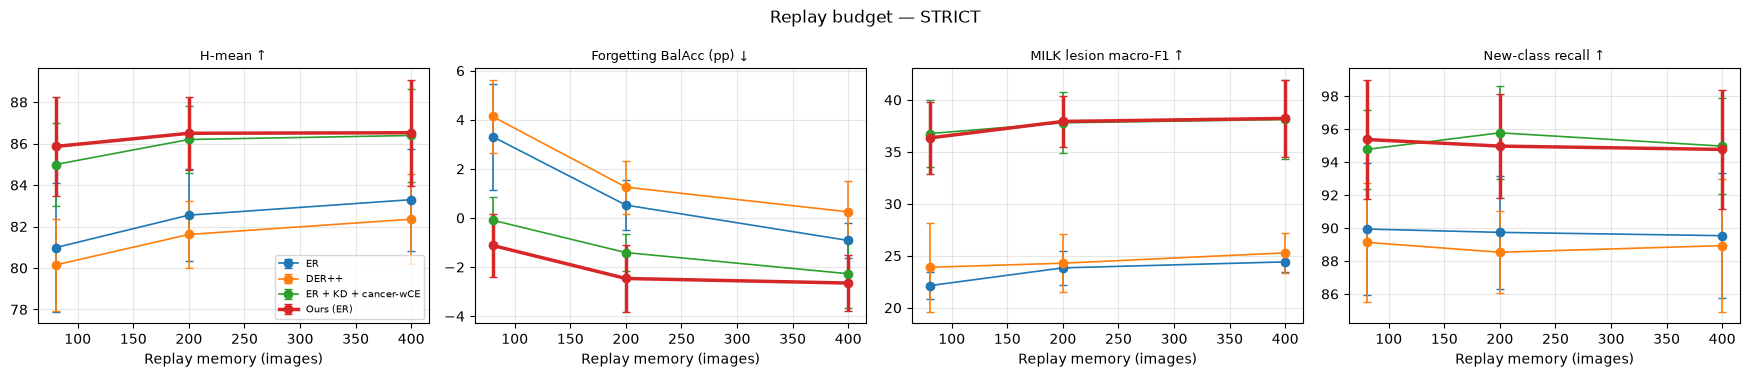

,protocol,method,rpc,n_seeds,h_mean,forgetting_bal_acc_pp,milk_lesion_macro_f1,milk_new_recall
0,STRICT,CancerIL_Full_ER,20.0,7,85.86 ± 2.39,-1.12 ± 1.29,36.34 ± 3.47,95.37 ± 3.61
1,STRICT,CancerIL_Full_ER,50.0,7,86.50 ± 1.75,-2.47 ± 1.36,37.93 ± 2.49,94.97 ± 3.13
2,STRICT,CancerIL_Full_ER,100.0,7,86.52 ± 2.55,-2.65 ± 1.14,38.22 ± 3.69,94.77 ± 3.61
3,STRICT,DERpp,20.0,7,80.15 ± 2.23,4.13 ± 1.49,23.90 ± 4.29,89.13 ± 3.61
4,STRICT,DERpp,50.0,7,81.62 ± 1.63,1.25 ± 1.08,24.29 ± 2.81,88.53 ± 2.50
5,STRICT,DERpp,100.0,7,82.35 ± 2.17,0.25 ± 1.27,25.29 ± 1.93,88.93 ± 4.02
6,STRICT,ER,20.0,7,80.98 ± 3.10,3.31 ± 2.16,22.13 ± 1.30,89.94 ± 4.02
7,STRICT,ER,50.0,7,82.55 ± 2.20,0.52 ± 1.02,23.84 ± 1.61,89.74 ± 3.42
8,STRICT,ER,100.0,7,83.29 ± 2.46,-0.92 ± 0.72,24.42 ± 0.99,89.54 ± 3.80
9,STRICT,ER_KD_CancerWCE,20.0,7,84.99 ± 1.98,-0.09 ± 0.94,36.76 ± 3.24,94.77 ± 2.40


In [42]:
bud = runsB[(runsB["protocol"].isin(BUDGET_PROTOCOLS)) & (runsB["method"].isin(BUDGET_METHODS))
            & (((runsB["family"] == "budget")) | ((runsB["family"] == "main") & (runsB["rpc"] == REPLAY_PER_CLASS)))]
BUD_METRICS = [("h_mean", "H-mean ↑"), ("forgetting_bal_acc_pp", "Forgetting BalAcc (pp) ↓"),
               ("milk_lesion_macro_f1", "MILK lesion macro-F1 ↑"), ("milk_new_recall", "New-class recall ↑")]
if len(bud):
    agg = bud.groupby(["protocol", "method", "rpc"])[[c for c, _ in BUD_METRICS]].agg(["mean", "std", "count"])
    agg.columns = [f"{a}_{b}" for a, b in agg.columns]
    agg = agg.reset_index()
    agg.to_csv(RESULT_DIR / "paper_B_budget.csv", index=False)
    for protocol in BUDGET_PROTOCOLS:
        a = agg[agg["protocol"] == protocol]
        fig, axs = plt.subplots(1, len(BUD_METRICS), figsize=(4.4 * len(BUD_METRICS), 3.8))
        for ax, (c, lab) in zip(axs, BUD_METRICS):
            for m in BUDGET_METHODS:
                b = a[a["method"] == m].sort_values("rpc")
                if b.empty:
                    continue
                k = 1.0 if c.endswith("_pp") else 100.0
                ax.errorbar(b["rpc"] * len(OLD_CLASSES), b[f"{c}_mean"] * k, yerr=np.nan_to_num(b[f"{c}_std"]) * k,
                            marker="o", capsize=3, label=DISPLAY_NAMES.get(m, m),
                            linewidth=2.5 if m == PRIMARY_B else 1.2)
            ax.set_xlabel("Replay memory (images)")
            ax.set_title(lab, fontsize=9)
            ax.grid(alpha=0.3)
        axs[0].legend(fontsize=7)
        fig.suptitle(f"Replay budget — {protocol}")
        plt.tight_layout()
        fig.savefig(FIG_DIR / f"partB_budget_{protocol}.png", dpi=300, bbox_inches="tight")
        plt.show()
    show = agg.copy()
    for c, _ in BUD_METRICS:
        k = 1.0 if c.endswith("_pp") else 100.0
        show[c] = [f"{m * k:.2f} ± {s * k:.2f}" for m, s in zip(show[f"{c}_mean"], show[f"{c}_std"])]
    display(show[["protocol", "method", "rpc", "h_mean_count"] + [c for c, _ in BUD_METRICS]]
            .rename(columns={"h_mean_count": "n_seeds"}))
else:
    print("No budget runs yet (run B6).")

## B14. Selection-rule robustness

In [43]:
SEL_METRICS = ["h_mean", "forgetting_bal_acc_pp", "milk_new_recall", "milk_lesion_macro_f1", "milk_lesion_bal_acc"]
sel_alt = runsB[runsB["family"] == "selection"]
sel_base = runsB[(runsB["family"] == "main") & runsB["method"].isin(SELECTION_METHODS) & runsB["protocol"].isin(SELECTION_PROTOCOLS)]
if len(sel_alt):
    both = pd.concat([sel_base.assign(rule=SELECTION), sel_alt.assign(rule=ALT_SELECTION)])
    g = both.groupby(["protocol", "method", "rule"])[SEL_METRICS].agg(["mean", "std"])
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    g = g.reset_index()
    g.to_csv(RESULT_DIR / "paper_B_selection_robustness.csv", index=False)
    for protocol in SELECTION_PROTOCOLS:
        t = g[g["protocol"] == protocol]
        show = {}
        for m in [x for x in SELECTION_METHODS if x in set(t["method"])]:
            row = {}
            for met in SEL_METRICS:
                k = 1.0 if met.endswith("_pp") else 100.0
                for rule in [SELECTION, ALT_SELECTION]:
                    q = t[(t["method"] == m) & (t["rule"] == rule)]
                    row[f"{met} [{rule}]"] = (f"{q[f'{met}_mean'].iloc[0] * k:.2f} ± {q[f'{met}_std'].iloc[0] * k:.2f}"
                                              if len(q) else "–")
            show[DISPLAY_NAMES.get(m, m)] = row
        print(f"\n==== {protocol}: selection rule {SELECTION!r} vs {ALT_SELECTION!r} (×100 except forgetting in pp) ====")
        display(pd.DataFrame(show).T)
        for m in ["h_mean", "milk_lesion_macro_f1"]:
            x = t[t["rule"] == SELECTION].set_index("method")[f"{m}_mean"]
            y = t[t["rule"] == ALT_SELECTION].set_index("method")[f"{m}_mean"]
            common = x.index.intersection(y.index)
            if len(common) >= 4:
                tau, p = stats.kendalltau(x[common], y[common])
                top_a, top_b = x[common].idxmax(), y[common].idxmax()
                print(f"  {m}: Kendall tau between rules = {tau:.3f} (p={p:.3f}) | best under {SELECTION}: "
                      f"{DISPLAY_NAMES.get(top_a, top_a)} | best under {ALT_SELECTION}: {DISPLAY_NAMES.get(top_b, top_b)}")
else:
    print("No selection-robustness runs yet (run B7).")


==== STRICT: selection rule 'joint_val' vs 'new_only' (×100 except forgetting in pp) ====


,h_mean [joint_val],h_mean [new_only],forgetting_bal_acc_pp [joint_val],forgetting_bal_acc_pp [new_only],milk_new_recall [joint_val],milk_new_recall [new_only],milk_lesion_macro_f1 [joint_val],milk_lesion_macro_f1 [new_only],milk_lesion_bal_acc [joint_val],milk_lesion_bal_acc [new_only]
Fine-tuning,7.26 ± 7.82,38.97 ± 0.45,17.64 ± 4.23,52.07 ± 1.99,4.23 ± 5.14,89.54 ± 3.71,31.23 ± 1.28,19.33 ± 0.08,34.25 ± 1.26,36.47 ± 0.62
LwF,69.47 ± 6.84,71.13 ± 3.69,17.50 ± 2.88,19.70 ± 3.54,84.71 ± 15.09,93.96 ± 3.42,31.15 ± 3.68,29.40 ± 1.70,41.99 ± 1.74,42.49 ± 1.36
EWC,64.18 ± 2.58,64.01 ± 2.19,21.68 ± 4.29,22.02 ± 4.02,77.26 ± 8.62,77.46 ± 8.64,41.10 ± 1.36,40.83 ± 1.22,47.51 ± 1.09,47.31 ± 0.97
LwF + cancer-wCE,71.50 ± 4.13,70.29 ± 4.25,17.78 ± 3.00,21.58 ± 5.02,90.34 ± 6.16,96.58 ± 2.28,32.80 ± 4.05,29.14 ± 3.34,43.83 ± 1.91,42.59 ± 2.56
Ours (no replay),72.70 ± 2.51,70.25 ± 4.28,18.18 ± 2.67,21.89 ± 5.32,95.37 ± 3.61,97.59 ± 2.53,30.73 ± 2.69,29.11 ± 2.94,42.85 ± 1.57,42.22 ± 2.18
ER,82.55 ± 2.20,81.45 ± 3.08,0.52 ± 1.02,1.11 ± 1.77,89.74 ± 3.42,87.93 ± 4.05,23.84 ± 1.61,22.73 ± 0.66,38.71 ± 0.77,37.83 ± 0.61
DER++,81.62 ± 1.63,82.18 ± 2.39,1.25 ± 1.08,1.17 ± 0.76,88.53 ± 2.50,89.74 ± 3.22,24.29 ± 2.81,24.64 ± 1.72,38.78 ± 1.39,39.15 ± 1.14
ER + KD + cancer-wCE,86.20 ± 1.62,86.19 ± 1.64,-1.41 ± 0.77,-1.94 ± 1.19,95.77 ± 2.82,94.97 ± 2.92,37.80 ± 2.95,36.89 ± 3.05,47.86 ± 2.16,47.22 ± 2.07
Ours (ER),86.50 ± 1.75,86.70 ± 1.61,-2.47 ± 1.36,-2.52 ± 1.28,94.97 ± 3.13,95.37 ± 2.66,37.93 ± 2.49,37.50 ± 2.96,47.80 ± 1.68,47.60 ± 2.18


  h_mean: Kendall tau between rules = 0.778 (p=0.002) | best under joint_val: Ours (ER) | best under new_only: Ours (ER)
  milk_lesion_macro_f1: Kendall tau between rules = 0.722 (p=0.006) | best under joint_val: EWC | best under new_only: EWC


## B15. Skin-tone fairness on DDI

AUROC per Fitzpatrick group (12 = I–II, 34 = III–IV, 56 = V–VI), and the **gap** (best group − worst group), computed per seed and then averaged. Report it honestly: the gap is a known limitation of dermoscopy-trained models, and a transparent subgroup analysis strengthens a clinical paper.

In [44]:
tone = MB["tone"].rename(columns={"method": "variant"}).merge(
    runsB[["protocol", "variant", "seed", "method", "family"]].drop_duplicates(), on=["protocol", "variant", "seed"], how="left")
tone = tone[tone["family"] == "main"]
FAIR_METHODS = ["Stage1_Only", "Naive_FT", "LwF_CancerWCE", "CancerIL_Full", "ER", "DERpp", "ER_KD_CancerWCE",
                PRIMARY_B, "CancerIL_Full_DERpp", "Joint_UpperBound"]
rows = []
for (protocol, m), g in tone[tone["method"].isin(FAIR_METHODS)].groupby(["protocol", "method"]):
    piv = g.pivot_table(index="seed", columns="skin_tone", values="auroc")
    gap = piv.max(axis=1) - piv.min(axis=1)
    r = {"protocol": protocol, "method": DISPLAY_NAMES.get(m, m), "_order": FAIR_METHODS.index(m), "n_seeds": len(piv)}
    for tcol in piv.columns:
        r[f"AUROC tone {tcol}"] = f"{piv[tcol].mean():.3f} ± {piv[tcol].std(ddof=1):.3f}"
    r["gap (max−min)"] = f"{gap.mean():.3f} ± {gap.std(ddof=1):.3f}"
    rows.append(r)
fair = pd.DataFrame(rows).sort_values(["protocol", "_order"]).drop(columns="_order")
fair.to_csv(RESULT_DIR / "paper_B_ddi_skin_tone_fairness.csv", index=False)
n_per_tone = ddi_df.groupby("skin_tone")["label"].agg(n="size", malignant=lambda s: int((s == "malignant").sum()))
print("DDI group sizes:")
display(n_per_tone)
display(fair)

DDI group sizes:


,n,malignant
skin_tone,,
12,208,49
34,241,74
56,207,48


,protocol,method,n_seeds,AUROC tone 12,AUROC tone 34,AUROC tone 56,gap (max−min)
9,CDI,Stage 1 only,7,0.579 ± 0.053,0.672 ± 0.019,0.606 ± 0.016,0.103 ± 0.041
8,CDI,Fine-tuning,7,0.676 ± 0.033,0.744 ± 0.022,0.633 ± 0.022,0.112 ± 0.028
7,CDI,LwF + cancer-wCE,7,0.660 ± 0.026,0.710 ± 0.019,0.622 ± 0.030,0.090 ± 0.041
0,CDI,Ours (no replay),7,0.659 ± 0.033,0.729 ± 0.026,0.613 ± 0.037,0.120 ± 0.039
4,CDI,ER,7,0.659 ± 0.032,0.731 ± 0.023,0.619 ± 0.021,0.116 ± 0.035
3,CDI,DER++,7,0.642 ± 0.046,0.716 ± 0.029,0.611 ± 0.026,0.115 ± 0.039
5,CDI,ER + KD + cancer-wCE,7,0.644 ± 0.041,0.714 ± 0.029,0.609 ± 0.012,0.112 ± 0.029
2,CDI,Ours (ER),7,0.642 ± 0.037,0.726 ± 0.027,0.608 ± 0.028,0.124 ± 0.041
1,CDI,Ours (DER++),7,0.629 ± 0.036,0.718 ± 0.021,0.607 ± 0.039,0.119 ± 0.048
6,CDI,Joint (offline reference),7,0.635 ± 0.042,0.721 ± 0.023,0.637 ± 0.022,0.096 ± 0.044


## B16. Figures and automatic claims checklist

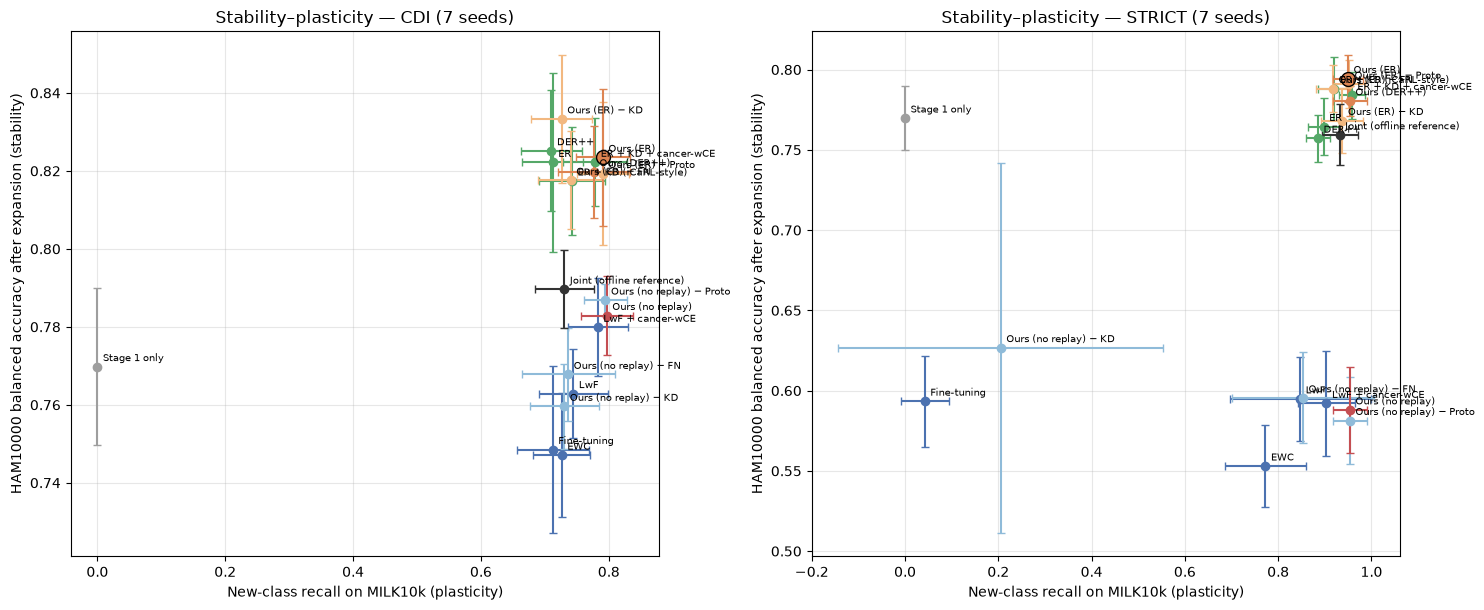

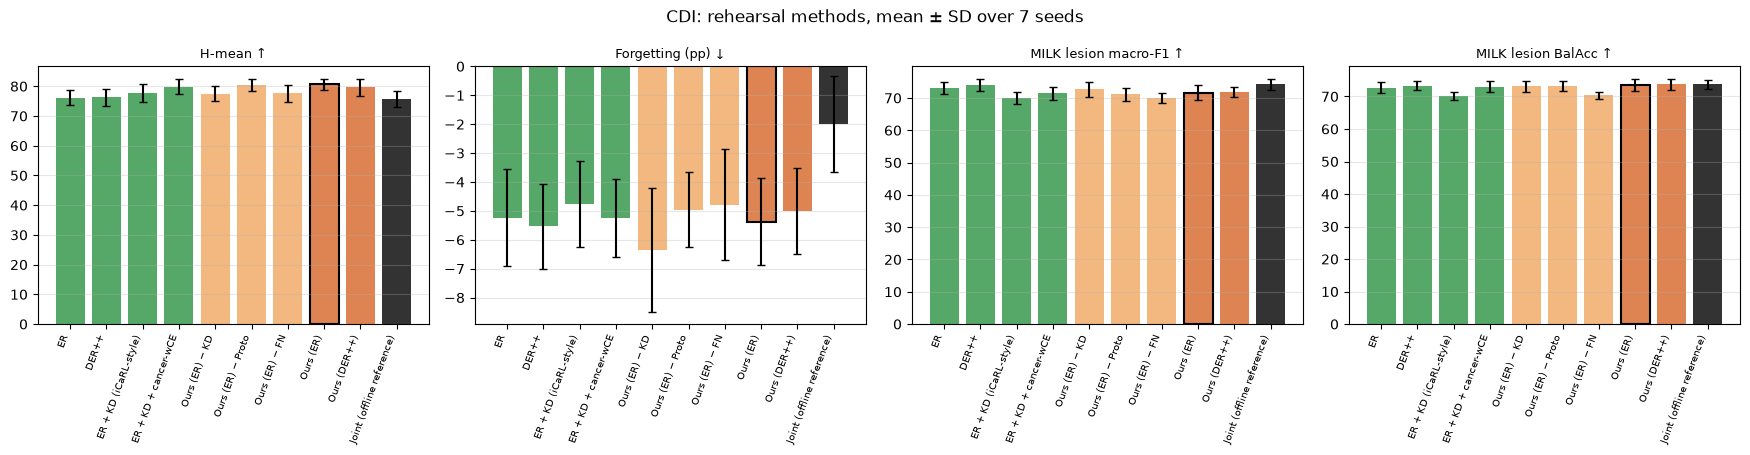

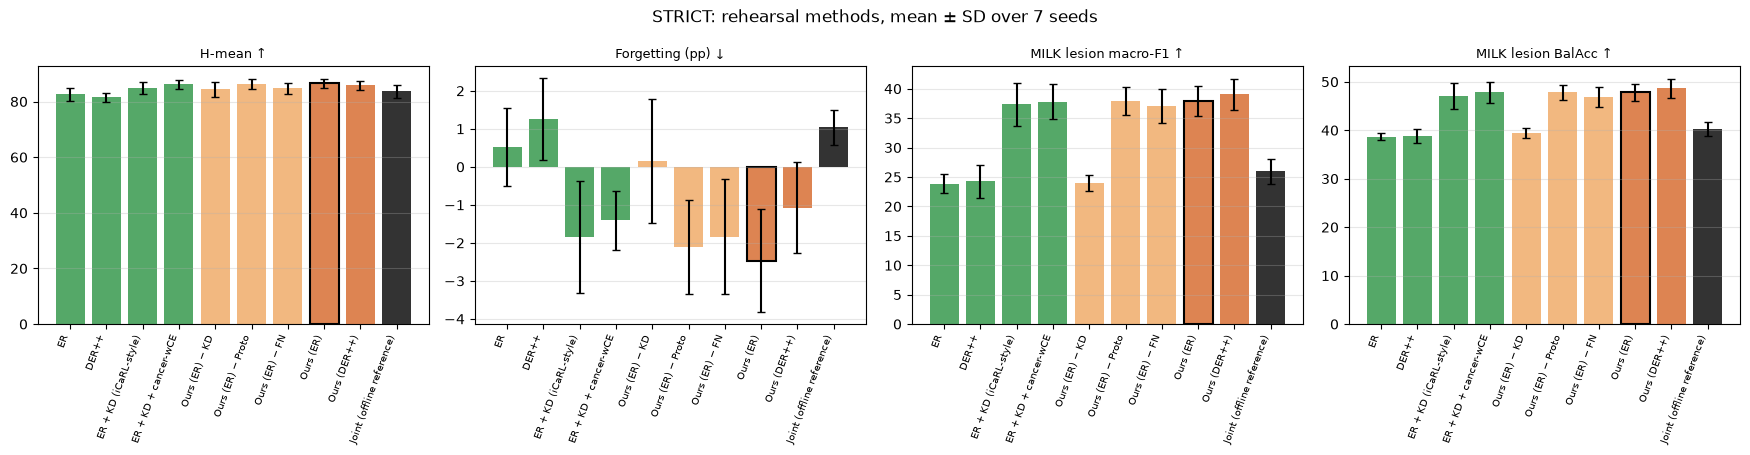


--- primary: Ours (ER) ---
  [SUPPORTED      ] STRICT Ours (ER) vs ER                           h_mean                 Δ=+3.95  95%CI[+2.99,+4.90]  d_z=3.82  p_holm=0.0003  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs ER                           milk_lesion_macro_f1   Δ=+14.09  95%CI[+10.92,+17.26]  d_z=4.11  p_holm=0.0001  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs ER                           milk_lesion_bal_acc    Δ=+9.09  95%CI[+7.28,+10.91]  d_z=4.63  p_holm=0.0001  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs ER                           forgetting_bal_acc_pp  Δ=-2.99  95%CI[-3.62,-2.36]  d_z=-4.37  p_holm=0.0001  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs DER++                        h_mean                 Δ=+4.88  95%CI[+3.46,+6.30]  d_z=3.17  p_holm=0.0006  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs DER++                        milk_lesion_macro_f1   Δ=+13.64  95%CI[+9.03,+18.26]  d_z=2.74  p_holm=0.0011  (n=7)
  [SUPPORTED      ] STRICT Ours (ER) vs DER++        

In [45]:
GROUP_COLORS_B = dict(globals().get("GROUP_COLORS", {
    "Reference": "#9e9e9e", "Exemplar-free baseline": "#4c72b0", "Proposed (ablation)": "#8fbbd9",
    "Proposed": "#c44e52", "Rehearsal": "#55a868", "Proposed + rehearsal": "#dd8452", "Upper bound": "#333333"}))
GROUP_COLORS_B.update({"Proposed + rehearsal (ablation)": "#f2b880"})

# (a) stability-plasticity plane, main family
fig, axs = plt.subplots(1, len(PROTOCOLS), figsize=(7.5 * len(PROTOCOLS), 6.2), squeeze=False)
for ax, protocol in zip(axs[0], PROTOCOLS):
    s = SUMMARY_B[protocol]
    for r in s.itertuples(index=False):
        x, y = r.milk_new_recall_mean, r.ham_post_bal_acc_mean
        ax.errorbar(x, y, xerr=np.nan_to_num(r.milk_new_recall_sd), yerr=np.nan_to_num(r.ham_post_bal_acc_sd), fmt="o",
                    color=GROUP_COLORS_B.get(r.group, "#777"), capsize=3,
                    markersize=10 if r.method == PRIMARY_B else 6, markeredgecolor="k" if r.method == PRIMARY_B else None)
        ax.annotate(r.display, (x, y), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("New-class recall on MILK10k (plasticity)")
    ax.set_ylabel("HAM10000 balanced accuracy after expansion (stability)")
    ax.set_title(f"Stability–plasticity — {protocol} ({len(SEEDS_USED_B[protocol])} seeds)")
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "partB_stability_plasticity.png", dpi=300, bbox_inches="tight")
plt.show()

# (b) bars for the headline metrics, rehearsal block only
REH = ["ER", "DERpp", "ER_KD", "ER_KD_CancerWCE", "ER_Proto_FN", "ER_KD_FN", "ER_KD_Proto", PRIMARY_B,
       "CancerIL_Full_DERpp", "Joint_UpperBound"]
BARS = [("h_mean", "H-mean ↑"), ("forgetting_bal_acc_pp", "Forgetting (pp) ↓"),
        ("milk_lesion_macro_f1", "MILK lesion macro-F1 ↑"), ("milk_lesion_bal_acc", "MILK lesion BalAcc ↑")]
for protocol in PROTOCOLS:
    s = SUMMARY_B[protocol].set_index("method").reindex([m for m in REH if m in set(SUMMARY_B[protocol]["method"])]).reset_index()
    fig, axs = plt.subplots(1, len(BARS), figsize=(4.4 * len(BARS), 4.6))
    for ax, (c, lab) in zip(axs, BARS):
        k = 1.0 if c.endswith("_pp") else 100.0
        x = np.arange(len(s))
        ax.bar(x, s[f"{c}_mean"] * k, yerr=np.nan_to_num(s[f"{c}_sd"]) * k, capsize=3,
               color=[GROUP_COLORS_B.get(g, "#777") for g in s["group"]],
               edgecolor=["k" if m == PRIMARY_B else "none" for m in s["method"]], linewidth=1.5)
        ax.set_xticks(x)
        ax.set_xticklabels(s["display"], rotation=70, ha="right", fontsize=7)
        ax.set_title(lab, fontsize=9)
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle(f"{protocol}: rehearsal methods, mean ± SD over {len(SEEDS_USED_B[protocol])} seeds")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"partB_rehearsal_bars_{protocol}.png", dpi=300, bbox_inches="tight")
    plt.show()

# (c) claims checklist
def claim(fam, protocol, other, metric):
    q = SIG_B[(SIG_B["family"] == fam) & (SIG_B["protocol"] == protocol) & (SIG_B["other"] == other) & (SIG_B["metric"] == metric)]
    if q.empty:
        return None
    r = q.iloc[0]
    status = "SUPPORTED" if (r["significant"] and r["favours_ours"]) else ("REVERSED" if (r["significant"] and not r["favours_ours"]) else "not significant")
    k = 1.0 if metric.endswith("_pp") else 100.0
    return (f"  [{status:15s}] {protocol:6s} {DISPLAY_NAMES.get(r['ours'], r['ours'])} vs {DISPLAY_NAMES.get(other, other):28s} "
            f"{metric:22s} Δ={r['mean_diff'] * k:+.2f}  95%CI[{r['ci_lo'] * k:+.2f},{r['ci_hi'] * k:+.2f}]  "
            f"d_z={r['cohen_dz']:.2f}  p_holm={r['p_ttest_holm']:.4f}  (n={r['n_seeds']})"), status

lines, verdict = [], {}
for fam, (ours, others) in FAMILIES.items():
    lines.append(f"\n--- {fam}: {DISPLAY_NAMES.get(ours, ours)} ---")
    for protocol in RUN_ORDER_PROTOCOLS:
        for o in others:
            for metric in ["h_mean", "milk_lesion_macro_f1", "milk_lesion_bal_acc", "forgetting_bal_acc_pp"]:
                c = claim(fam, protocol, o, metric)
                if c:
                    lines.append(c[0])
                    verdict.setdefault((fam, protocol), []).append(c[1])
txt = "\n".join(lines)
print(txt)
(RESULT_DIR / "partB_claims_checklist.txt").write_text(txt, encoding="utf-8")

print("\n==== Headline claim ====")
for protocol in RUN_ORDER_PROTOCOLS:
    v = verdict.get(("primary", protocol), [])
    q = SIG_B[(SIG_B["family"] == "primary") & (SIG_B["protocol"] == protocol)
              & (SIG_B["metric"].isin(["h_mean", "milk_lesion_macro_f1"])) & (SIG_B["other"] != "Joint_UpperBound")]
    strong = len(q) > 0 and bool((q["significant"] & q["favours_ours"]).all())
    print(f"  {protocol}: Ours(ER) significantly beats every rehearsal baseline on H-mean AND MILK macro-F1 -> "
          f"{'YES' if strong else 'NO'}  ({sum(x == 'SUPPORTED' for x in v)}/{len(v)} primary checks supported)")
    a = SIG_B[(SIG_B["family"] == "ablation") & (SIG_B["protocol"] == protocol) & (SIG_B["metric"] == "h_mean")]
    for r in a.itertuples(index=False):
        term = {"ER_Proto_FN": "KD", "ER_KD_FN": "Proto", "ER_KD_Proto": "FN"}[r.other]
        print(f"     removing {term:5s}: Δ H-mean {r.mean_diff * 100:+.2f} pp, p_holm={r.p_ttest_holm:.4f} -> "
              f"{'component helps' if (r.significant and r.favours_ours) else 'no significant contribution'}")

## B17. How to write the paper from Part B

**Framing.** Present `CancerIL_Full_ER` (plus `CancerIL_Full_DERpp` if B11 "generality" is supported) as the method: a *cancer-aware distillation objective for rehearsal-based class-incremental skin-cancer classification*. Present the exemplar-free `CancerIL_Full` honestly as an ablation. Present CDI vs STRICT as a **benchmark finding**: the commonly used HAM→MILK setting (CDI) barely exhibits forgetting, while STRICT exposes 17–18 pp forgetting that no exemplar-free method prevents.

**Use the checklist (`partB_claims_checklist.txt`) literally.** Write "significantly better" only for `SUPPORTED` lines. Write "comparable" for `not significant`. Report any `REVERSED` line as a limitation.

**Components.** Keep a term in the method only if its ablation line in B16 says "component helps" in STRICT. If a term does not help, either drop it from the method (and say so) or keep it and state that its contribution was not significant. Do not claim it does.

**Tables.** Main: `paper_B_table_STRICT.tex` and `paper_B_table_CDI.tex`. Ablation: `paper_B_ablation_*.csv`. Budget: `partB_budget_STRICT.png`. Robustness: `paper_B_selection_robustness.csv` (appendix). Fairness: `paper_B_ddi_skin_tone_fairness.csv`. Significance: `partB_significance_preregistered.csv` and `partB_delong_ddi_ensemble.csv`.

**Disclose.** (1) λs were tuned on validation for the exemplar-free objective and reused unchanged with replay. (2) The normalised-Fisher EWC and its λ grid (`tuning_log_ewc_norm_*.csv`); the original EWC is in the appendix. (3) Herding exemplars, replay batch 16, budgets 80/200/400 images. (4) "Joint" is an offline reference, **not** an upper bound on MILK metrics (old MILK cancer classes are absent from its Stage-2 data in STRICT). (5) The selection rule, and that conclusions were re-checked under MILK-val-only selection. (6) Pre-registered comparison families and Holm correction. (7) MAL_OTH exclusion, lesion-level MILK evaluation, and DDI as external validation.

# PART C — Generalisation and mechanism (added after Part B)

Part B established the findings on EfficientNet-B3. Part C shows that they **do not depend on the backbone**, fixes the EWC grid, and adds the **mechanistic analyses** that turn a benchmark into a publishable study. Nothing from Parts A/B is retrained. Only the EWC runs whose λ changes are re-run.

| Cell | What it does | New GPU work |
|---|---|---|
| C1 | Configuration | – |
| C2 | EWC grid widened (adds 0.01 and 10⁴; auto-extends until the best λ is **inside** the grid) + re-runs EWC if λ changes | ~4–8 tuning runs + ~21 re-runs (~3 h) |
| C3 | Backbone support (ConvNeXt-Tiny, Swin-T), CKA and Grad-CAM tools | – |
| C4 | **Self-test**: one training step per backbone, VRAM check, CKA/Grad-CAM check (~3 min) | – |
| C5 | **Cross-domain forgetting** analysis: source-domain forgetting vs old-class performance in the new domain (the key finding) | – |
| C6 | **Representation drift (linear CKA)**: explains *why* distillation matters | ~30 min inference |
| C7 | Compute-cost table (time, VRAM, memory, parameters) | – |
| C8 | **Second and third backbones**: Stage 1 + 10 methods × 2 protocols × 5 seeds per backbone | ~15–20 h per backbone |
| C9 | **Cross-backbone replication table** (the table that answers "does it depend on the backbone?") + per-backbone tables and LaTeX | – |
| C10 | Grad-CAM qualitative figure (ER vs recommended recipe) | ~1 min |

The recommended method is now **ER + KD + FN** (`ER_KD_FN`). Part B showed that the prototype term adds nothing, so it is dropped from the method and kept only as an ablation.

## C1. Part-C configuration

In [36]:
BASE_ARCH = "efficientnet_b3"
BACKBONES_C = ["convnext_tiny", "swin_t"]          # run order; remove "swin_t" to do only one extra backbone
_IMG_BASE = _ORIG_C["IMG_SIZE"] if "_ORIG_C" in globals() else IMG_SIZE
ARCH_IMG = {"efficientnet_b3": int(_IMG_BASE), "convnext_tiny": 224, "swin_t": 224}   # each backbone at its native ImageNet resolution
ARCH_LR_S1 = {"convnext_tiny": (1e-4, 1e-3), "swin_t": (1e-4, 1e-3)}                # (backbone, head) Stage-1 LR; Stage 2 uses LR_BACKBONE_S2 / LR_HEAD_S2 for all
ARCH_PROTOCOLS = ["STRICT", "CDI"]
ARCH_SEEDS = list(SEEDS)                          # 5 replicates per extra backbone
ARCH_METHODS = ["Naive_FT", "LwF", "LwF_CancerWCE", "ER", "DERpp", "ER_KD", "ER_KD_CancerWCE",
                "ER_KD_FN", "CancerIL_Full_ER", "Joint_UpperBound"]
GRAD_CHECKPOINT_C = False                         # set True only if C4 reports VRAM > ~11 GB

EWC_EXTRA_VALUES = [0.01, 1e4]
EWC_MAX_EXTENSIONS = 2                            # further x10 steps if the best lambda is still at the edge

RECOMMENDED = "ER_KD_FN"
CKA_METHODS = ["Naive_FT", "LwF", "LwF_CancerWCE", "ER", "DERpp", "ER_KD", "ER_KD_CancerWCE",
               "ER_KD_FN", "CancerIL_Full_ER", "Joint_UpperBound"]
CKA_SEEDS = list(ALL_SEEDS)
CKA_MAX_IMAGES = 1000
GRADCAM_SEED, GRADCAM_PROTOCOL, GRADCAM_N = SEEDS[0], "STRICT", 6

if SMOKE_TEST:
    ARCH_SEEDS = SEEDS[:1]
    CKA_SEEDS = SEEDS[:1]
    CKA_MAX_IMAGES = 200

DISPLAY_C = dict(DISPLAY_NAMES)
DISPLAY_C.update({"ER_KD_FN": "ER + KD + FN (recommended)", "CancerIL_Full_ER": "ER + KD + FN + Proto",
                  "efficientnet_b3": "EfficientNet-B3", "convnext_tiny": "ConvNeXt-T", "swin_t": "Swin-T"})
OLD_CANCER = [c for c in OLD_CLASSES if c != "non-cancer"]
print("Extra backbones:", BACKBONES_C, "| seeds:", ARCH_SEEDS, "| methods:", len(ARCH_METHODS))

Extra backbones: ['convnext_tiny', 'swin_t'] | seeds: [42, 1337, 2026, 7, 314] | methods: 10


## C2. EWC: widen the λ grid until the optimum is inside it

In Part B the selected λ sat at the grid edge (CDI 0.1, STRICT 1000). This cell adds 0.01 and 10⁴ and, if the best value is still at an edge, extends by ×10 (up to `EWC_MAX_EXTENSIONS` times). Selection is on validation only, as before. EWC is then re-run for all 7 seeds (main table and selection-robustness family) **only if its λ changed**.

In [37]:
def _ewc_val(protocol, v):
    vals, keys = [], []
    for s in TUNE_SEEDS:
        summ = run_stage2(protocol, s, spec_ext(ewc=float(v), ewc_norm=True), tag=f"tune:ewc_norm={v:g}")
        vals.append(summ["best_val_score"])
        keys.append(summ["key"])
    return float(np.mean(vals)), keys


EWC_NORM_HP_PARTB = dict(EWC_NORM_HP)
ewc_rows = []
for protocol in PROTOCOLS:
    scores = {}
    for v in sorted(set(float(x) for x in EWC_NORM_GRID) | set(float(x) for x in EWC_EXTRA_VALUES)):
        scores[v], _ = _ewc_val(protocol, v)
    for _ in range(EWC_MAX_EXTENSIONS):
        best = max(scores, key=scores.get)
        if best == min(scores):
            new = best / 10.0
        elif best == max(scores):
            new = best * 10.0
        else:
            break
        scores[new], _ = _ewc_val(protocol, new)
    best = max(scores, key=scores.get)
    interior = min(scores) < best < max(scores)
    EWC_NORM_HP[protocol] = best
    for v, sc in sorted(scores.items()):
        ewc_rows.append({"protocol": protocol, "lambda": v, "val_score": sc, "selected": v == best})
    with open(RESULT_DIR / f"tuned_ewc_norm_{protocol}.json", "w", encoding="utf-8") as f:
        json.dump({"ewc_norm_lambda": best, "scores": {str(k): v for k, v in scores.items()},
                   "interior_optimum": bool(interior), "partB_lambda": EWC_NORM_HP_PARTB.get(protocol)}, f, indent=2)
    print(f"[{protocol}] " + "  ".join(f"{k:g}->{s:.4f}" for k, s in sorted(scores.items()))
          + f"  | selected {best:g} (Part B: {EWC_NORM_HP_PARTB.get(protocol):g}) | "
          + ("interior optimum" if interior else "STILL AT EDGE after extensions: report as a limitation"))
pd.DataFrame(ewc_rows).to_csv(RESULT_DIR / "tuning_log_ewc_norm_widened.csv", index=False)

ewc_plan = [p for p in plan_main_B(ALL_SEEDS) + plan_selection(ALL_SEEDS) if p["method"] == "EWC_Norm"]
execute_plan(ewc_plan, "C2 EWC re-runs (only runs whose lambda changed)")
print("EWC_NORM_HP =", EWC_NORM_HP, "\n-> Re-run B9-B16 later so the Part-B tables use the final EWC.")

[done] CDI    | tune:ewc_norm=0.01             | seed 42 | val=0.6864 | 16 ep | 11.8 min | peak 5.4 GB


[done] CDI    | tune:ewc_norm=10000            | seed 42 | val=0.4375 | 9 ep | 6.6 min | peak 5.4 GB


[done] CDI    | tune:ewc_norm=0.001            | seed 42 | val=0.6912 | 16 ep | 11.3 min | peak 5.4 GB


[done] CDI    | tune:ewc_norm=0.0001           | seed 42 | val=0.6929 | 16 ep | 11.3 min | peak 5.4 GB
[CDI] 0.0001->0.6929  0.001->0.6912  0.01->0.6864  0.1->0.6747  1->0.6621  10->0.6318  100->0.5792  1000->0.5343  10000->0.4375  | selected 0.0001 (Part B: 0.1) | STILL AT EDGE after extensions: report as a limitation


[done] STRICT | tune:ewc_norm=0.01             | seed 42 | val=0.5650 | 9 ep | 2.9 min | peak 5.4 GB


...

[done] STRICT | EWC_Norm@sel:new_only          | seed 2718 | val=0.7283 | 30 ep | 7.7 min | peak 5.62 GB
   ... 15/19 done | 2.19 h elapsed | ~0.6 h left


[done] CDI    | EWC_Norm                       | seed 2718 | val=0.7001 | 19 ep | 13.4 min | peak 5.62 GB


[done] STRICT | EWC_Norm                       | seed 99 | val=0.6641 | 29 ep | 8.2 min | peak 5.63 GB


[done] STRICT | EWC_Norm@sel:new_only          | seed 99 | val=0.7344 | 29 ep | 7.4 min | peak 5.62 GB


[done] CDI    | EWC_Norm                       | seed 99 | val=0.7224 | 16 ep | 11.5 min | peak 5.62 GB
   ... 19/19 done | 2.87 h elapsed | ~0.0 h left
C2 EWC re-runs (only runs whose lambda changed): finished (2.87 h this session)
EWC_NORM_HP = {'CDI': 0.0001, 'STRICT': 10000.0} 
-> Re-run B9-B16 later so the Part-B tables use the final EWC.


## C3. Backbone support, CKA and Grad-CAM tools

The two extra backbones are torchvision ImageNet models (no extra packages): **ConvNeXt-Tiny** (modern CNN) and **Swin-T** (vision transformer). Each runs at its native 224 px resolution. Everything else is **identical** to EfficientNet-B3: the GPU augmentation, the cached images, the losses, the λ values tuned on B3 (not re-tuned, which is conservative for our method), the EMA, the early stopping and the metrics.

`arch_context(arch)` temporarily switches the input size, model builder, Stage-1 resources and Stage-1 predictions to the chosen backbone and restores everything afterwards, even after an error. Run keys include the backbone, so nothing collides with the B3 runs.

In [46]:
import torch.utils.checkpoint as tuc
from contextlib import contextmanager

if "_ORIG_C" not in globals():
    _ORIG_C = {"IMG_SIZE": IMG_SIZE, "get_seed_resources": get_seed_resources,
               "expand_classifier": expand_classifier, "stage1_preds": stage1_preds}
else:
    globals().update(_ORIG_C)       # restore, in case an earlier context was interrupted


class ArchModel(nn.Module):
    """Same interface as CancerILModel: .features, .classifier, .embed_dim, forward(x, return_embedding)."""

    def __init__(self, arch, num_classes, pretrained=True, grad_ckpt=False):
        super().__init__()
        if arch == "convnext_tiny":
            m = tv_models.convnext_tiny(weights=tv_models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
            self.features = nn.Sequential(*m.features, m.avgpool, m.classifier[0])
            dim = m.classifier[2].in_features
        elif arch == "swin_t":
            m = tv_models.swin_t(weights=tv_models.Swin_T_Weights.DEFAULT if pretrained else None)
            self.features = nn.Sequential(*m.features, m.norm, m.permute, m.avgpool)
            dim = m.head.in_features
        else:
            raise ValueError(arch)
        self.arch, self.embed_dim, self.grad_ckpt = arch, dim, bool(grad_ckpt)
        self.dropout = nn.Dropout(p=0.3)
        self.classifier = nn.Linear(dim, num_classes)

    def forward(self, x, return_embedding=False):
        if self.grad_ckpt and self.training and torch.is_grad_enabled():
            f = tuc.checkpoint_sequential(self.features, 4, x, use_reentrant=False)
        else:
            f = self.features(x)
        pooled = torch.flatten(f, 1)
        logits = self.classifier(self.dropout(pooled))
        return (logits, pooled) if return_embedding else logits


def build_model_arch(arch, num_classes, pretrained):
    return ArchModel(arch, num_classes, pretrained, GRAD_CHECKPOINT_C).to(device).to(memory_format=MEMORY_FORMAT)


def expand_classifier_arch(old_model, old_classes, new_classes, arch):
    new_model = ArchModel(arch, len(new_classes), pretrained=False, grad_ckpt=GRAD_CHECKPOINT_C)
    new_model.features.load_state_dict(old_model.features.state_dict())
    with torch.no_grad():
        for j, c in enumerate(new_classes):
            if c in old_classes:
                i = old_classes.index(c)
                new_model.classifier.weight[j].copy_(old_model.classifier.weight[i])
                new_model.classifier.bias[j].copy_(old_model.classifier.bias[i])
    return new_model.to(device).to(memory_format=MEMORY_FORMAT)


def _arch_prefix(arch, seed):
    return f"stage1_{STAGE1_TAG}_{arch}_seed{seed}"


def _assert_ctx(arch):
    assert globals()["IMG_SIZE"] == ARCH_IMG[arch], f"call inside arch_context({arch!r})"


def train_stage1_arch(arch, seed):
    _assert_ctx(arch)
    ckpt, pred_path = CKPT_DIR / f"{_arch_prefix(arch, seed)}.pt", PRED_DIR / f"{_arch_prefix(arch, seed)}.npz"
    if ckpt.exists():
        model = build_model_arch(arch, len(HAM_CLASSES), pretrained=False)
        model.load_state_dict(load_state_dict_compat(ckpt))
        print(f"Loaded Stage-1 {arch} checkpoint for seed {seed}")
    else:
        set_seed(seed)
        model = build_model_arch(arch, len(HAM_CLASSES), pretrained=USE_IMAGENET_WEIGHTS)
        tr = maybe_subsample(ham_train_df, seed)
        y_tr = tr["label"].map(HAM_CLASSES.index).values
        y_val = ham_val_df["label"].map(HAM_CLASSES.index).values
        loader = GPUBatcher(tr["gidx"].values, y_tr, BATCH_SIZE, shuffle=True, drop_last=True, seed=seed)
        cw = class_weights_for(y_tr, len(HAM_CLASSES))

        def compute_loss(m, x, y, gen):
            ce = F.cross_entropy(m(x).float(), y, weight=cw)
            return ce, {"ce": ce}

        def val_fn(m):
            s = multiclass_summary(predict_probs(m, ham_val_df["gidx"].values), y_val, HAM_CLASSES)
            return s["macro_f1"], {"acc": s["acc"], "bal_acc": s["bal_acc"], "macro_f1": s["macro_f1"]}

        lr_b, lr_h = ARCH_LR_S1[arch]
        model, hist, best, info, peak = fit(model, loader, compute_loss, val_fn, epochs=STAGE1_EPOCHS,
                                            patience=STAGE1_PATIENCE, lr_backbone=lr_b, lr_head=lr_h, seed=seed,
                                            desc=f"Stage1 {arch} s{seed}", verbose=False)
        torch.save(model.state_dict(), ckpt)
        hist.to_csv(RESULT_DIR / f"stage1_history_{STAGE1_TAG}_{arch}_seed{seed}.csv", index=False)
        print(f"Stage 1 {arch} seed {seed}: best HAM-val macro-F1 = {best:.4f} | {len(hist)} ep | peak VRAM {peak:.2f} GB")
    if not pred_path.exists():
        split = make_milk_split(seed)
        np.savez_compressed(pred_path, **{
            "ham_val": predict_probs(model, ham_val_df["gidx"].values, tta=EVAL_TTA),
            "ham_test": predict_probs(model, ham_test_df["gidx"].values, tta=EVAL_TTA),
            "milk_val": predict_probs(model, split["val"]["gidx"].values, tta=EVAL_TTA),
            "milk_test": predict_probs(model, split["test"]["gidx"].values, tta=EVAL_TTA),
            "ddi": predict_probs(model, ddi_df["gidx"].values, tta=EVAL_TTA),
        })
    del model
    gc.collect()
    torch.cuda.empty_cache()


_ARCH_RES, _ARCH_S1 = {}, {}


def get_arch_resources(arch, seed):
    _assert_ctx(arch)
    k = (arch, seed)
    if k in _ARCH_RES:
        return _ARCH_RES[k]
    _ARCH_RES.clear()
    _SEED_CACHE.clear()
    gc.collect()
    torch.cuda.empty_cache()
    stage1 = build_model_arch(arch, len(HAM_CLASSES), pretrained=False)
    stage1.load_state_dict(load_state_dict_compat(CKPT_DIR / f"{_arch_prefix(arch, seed)}.pt"))
    stage1.eval()
    for p in stage1.parameters():
        p.requires_grad_(False)
    proto_path = CKPT_DIR / f"{_arch_prefix(arch, seed)}_prototypes.npz"
    buffer_path = CKPT_DIR / f"{_arch_prefix(arch, seed)}_herding_buffer.csv"
    if not (proto_path.exists() and buffer_path.exists()):
        emb = extract_embeddings(stage1, ham_train_df["gidx"].values).cpu().numpy()
        labels = ham_train_df["label"].values
        np.savez(proto_path, **{c: emb[labels == c].mean(0) for c in HAM_CLASSES})
        rows = []
        for c in HAM_CLASSES:
            idx = np.where(labels == c)[0]
            f = emb[idx] / np.clip(np.linalg.norm(emb[idx], axis=1, keepdims=True), 1e-12, None)
            for j in herding_select(f, min(REPLAY_PER_CLASS, len(idx))):
                rows.append({"gidx": int(ham_train_df["gidx"].values[idx[j]]), "label": c})
        pd.DataFrame(rows).to_csv(buffer_path, index=False)
    protos = np.load(proto_path)
    proto_mat = torch.zeros(len(MILK_CLASSES), stage1.embed_dim, device=device)
    has_proto = torch.zeros(len(MILK_CLASSES), dtype=torch.bool, device=device)
    for c in HAM_CLASSES:
        i = MILK_CLASSES.index(c)
        proto_mat[i] = torch.as_tensor(protos[c], device=device)
        has_proto[i] = True
    buf = pd.read_csv(buffer_path)
    res = SimpleNamespace(seed=seed, stage1=stage1, proto_mat=proto_mat, has_proto=has_proto.float(),
                          buffer=GPUReplayBuffer(buf["gidx"].values, buf["label"].map(MILK_CLASSES.index).values),
                          split=make_milk_split(seed), fisher=None)
    _ARCH_RES[k] = res
    return res


def arch_stage1_preds(arch, seed):
    k = (arch, seed)
    if k not in _ARCH_S1:
        z = np.load(PRED_DIR / f"{_arch_prefix(arch, seed)}.npz")
        _ARCH_S1[k] = {kk: pad_to_milk(z[kk]) for kk in z.files}
    return _ARCH_S1[k]


@contextmanager
def arch_context(arch):
    g = globals()
    if arch in (None, BASE_ARCH):
        yield
        return
    g["IMG_SIZE"] = ARCH_IMG[arch]
    g["get_seed_resources"] = lambda seed: get_arch_resources(arch, seed)
    g["expand_classifier"] = lambda old, oc, nc: expand_classifier_arch(old, oc, nc, arch)
    g["stage1_preds"] = lambda seed: arch_stage1_preds(arch, seed)
    try:
        yield
    finally:
        g.update(_ORIG_C)
        _ARCH_RES.clear()
        gc.collect()
        torch.cuda.empty_cache()


def arch_spec(sp, arch):
    s = dict(sp)
    s["arch"], s["img"], s["s1lr"] = arch, int(ARCH_IMG[arch]), [float(v) for v in ARCH_LR_S1[arch]]
    return s


def plan_arch(arch, seeds):
    out = []
    for protocol in ARCH_PROTOCOLS:
        base = build_methods_B(protocol)
        for name in ARCH_METHODS:
            sp = arch_spec(base[name], arch)
            for seed in seeds:
                out.append({"arch": arch, "protocol": protocol, "method": name, "seed": seed, "spec": sp,
                            "key": run_key(protocol, seed, sp), "tag": f"{arch}:{name}"})
    return out


def collect_arch_metrics(arch, seeds):
    plan = plan_arch(arch, seeds)
    entries = [{"protocol": p["protocol"], "method": p["method"], "seed": p["seed"], "key": p["key"]}
               for p in plan if (PRED_DIR / f"{p['key']}.npz").exists()]
    st1 = [s for s in seeds if (PRED_DIR / f"{_arch_prefix(arch, s)}.npz").exists()]
    entries += [{"protocol": p, "method": "Stage1_Only", "seed": s, "key": "stage1"} for p in ARCH_PROTOCOLS for s in st1]
    if not entries:
        return None
    with arch_context(arch):
        M = collect_metrics(entries)
    for k in M:
        if len(M[k]):
            M[k]["arch"] = arch
    return M


# ---------- representation similarity ----------
def linear_cka(X, Y):
    X, Y = X.double(), Y.double()
    X = X - X.mean(0, keepdim=True)
    Y = Y - Y.mean(0, keepdim=True)
    hsic = (Y.T @ X).pow(2).sum()
    return float(hsic / ((X.T @ X).pow(2).sum().sqrt() * (Y.T @ Y).pow(2).sum().sqrt()).clamp(min=1e-12))


# ---------- Grad-CAM (EfficientNet-B3: spatial map at the end of .features) ----------
def gradcam(model, gidx, targets):
    model.eval()
    store = {}
    h = model.features.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    try:
        x = gpu_eval_preprocess(EVAL_STAGER.fetch(torch.as_tensor(np.asarray(gidx, dtype=np.int64)))).float()
        with torch.enable_grad():
            logits = model(x).float()
            a = store["a"]
            t = torch.as_tensor(np.asarray(targets, dtype=np.int64), device=device).view(-1, 1)
            grads = torch.autograd.grad(logits.gather(1, t).sum(), a)[0]
    finally:
        h.remove()
    w = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam / cam.amax(dim=(2, 3), keepdim=True).clamp(min=1e-8)
    img = (x * IMAGENET_STD_T + IMAGENET_MEAN_T).clamp(0, 1).permute(0, 2, 3, 1)
    return cam[:, 0].detach().float().cpu().numpy(), logits.softmax(1).detach().cpu().numpy(), img.detach().float().cpu().numpy()


def load_stage2_b3(key):
    m = build_model(len(MILK_CLASSES), pretrained=False)
    m.load_state_dict(load_state_dict_compat(CKPT_DIR / "stage2" / f"{key}.pt"))
    return m.eval()


print("Backbone support ready:", BACKBONES_C)

Backbone support ready: ['convnext_tiny', 'swin_t']


## C4. Self-test (about 3 minutes)

For each extra backbone, this builds the model (and downloads the ImageNet weights the first time), runs three Stage-2-style training steps with a batch of 32 + 16 replay images and a frozen teacher, and reports the time per step and the **peak VRAM**. It also checks the CKA and Grad-CAM tools on real checkpoints. Nothing is saved.

In [47]:
ok_all = True
for arch in BACKBONES_C:
    with arch_context(arch):
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        student = build_model_arch(arch, len(MILK_CLASSES), pretrained=True)
        teacher = build_model_arch(arch, len(HAM_CLASSES), pretrained=False).eval()
        for p in teacher.parameters():
            p.requires_grad_(False)
        grown = expand_classifier_arch(teacher, HAM_CLASSES, MILK_CLASSES, arch)
        assert grown.classifier.out_features == len(MILK_CLASSES)
        opt = make_optimizer(student, 1e-4, 1e-3)
        gen = torch.Generator(device=device)
        gen.manual_seed(0)
        g = torch.as_tensor(ham_train_df["gidx"].values[:BATCH_SIZE + REPLAY_BATCH_SIZE])
        y = torch.randint(0, len(MILK_CLASSES), (BATCH_SIZE + REPLAY_BATCH_SIZE,), device=device, generator=gen)
        student.train()
        times = []
        for step in range(3):
            torch.cuda.synchronize()
            t0 = time.time()
            x = torch.cat([gpu_train_augment(TRAIN_STAGER.fetch(g[:BATCH_SIZE]), gen),
                           gpu_train_augment(TRAIN_STAGER.fetch(g[BATCH_SIZE:]), gen)])
            with torch.autocast("cuda", dtype=AMP):
                logits, emb = student(x, return_embedding=True)
                with torch.no_grad():
                    tl = teacher(x).float()
                loss = F.cross_entropy(logits.float(), y) + kd_loss(logits.float(), tl) + cancer_fn_loss(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            torch.cuda.synchronize()
            times.append(time.time() - t0)
        peak = torch.cuda.max_memory_allocated() / 1024 ** 3
        n_par = sum(p.numel() for p in student.parameters()) / 1e6
        finite = math.isfinite(float(loss.detach()))
        ok_all &= finite
        print(f"[selftest] {arch:14s} img={ARCH_IMG[arch]} embed={student.embed_dim} params={n_par:.1f}M | "
              f"loss={float(loss.detach()):.3f} | {np.mean(times[1:]):.3f} s/step | peak VRAM {peak:.2f} GB"
              + ("   <-- above 11 GB: set GRAD_CHECKPOINT_C = True in C1 and re-run C1, C3, C4" if peak > 11 else ""))
        del student, teacher, grown, opt
        gc.collect()
        torch.cuda.empty_cache()

# CKA sanity check
_a = torch.randn(300, 64, device=device)
assert abs(linear_cka(_a, _a) - 1.0) < 1e-6 and abs(linear_cka(_a, 3 * _a + 1) - 1.0) < 1e-6

# Grad-CAM + checkpoint loading check on the real B3 recommended-recipe model
_k = {p["method"]: p["key"] for p in plan_main_B([GRADCAM_SEED]) if p["protocol"] == GRADCAM_PROTOCOL}
_p = CKPT_DIR / "stage2" / f"{_k[RECOMMENDED]}.pt"
if _p.exists():
    _m = load_stage2_b3(_k[RECOMMENDED])
    _cam, _pr, _img = gradcam(_m, ham_test_df["gidx"].values[:2], [0, 1])
    print(f"[selftest] Grad-CAM OK: cam {_cam.shape}, range [{_cam.min():.2f}, {_cam.max():.2f}]")
    del _m
else:
    print("[selftest] Stage-2 checkpoint not found (SAVE_STAGE2_CHECKPOINTS was False?): C6 and C10 need checkpoints.")
    ok_all = False
torch.cuda.empty_cache()
assert ok_all, "A self-test failed. Send me the output above."
print("\nAll Part-C self-tests passed.")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\Debajyoti/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:07<00:00, 15.1MB/s] 


[selftest] convnext_tiny  img=224 embed=768 params=27.8M | loss=1.694 | 0.171 s/step | peak VRAM 4.41 GB
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to C:\Users\Debajyoti/.cache\torch\hub\checkpoints\swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:07<00:00, 15.1MB/s] 


[selftest] swin_t         img=224 embed=768 params=27.5M | loss=1.791 | 0.136 s/step | peak VRAM 4.98 GB
[selftest] Grad-CAM OK: cam (2, 300, 300), range [0.00, 1.00]

All Part-C self-tests passed.


## C5. Cross-domain forgetting: the finding that standard metrics miss

Standard continual-learning papers measure forgetting on the **source** test set (HAM10000). This cell adds the old-class performance **in the new domain**: balanced accuracy on MILK10k lesions of MEL/BCC/AKIEC, the classes the model learned from HAM. In STRICT those classes are absent from Stage-2 training, so this measures whether old-class knowledge **transfers** to the new domain or is overwritten. "Δ vs Stage 1" is the change from the Stage-1 model applied directly to MILK10k.


==== CDI: source forgetting vs old-class performance in the new domain (7 seeds) ====


,Method,n,HAM forgetting (pp),MILK old-class BalAcc,Δ vs Stage 1 (pp),MILK recall MEL,MILK recall BCC,MILK recall AKIEC,MILK recall SCCKA
0,Stage 1 only,7,0.00 ± 0.00,51.83 ± 4.05,+0.00 ± 0.00,45.7 ± 3.6,40.7 ± 9.3,29.8 ± 11.8,0.0 ± 0.0
1,Fine-tuning,7,2.13 ± 3.12,72.65 ± 1.81,+20.82 ± 4.34,69.4 ± 6.4,94.1 ± 0.8,55.4 ± 5.5,71.2 ± 5.6
2,LwF,7,0.69 ± 1.64,72.08 ± 2.45,+20.25 ± 4.33,65.8 ± 5.6,88.3 ± 1.5,56.7 ± 5.1,74.4 ± 5.4
3,LwF + cancer-wCE,7,-1.01 ± 2.47,72.42 ± 2.35,+20.58 ± 5.04,75.2 ± 5.4,91.9 ± 1.2,56.0 ± 7.0,78.3 ± 4.7
4,ER,7,-5.24 ± 1.67,73.02 ± 2.17,+21.19 ± 6.04,72.0 ± 6.5,93.9 ± 1.4,53.9 ± 4.7,71.2 ± 4.7
5,DER++,7,-5.54 ± 1.47,73.95 ± 1.76,+22.11 ± 5.54,73.3 ± 5.1,94.4 ± 1.5,55.5 ± 5.5,71.0 ± 4.7
6,ER + KD (iCaRL-style),7,-4.76 ± 1.48,69.21 ± 2.25,+17.38 ± 4.32,63.5 ± 6.2,79.5 ± 6.4,51.1 ± 4.0,74.2 ± 5.2
7,ER + KD + cancer-wCE,7,-5.24 ± 1.35,71.84 ± 2.17,+20.00 ± 5.05,70.3 ± 4.3,86.1 ± 3.8,57.0 ± 6.1,77.9 ± 5.0
8,ER + KD + FN (recommended),7,-4.95 ± 1.30,71.79 ± 1.77,+19.95 ± 4.81,70.9 ± 2.8,89.0 ± 2.3,56.1 ± 3.3,79.1 ± 4.0
9,ER + KD + FN + Proto,7,-5.37 ± 1.51,72.12 ± 2.29,+20.29 ± 5.47,71.6 ± 2.8,89.4 ± 2.2,56.4 ± 3.7,79.1 ± 4.2



==== STRICT: source forgetting vs old-class performance in the new domain (7 seeds) ====


,Method,n,HAM forgetting (pp),MILK old-class BalAcc,Δ vs Stage 1 (pp),MILK recall MEL,MILK recall BCC,MILK recall AKIEC,MILK recall SCCKA
0,Stage 1 only,7,0.00 ± 0.00,51.83 ± 4.05,+0.00 ± 0.00,45.7 ± 3.6,40.7 ± 9.3,29.8 ± 11.8,0.0 ± 0.0
1,Fine-tuning,7,17.64 ± 4.23,41.75 ± 2.17,-10.08 ± 3.94,20.2 ± 7.3,27.0 ± 3.4,23.2 ± 6.3,4.2 ± 5.1
2,LwF,7,17.50 ± 2.88,31.31 ± 3.42,-20.53 ± 5.80,19.6 ± 6.9,13.7 ± 5.2,1.9 ± 2.7,84.7 ± 15.1
3,LwF + cancer-wCE,7,17.78 ± 3.00,32.20 ± 3.15,-19.63 ± 3.89,23.6 ± 5.8,15.7 ± 8.1,1.9 ± 1.5,90.3 ± 6.2
4,ER,7,0.52 ± 1.02,25.95 ± 1.25,-25.88 ± 4.71,7.0 ± 4.5,2.5 ± 0.8,1.9 ± 1.5,89.7 ± 3.4
5,DER++,7,1.25 ± 1.08,26.34 ± 1.92,-25.49 ± 5.39,6.4 ± 4.1,3.8 ± 2.8,2.2 ± 1.8,88.5 ± 2.5
6,ER + KD (iCaRL-style),7,-1.84 ± 1.48,35.87 ± 3.06,-15.97 ± 1.72,30.8 ± 7.8,16.9 ± 5.3,6.9 ± 4.1,92.0 ± 3.5
7,ER + KD + cancer-wCE,7,-1.41 ± 0.77,35.88 ± 2.61,-15.95 ± 2.26,33.8 ± 7.5,15.8 ± 3.4,8.2 ± 3.3,95.8 ± 2.8
8,ER + KD + FN (recommended),7,-2.11 ± 1.24,35.95 ± 2.05,-15.88 ± 2.19,32.1 ± 5.9,18.1 ± 3.4,7.5 ± 4.2,95.2 ± 3.3
9,ER + KD + FN + Proto,7,-2.47 ± 1.36,36.01 ± 2.26,-15.82 ± 2.02,32.9 ± 7.6,18.3 ± 3.2,6.9 ± 4.6,95.0 ± 3.1



Paired tests (MILK old-class balanced accuracy):


,protocol,comparison,n,Δ old-class BalAcc (pp),sd,p_ttest,p_holm
0,CDI,ER + KD (iCaRL-style) − ER,7,-3.8074,2.8155,0.0117,0.0233
1,CDI,ER + KD + FN (recommended) − ER,7,-1.2334,2.1155,0.1739,0.1739
2,CDI,ER + KD + FN (recommended) − DER++,7,-2.1592,1.3155,0.0049,0.0146
3,CDI,ER − Stage 1 only,7,21.1881,6.0377,0.0001,0.0004
4,CDI,ER + KD + FN (recommended) − Stage 1 only,7,19.9547,4.8146,0.0000,0.0002
5,CDI,Joint (offline reference) − Stage 1 only,7,22.1050,4.5160,0.0000,0.0001
6,STRICT,ER + KD (iCaRL-style) − ER,7,9.9181,3.6040,0.0003,0.0007
7,STRICT,ER + KD + FN (recommended) − ER,7,10.0042,2.7027,0.0001,0.0002
8,STRICT,ER + KD + FN (recommended) − DER++,7,9.6117,3.5295,0.0004,0.0007
9,STRICT,ER − Stage 1 only,7,-25.8842,4.7103,0.0000,0.0000


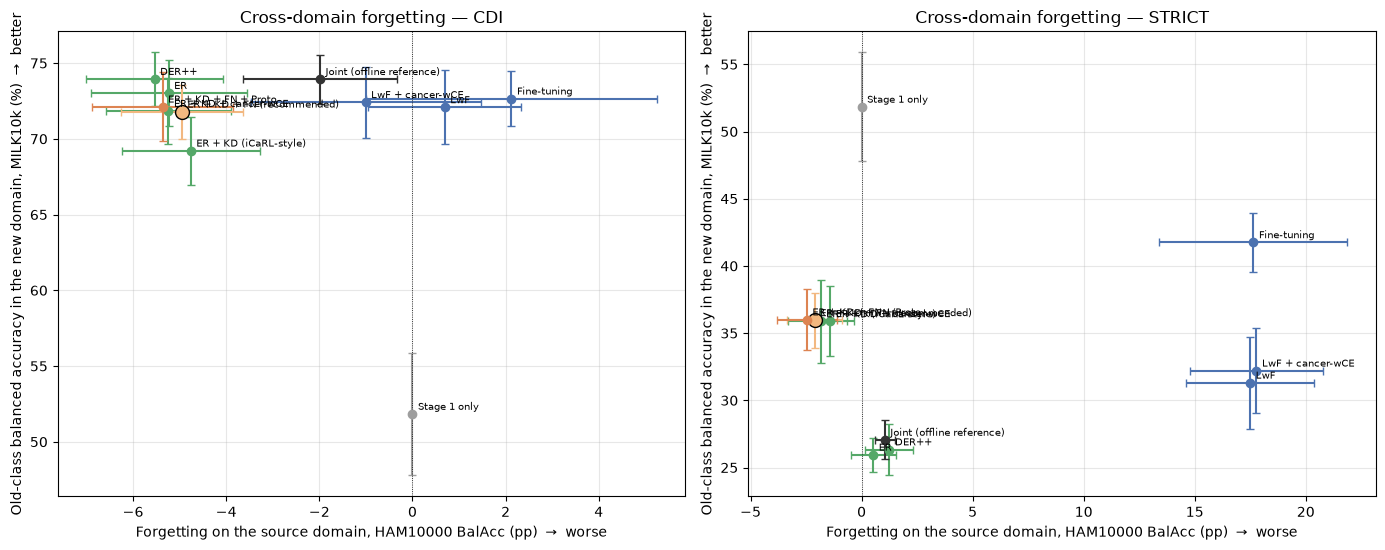


DDI group sizes (corrected table):


label,benign,malignant,All
skin_tone,,,
12,159,49,208
34,167,74,241
56,159,48,207
All,485,171,656


In [48]:
XD_METHODS = ["Stage1_Only", "Naive_FT", "LwF", "LwF_CancerWCE", "ER", "DERpp", "ER_KD", "ER_KD_CancerWCE",
              "ER_KD_FN", "CancerIL_Full_ER", "Joint_UpperBound"]
pcB = MB["per_class"].rename(columns={"method": "variant"})
pcB = pcB[pcB["dataset"] == "MILK_lesion_test"]
XD = {}
for protocol in PROTOCOLS:
    seeds = SEEDS_USED_B[protocol]
    d = main_runs[(main_runs["protocol"] == protocol) & main_runs["method"].isin(XD_METHODS) & main_runs["seed"].isin(seeds)]
    s1 = d[d["method"] == "Stage1_Only"].set_index("seed")["milk_old_bal_acc"]
    rows = []
    for m in XD_METHODS:
        g = d[d["method"] == m].set_index("seed")
        if g.empty:
            continue
        delta = (g["milk_old_bal_acc"] - s1.reindex(g.index)) * 100
        r = {"method": m, "Method": DISPLAY_C.get(m, m), "n": len(g),
             "HAM forgetting (pp)": f"{g['forgetting_bal_acc_pp'].mean():.2f} ± {g['forgetting_bal_acc_pp'].std(ddof=1):.2f}",
             "MILK old-class BalAcc": f"{g['milk_old_bal_acc'].mean() * 100:.2f} ± {g['milk_old_bal_acc'].std(ddof=1) * 100:.2f}",
             "Δ vs Stage 1 (pp)": f"{delta.mean():+.2f} ± {delta.std(ddof=1):.2f}",
             "plt_x": g["forgetting_bal_acc_pp"].mean(), "plt_xe": g["forgetting_bal_acc_pp"].std(ddof=1),
             "plt_y": g["milk_old_bal_acc"].mean() * 100, "plt_ye": g["milk_old_bal_acc"].std(ddof=1) * 100}
        pcm = pcB[(pcB["protocol"] == protocol) & (pcB["variant"] == m) & pcB["seed"].isin(seeds)]
        for c in OLD_CANCER + NEW_CLASSES:
            v = pcm[pcm["class"] == c]["post_recall"]
            r[f"MILK recall {c}"] = f"{v.mean() * 100:.1f} ± {v.std(ddof=1) * 100:.1f}" if len(v) else "–"
        rows.append(r)
    XD[protocol] = pd.DataFrame(rows)
    XD[protocol].drop(columns=[c for c in XD[protocol].columns if c.startswith("plt_") or c == "method"]).to_csv(
        RESULT_DIR / f"paper_C_cross_domain_{protocol}.csv", index=False)
    print(f"\n==== {protocol}: source forgetting vs old-class performance in the new domain ({len(seeds)} seeds) ====")
    display(XD[protocol].drop(columns=[c for c in XD[protocol].columns if c.startswith("plt_") or c == "method"]))

# paired tests on MILK old-class BalAcc
xd_tests = []
for protocol in PROTOCOLS:
    d = main_runs[(main_runs["protocol"] == protocol) & main_runs["seed"].isin(SEEDS_USED_B[protocol])]
    for a, b in [("ER_KD", "ER"), (RECOMMENDED, "ER"), (RECOMMENDED, "DERpp"), ("ER", "Stage1_Only"),
                 (RECOMMENDED, "Stage1_Only"), ("Joint_UpperBound", "Stage1_Only")]:
        A = d[d["method"] == a].set_index("seed")["milk_old_bal_acc"]
        B = d[d["method"] == b].set_index("seed")["milk_old_bal_acc"]
        cs = sorted(set(A.index) & set(B.index))
        if len(cs) < 3:
            continue
        diff = (A[cs] - B[cs]).values * 100
        xd_tests.append({"protocol": protocol, "comparison": f"{DISPLAY_C.get(a, a)} − {DISPLAY_C.get(b, b)}",
                         "n": len(cs), "Δ old-class BalAcc (pp)": diff.mean(), "sd": diff.std(ddof=1),
                         "p_ttest": stats.ttest_rel(A[cs], B[cs]).pvalue})
xd_tests = pd.DataFrame(xd_tests)
if len(xd_tests):
    xd_tests["p_holm"] = xd_tests.groupby("protocol")["p_ttest"].transform(lambda s: holm(s.values))
xd_tests.to_csv(RESULT_DIR / "paper_C_cross_domain_tests.csv", index=False)
print("\nPaired tests (MILK old-class balanced accuracy):")
display(xd_tests.round(4))

fig, axs = plt.subplots(1, len(PROTOCOLS), figsize=(7 * len(PROTOCOLS), 5.6), squeeze=False)
for ax, protocol in zip(axs[0], PROTOCOLS):
    t = XD[protocol]
    for r in t.itertuples(index=False):
        grp = METHOD_GROUPS.get(r.method, "Reference")
        ax.errorbar(r.plt_x, r.plt_y, xerr=np.nan_to_num(r.plt_xe), yerr=np.nan_to_num(r.plt_ye), fmt="o", capsize=3,
                    color=globals().get("GROUP_COLORS_B", {}).get(grp, "#777"), markersize=10 if r.method == RECOMMENDED else 6,
                    markeredgecolor="k" if r.method == RECOMMENDED else None)
        ax.annotate(r.Method, (r.plt_x, r.plt_y), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.axvline(0, color="k", lw=0.6, ls=":")
    ax.set_xlabel("Forgetting on the source domain, HAM10000 BalAcc (pp)  →  worse")
    ax.set_ylabel("Old-class balanced accuracy in the new domain, MILK10k (%)  →  better")
    ax.set_title(f"Cross-domain forgetting — {protocol}")
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "partC_cross_domain_forgetting.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nDDI group sizes (corrected table):")
display(pd.crosstab(ddi_df["skin_tone"], ddi_df["label"], margins=True))

## C6. Representation drift (linear CKA to the Stage-1 model)

For each Stage-2 model, this computes the linear CKA between its embeddings and the Stage-1 embeddings on three image sets: HAM10000 test images (source domain), MILK10k test lesions of the **old** cancer classes, and MILK10k test lesions of the **new** class (SCCKA). CKA = 1 means the representation is unchanged. If distillation matters because it keeps old-class features stable in the new domain, it shows here. This is inference only and takes about 20–40 minutes.

CKA done for seed 42


CKA done for seed 1337


CKA done for seed 2026


CKA done for seed 7


CKA done for seed 314


...

CKA done for seed 99

==== CDI: linear CKA to the Stage-1 representation (1 = unchanged) ====


set,HAM test,MILK new class,MILK old cancers
Fine-tuning,0.697 ± 0.050,0.404 ± 0.159,0.455 ± 0.199
LwF,0.691 ± 0.046,0.486 ± 0.185,0.567 ± 0.248
LwF + cancer-wCE,0.672 ± 0.058,0.446 ± 0.179,0.562 ± 0.245
ER,0.679 ± 0.215,0.390 ± 0.157,0.476 ± 0.210
DER++,0.861 ± 0.022,0.397 ± 0.162,0.501 ± 0.218
ER + KD (iCaRL-style),0.767 ± 0.046,0.537 ± 0.211,0.618 ± 0.268
ER + KD + cancer-wCE,0.774 ± 0.048,0.509 ± 0.208,0.616 ± 0.269
ER + KD + FN (recommended),0.750 ± 0.044,0.510 ± 0.207,0.594 ± 0.261
ER + KD + FN + Proto,0.747 ± 0.044,0.509 ± 0.210,0.595 ± 0.260
Joint (offline reference),0.747 ± 0.061,0.359 ± 0.148,0.414 ± 0.210



==== STRICT: linear CKA to the Stage-1 representation (1 = unchanged) ====


set,HAM test,MILK new class,MILK old cancers
Fine-tuning,0.898 ± 0.013,0.668 ± 0.262,0.689 ± 0.295
LwF,0.872 ± 0.010,0.730 ± 0.286,0.738 ± 0.319
LwF + cancer-wCE,0.879 ± 0.016,0.720 ± 0.284,0.732 ± 0.316
ER,0.856 ± 0.028,0.570 ± 0.226,0.554 ± 0.241
DER++,0.830 ± 0.142,0.568 ± 0.231,0.591 ± 0.254
ER + KD (iCaRL-style),0.876 ± 0.037,0.762 ± 0.288,0.761 ± 0.320
ER + KD + cancer-wCE,0.884 ± 0.034,0.758 ± 0.302,0.762 ± 0.324
ER + KD + FN (recommended),0.879 ± 0.043,0.748 ± 0.302,0.751 ± 0.322
ER + KD + FN + Proto,0.898 ± 0.021,0.747 ± 0.302,0.760 ± 0.326
Joint (offline reference),0.917 ± 0.026,0.574 ± 0.238,0.651 ± 0.217


,protocol,set,comparison,n,Δ CKA,p_ttest,p_holm
0,CDI,HAM test,ER + KD (iCaRL-style) − ER,7,0.0882,0.3237,0.6473
1,CDI,HAM test,ER + KD + FN (recommended) − ER,7,0.0710,0.4133,0.6473
2,CDI,HAM test,ER + KD + FN (recommended) − DER++,7,-0.1113,0.0003,0.0025
3,CDI,MILK old cancers,ER + KD (iCaRL-style) − ER,7,0.1420,0.0010,0.0069
4,CDI,MILK old cancers,ER + KD + FN (recommended) − ER,7,0.1180,0.0015,0.0073
5,CDI,MILK old cancers,ER + KD + FN (recommended) − DER++,7,0.0929,0.0013,0.0073
6,CDI,MILK new class,ER + KD (iCaRL-style) − ER,7,0.1468,0.0005,0.0039
7,CDI,MILK new class,ER + KD + FN (recommended) − ER,7,0.1199,0.0015,0.0073
8,CDI,MILK new class,ER + KD + FN (recommended) − DER++,7,0.1131,0.0012,0.0073
9,STRICT,HAM test,ER + KD (iCaRL-style) − ER,7,0.0197,0.3204,0.8169


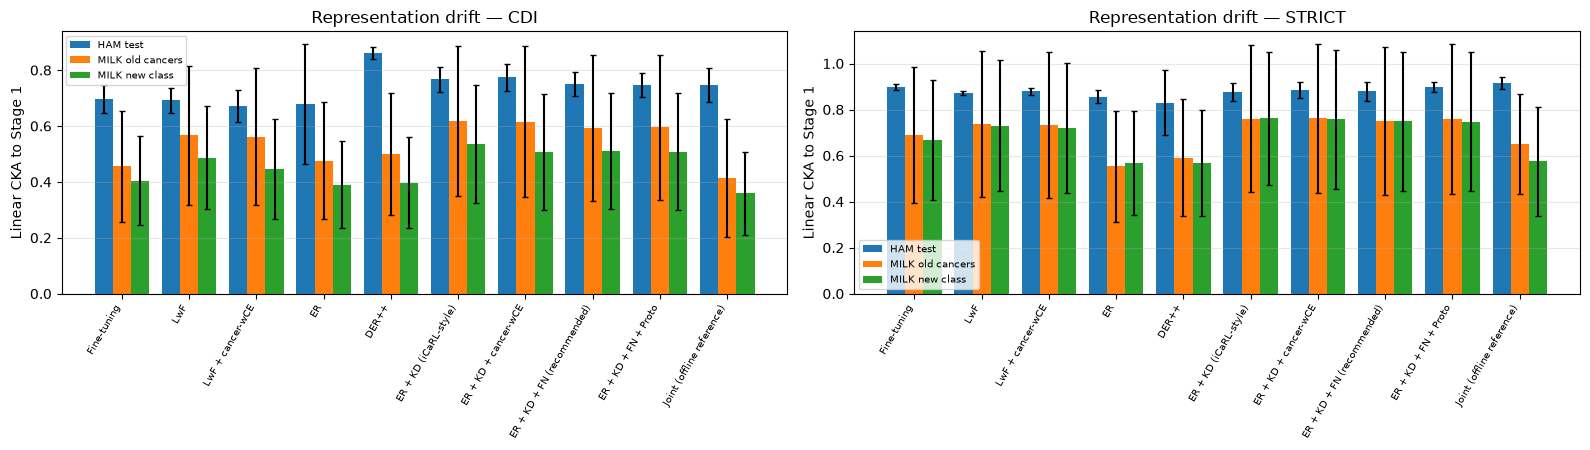

In [49]:
def _cap(df, n, seed):
    return df.sample(n, random_state=seed) if len(df) > n else df


cka_rows = []
for seed in CKA_SEEDS:
    split = make_milk_split(seed)
    te = split["test"]
    sets = {
        "HAM test": _cap(ham_test_df, CKA_MAX_IMAGES, seed)["gidx"].values,
        "MILK old cancers": _cap(te[te["label"].isin(OLD_CANCER)], CKA_MAX_IMAGES, seed)["gidx"].values,
        "MILK new class": _cap(te[te["label"].isin(NEW_CLASSES)], CKA_MAX_IMAGES, seed)["gidx"].values,
    }
    allg = np.concatenate(list(sets.values()))
    bounds = np.cumsum([0] + [len(v) for v in sets.values()])
    s1 = build_model(len(HAM_CLASSES), pretrained=False)
    s1.load_state_dict(load_state_dict_compat(CKPT_DIR / f"stage1_{STAGE1_TAG}_seed{seed}.pt"))
    E1 = extract_embeddings(s1, allg)
    del s1
    keys = {(p["protocol"], p["method"]): p["key"] for p in plan_main_B([seed])}
    for protocol in PROTOCOLS:
        for m in CKA_METHODS:
            k = keys.get((protocol, m))
            if k is None or not (CKPT_DIR / "stage2" / f"{k}.pt").exists():
                continue
            model = load_stage2_b3(k)
            E2 = extract_embeddings(model, allg)
            for (name, _), a, b in zip(sets.items(), bounds[:-1], bounds[1:]):
                cka_rows.append({"protocol": protocol, "method": m, "seed": seed, "set": name,
                                 "cka": linear_cka(E1[a:b], E2[a:b])})
            del model, E2
            torch.cuda.empty_cache()
    del E1
    torch.cuda.empty_cache()
    print(f"CKA done for seed {seed}")

CKA_DF = pd.DataFrame(cka_rows)
CKA_DF.to_csv(RESULT_DIR / "paper_C_cka_all.csv", index=False)
cka_tab = CKA_DF.groupby(["protocol", "method", "set"])["cka"].agg(["mean", "std"]).reset_index()
cka_tab["value"] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(cka_tab["mean"], cka_tab["std"])]
for protocol in PROTOCOLS:
    w = cka_tab[cka_tab["protocol"] == protocol].pivot(index="method", columns="set", values="value")
    w = w.reindex([m for m in CKA_METHODS if m in w.index])
    w.index = [DISPLAY_C.get(m, m) for m in w.index]
    w.to_csv(RESULT_DIR / f"paper_C_cka_{protocol}.csv")
    print(f"\n==== {protocol}: linear CKA to the Stage-1 representation (1 = unchanged) ====")
    display(w)

cka_tests = []
for protocol in PROTOCOLS:
    for st in ["HAM test", "MILK old cancers", "MILK new class"]:
        d = CKA_DF[(CKA_DF["protocol"] == protocol) & (CKA_DF["set"] == st)]
        for a, b in [("ER_KD", "ER"), (RECOMMENDED, "ER"), (RECOMMENDED, "DERpp")]:
            A, B = d[d["method"] == a].set_index("seed")["cka"], d[d["method"] == b].set_index("seed")["cka"]
            cs = sorted(set(A.index) & set(B.index))
            if len(cs) >= 3:
                cka_tests.append({"protocol": protocol, "set": st, "comparison": f"{DISPLAY_C.get(a, a)} − {DISPLAY_C.get(b, b)}",
                                  "n": len(cs), "Δ CKA": float((A[cs] - B[cs]).mean()),
                                  "p_ttest": stats.ttest_rel(A[cs], B[cs]).pvalue})
cka_tests = pd.DataFrame(cka_tests)
if len(cka_tests):
    cka_tests["p_holm"] = cka_tests.groupby("protocol")["p_ttest"].transform(lambda s: holm(s.values))
cka_tests.to_csv(RESULT_DIR / "paper_C_cka_tests.csv", index=False)
display(cka_tests.round(4))

fig, axs = plt.subplots(1, len(PROTOCOLS), figsize=(8 * len(PROTOCOLS), 4.6), squeeze=False)
SETS = ["HAM test", "MILK old cancers", "MILK new class"]
for ax, protocol in zip(axs[0], PROTOCOLS):
    t = cka_tab[cka_tab["protocol"] == protocol]
    ms = [m for m in CKA_METHODS if m in set(t["method"])]
    x = np.arange(len(ms))
    for j, st in enumerate(SETS):
        q = t[t["set"] == st].set_index("method").reindex(ms)
        ax.bar(x + (j - 1) * 0.27, q["mean"], 0.27, yerr=np.nan_to_num(q["std"]), capsize=2, label=st)
    ax.set_xticks(x)
    ax.set_xticklabels([DISPLAY_C.get(m, m) for m in ms], rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("Linear CKA to Stage 1")
    ax.set_title(f"Representation drift — {protocol}")
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "partC_cka_drift.png", dpi=300, bbox_inches="tight")
plt.show()

## C7. Compute cost (EfficientNet-B3, main runs)

In [50]:
cost_rows = []
for p in plan_main_B(ALL_SEEDS):
    f = RUNS_DIR / f"{p['key']}.json"
    if not f.exists():
        continue
    with open(f, encoding="utf-8") as fh:
        s = json.load(fh)
    sp = p["spec"]
    cost_rows.append({"protocol": p["protocol"], "method": p["method"], "minutes": s["minutes"], "epochs": s["epochs_run"],
                      "sec_per_epoch": 60 * s["minutes"] / max(1, s["epochs_run"]), "peak_vram_gb": s["peak_vram_gb"],
                      "replay_images": int(sp.get("rpc", REPLAY_PER_CLASS)) * len(OLD_CLASSES) if sp["replay"] != "none" else 0,
                      "teacher_forward": bool(sp["kd"] > 0 or sp["replay"] == "derpp"),
                      "extra_param_state": "Fisher + θ*" if sp["ewc"] > 0 else ("4 prototypes" if sp["proto"] > 0 else "–"),
                      "uses_all_old_data": bool(sp["joint"])})
COST = pd.DataFrame(cost_rows)
cost_tab = COST.groupby(["protocol", "method"]).agg(
    runs=("minutes", "size"), minutes=("minutes", "mean"), sec_per_epoch=("sec_per_epoch", "mean"),
    epochs=("epochs", "mean"), peak_vram_gb=("peak_vram_gb", "max"), replay_images=("replay_images", "first"),
    teacher_forward=("teacher_forward", "first"), extra_state=("extra_param_state", "first"),
    all_old_data=("uses_all_old_data", "first")).reset_index()
cost_tab["method"] = pd.Categorical(cost_tab["method"], METHOD_ORDER_B, ordered=True)
cost_tab = cost_tab.sort_values(["protocol", "method"])
cost_tab.insert(2, "Method", [DISPLAY_C.get(str(m), str(m)) for m in cost_tab["method"]])
cost_tab.to_csv(RESULT_DIR / "paper_C_compute_cost.csv", index=False)
display(cost_tab.drop(columns="method").round(2))

par = {BASE_ARCH: sum(p.numel() for p in CancerILModel(len(MILK_CLASSES), pretrained=False).parameters()) / 1e6}
for a in BACKBONES_C:
    par[a] = sum(p.numel() for p in ArchModel(a, len(MILK_CLASSES), pretrained=False).parameters()) / 1e6
print("Parameters (M):", {DISPLAY_C.get(k, k): round(v, 2) for k, v in par.items()},
      "| the proposed terms add no parameters; the teacher is a frozen copy used only during training.")

,protocol,Method,runs,minutes,sec_per_epoch,epochs,peak_vram_gb,replay_images,teacher_forward,extra_state,all_old_data
14,CDI,Fine-tuning,7,6.62,27.05,14.71,5.75,0,False,–,False
12,CDI,LwF,7,8.70,31.50,16.57,6.15,0,True,–,False
10,CDI,EWC,7,11.31,42.84,15.86,5.62,0,False,Fisher + θ*,False
13,CDI,LwF + cancer-wCE,7,9.11,31.38,17.43,6.15,0,True,–,False
16,CDI,Ours (no replay) − KD,7,7.50,26.72,16.86,5.75,0,False,4 prototypes,False
17,CDI,Ours (no replay) − Proto,7,8.87,31.59,16.86,6.15,0,True,–,False
15,CDI,Ours (no replay) − FN,7,8.82,31.45,16.86,6.15,0,True,4 prototypes,False
0,CDI,Ours (no replay),7,9.27,31.70,17.57,6.15,0,True,4 prototypes,False
4,CDI,ER,7,10.25,38.46,16.00,8.16,200,False,–,False
3,CDI,DER++,7,13.52,46.60,17.43,8.77,200,True,–,False


Parameters (M): {'EfficientNet-B3': 10.7, 'ConvNeXt-T': 27.82, 'Swin-T': 27.52} | the proposed terms add no parameters; the teacher is a frozen copy used only during training.


## C8. Second and third backbones (ConvNeXt-Tiny, Swin-T)

For each backbone: Stage 1 on HAM10000 for 5 seeds, then 10 methods × 2 protocols × 5 seeds (100 Stage-2 runs). λ values are the ones tuned on EfficientNet-B3; they are **not** re-tuned per backbone (disclose this: it can only disadvantage the methods that have λs, including ours). Resume-safe: re-run the cell after an interruption. To analyse after the first backbone, run C9 at any time.

In [51]:
seed_rank = {s: i for i, s in enumerate(ALL_SEEDS)}
prot_rank = {p: i for i, p in enumerate(RUN_ORDER_PROTOCOLS)}
_prev = []
for _f in RUNS_DIR.glob("*.json"):
    with open(_f, encoding="utf-8") as _fh:
        _prev.append(json.load(_fh))
_mins = pd.DataFrame([{"protocol": r["protocol"], "m": r["minutes"]} for r in _prev]).groupby("protocol")["m"].mean()

for arch in BACKBONES_C:
    print(f"\n######## {DISPLAY_C.get(arch, arch)} ########")
    with arch_context(arch):
        for seed in ARCH_SEEDS:
            train_stage1_arch(arch, seed)
        plan = list({p["key"]: p for p in plan_arch(arch, ARCH_SEEDS)}.values())
        todo = [p for p in plan if not (RUNS_DIR / f"{p['key']}.json").exists()]
        todo.sort(key=lambda p: (seed_rank.get(p["seed"], 99), prot_rank.get(p["protocol"], 9)))
        est = sum(float(_mins.get(p["protocol"], 8.0)) for p in todo) / 60
        print(f"{arch}: {len(plan)} runs planned | {len(plan) - len(todo)} on disk | {len(todo)} to run (rough estimate {est:.1f} h)")
        t0 = time.time()
        for i, p in enumerate(todo, 1):
            run_stage2(p["protocol"], p["seed"], p["spec"], tag=p["tag"])
            if i % 5 == 0 or i == len(todo):
                el = (time.time() - t0) / 3600
                print(f"   ... {i}/{len(todo)} | {el:.2f} h elapsed | ~{el / i * (len(todo) - i):.1f} h left")
print("\nAll extra backbones finished.")


######## ConvNeXt-T ########


Stage 1 convnext_tiny seed 42: best HAM-val macro-F1 = 0.7448 | 31 ep | peak VRAM 3.27 GB


Stage 1 convnext_tiny seed 1337: best HAM-val macro-F1 = 0.7462 | 21 ep | peak VRAM 3.26 GB


Stage 1 convnext_tiny seed 2026: best HAM-val macro-F1 = 0.7377 | 19 ep | peak VRAM 3.26 GB


Stage 1 convnext_tiny seed 7: best HAM-val macro-F1 = 0.7593 | 17 ep | peak VRAM 3.26 GB


...

[done] CDI    | swin_t:ER_KD                   | seed 314 | val=0.6796 | 19 ep | 10.9 min | peak 5.06 GB


[done] CDI    | swin_t:ER_KD_CancerWCE         | seed 314 | val=0.7017 | 16 ep | 9.2 min | peak 5.06 GB


[done] CDI    | swin_t:ER_KD_FN                | seed 314 | val=0.7484 | 18 ep | 10.4 min | peak 5.06 GB


[done] CDI    | swin_t:CancerIL_Full_ER        | seed 314 | val=0.7482 | 22 ep | 12.6 min | peak 5.06 GB


[done] CDI    | swin_t:Joint_UpperBound        | seed 314 | val=0.7372 | 20 ep | 12.3 min | peak 3.47 GB
   ... 100/100 | 10.79 h elapsed | ~0.0 h left

All extra backbones finished.


## C9. Cross-backbone replication of the findings

Each row is one pre-specified finding from Parts A/B, written as a paired comparison. Each column is a backbone. EfficientNet-B3 uses the same 5 seeds as the other backbones, so the columns are comparable. ✓ means significant (paired t-test, Holm-corrected across all findings of that backbone) in the stated direction. For the "no difference expected" rows, "≈" means no significant difference, which is what the finding predicts. Per-backbone main tables (CSV + LaTeX) are written as well.

Computing metrics: 100%|██████████| 110/110 [00:05<00:00, 21.78it/s]


Cross-backbone replication (seeds [42, 1337, 2026, 7, 314]; Δ in pp; Holm-corrected paired t-test within each backbone)


,id,Finding,Metric,EfficientNet-B3,ConvNeXt-T,Swin-T
0,F1,The common CDI setting hides forgetting (LwF: ...,forgetting_bal_acc_pp,+16.27 (p=0.002) ✓,+10.77 (p=0.007) ✓,+15.14 (p=0.007) ✓
1,F2,Replay prevents source-domain forgetting (ER v...,forgetting_bal_acc_pp,-16.86 (p=0.005) ✓,-12.68 (p=0.036) ✓,-12.27 (p=0.031) ✓
2,F3,Replay alone loses old classes in the new doma...,milk_old_bal_acc,+11.21 (p=0.009) ✓,+4.20 (p=0.043) ✓,+5.60 (p=0.057) n.s.
3,F4,KD on top of replay improves MILK macro-F1,milk_lesion_macro_f1,+15.54 (p=0.005) ✓,+6.96 (p=0.025) ✓,+8.42 (p=0.061) n.s.
4,F5,Cancer-aware FN term adds on top of ER + KD (H...,h_mean,+0.66 (p=0.313) n.s.,+1.91 (p=0.220) n.s.,+1.02 (p=0.412) n.s.
5,F6,Recommended recipe beats DER++ (H-mean),h_mean,+4.25 (p=0.001) ✓,+1.26 (p=0.736) n.s.,+0.32 (p=0.644) n.s.
6,F7,Recommended recipe beats DER++ (MILK macro-F1),milk_lesion_macro_f1,+14.56 (p=0.025) ✓,+7.22 (p=0.155) n.s.,+5.90 (p=0.327) n.s.
7,F8,Recommended recipe beats the offline joint ref...,h_mean,+2.31 (p=0.042) ✓,+0.95 (p=0.736) n.s.,+0.57 (p=0.644) n.s.
8,F9,Recommended recipe beats ER in CDI (H-mean),h_mean,+3.90 (p=0.042) ✓,+2.77 (p=0.736) n.s.,+2.65 (p=0.412) n.s.
9,F10,FN vs cancer-weighted CE: no difference expect...,h_mean,-0.01 (p=0.910) ≈,+1.17 (p=0.736) ≈,-0.76 (p=0.644) ≈



==== ConvNeXt-T — STRICT (5 seeds) ====


,Method,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,75.72 ± 2.85,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,32.99 ± 1.58,36.29 ± 1.54,84.43 ± 1.79,73.16 ± 5.03,27.40 ± 4.25,64.47 ± 1.54
1,Fine-tuning,47.36 ± 3.99,28.36 ± 6.58,58.03 ± 14.65,51.02 ± 4.28,21.79 ± 0.92,32.43 ± 2.01,84.63 ± 1.99,69.10 ± 4.86,44.49 ± 3.94,66.72 ± 1.95
2,LwF,65.77 ± 3.08,9.96 ± 3.74,90.42 ± 5.58,76.05 ± 2.66,34.48 ± 5.10,44.45 ± 3.07,86.01 ± 2.23,73.48 ± 7.63,24.92 ± 2.73,67.71 ± 1.15
3,LwF + cancer-wCE,64.63 ± 3.24,11.09 ± 4.22,95.77 ± 1.99,77.14 ± 2.55,34.48 ± 3.25,44.52 ± 2.09,85.71 ± 2.24,72.44 ± 7.62,27.74 ± 3.01,67.95 ± 1.06
4,ER,77.31 ± 3.86,-1.59 ± 1.36,93.80 ± 3.24,84.76 ± 3.63,22.71 ± 0.57,38.87 ± 0.36,84.63 ± 2.14,70.10 ± 6.80,47.15 ± 3.51,65.68 ± 2.17
5,DER++,77.10 ± 2.93,-1.38 ± 0.61,94.65 ± 1.84,84.97 ± 2.44,25.10 ± 3.08,40.20 ± 1.35,85.44 ± 2.00,72.23 ± 6.20,43.39 ± 1.71,67.03 ± 1.94
6,ER + KD (iCaRL-style),76.99 ± 2.56,-1.27 ± 2.57,93.24 ± 1.18,84.32 ± 1.54,29.68 ± 2.84,42.12 ± 1.48,86.30 ± 1.98,77.32 ± 6.41,34.96 ± 2.59,66.79 ± 1.71
7,ER + KD + cancer-wCE,76.21 ± 3.37,-0.49 ± 0.72,96.34 ± 1.26,85.05 ± 1.84,30.61 ± 2.41,42.99 ± 1.41,86.15 ± 2.10,77.53 ± 6.40,34.13 ± 2.48,67.24 ± 1.67
8,ER + KD + FN (recommended),78.46 ± 1.90,-2.73 ± 1.98,95.77 ± 1.99,86.22 ± 0.78,32.32 ± 2.40,43.99 ± 1.53,86.08 ± 2.00,77.00 ± 6.25,33.43 ± 2.75,67.47 ± 1.44
9,ER + KD + FN + Proto,77.87 ± 1.39,-2.15 ± 2.08,97.18 ± 1.99,86.44 ± 0.64,31.75 ± 2.06,43.74 ± 1.39,86.17 ± 2.16,76.29 ± 8.37,33.56 ± 1.64,67.83 ± 1.84


...

,Method,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,75.72 ± 2.85,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,32.99 ± 1.58,36.29 ± 1.54,84.43 ± 1.79,73.16 ± 5.03,27.40 ± 4.25,64.47 ± 1.54
1,Fine-tuning,76.09 ± 1.42,-0.37 ± 2.94,79.44 ± 3.81,77.68 ± 1.82,71.36 ± 0.93,71.19 ± 1.72,91.10 ± 1.69,87.91 ± 2.60,5.66 ± 1.16,67.97 ± 1.51
2,LwF,76.53 ± 2.87,-0.81 ± 1.74,78.59 ± 2.31,77.54 ± 2.42,69.79 ± 1.38,69.37 ± 1.47,90.22 ± 1.77,86.28 ± 4.83,8.67 ± 1.45,67.93 ± 2.14
3,LwF + cancer-wCE,79.07 ± 1.49,-3.34 ± 1.88,82.25 ± 3.39,80.58 ± 1.29,70.44 ± 1.33,71.83 ± 1.30,88.90 ± 1.80,83.72 ± 5.13,7.80 ± 1.54,68.41 ± 2.85
4,ER,82.92 ± 0.97,-7.19 ± 2.03,76.90 ± 3.54,79.75 ± 1.78,72.00 ± 1.50,71.35 ± 1.56,91.07 ± 1.90,88.23 ± 3.61,4.93 ± 0.34,67.46 ± 2.20
5,DER++,82.90 ± 0.94,-7.18 ± 2.30,75.21 ± 3.81,78.81 ± 1.87,72.17 ± 1.96,71.45 ± 2.05,91.30 ± 1.54,89.12 ± 3.29,4.81 ± 1.32,67.26 ± 1.00
6,ER + KD (iCaRL-style),81.84 ± 1.41,-6.12 ± 1.83,77.75 ± 5.12,79.66 ± 2.85,66.30 ± 1.42,66.54 ± 1.00,88.88 ± 2.02,83.57 ± 4.17,7.34 ± 1.15,67.15 ± 1.61
7,ER + KD + cancer-wCE,82.37 ± 1.09,-6.65 ± 2.20,80.85 ± 5.51,81.50 ± 2.52,68.22 ± 1.81,69.27 ± 1.46,87.69 ± 2.10,82.04 ± 4.56,9.64 ± 1.71,66.74 ± 1.98
8,ER + KD + FN (recommended),82.30 ± 0.57,-6.58 ± 2.80,82.82 ± 4.15,82.52 ± 2.19,68.97 ± 2.41,70.56 ± 2.64,89.94 ± 1.93,85.89 ± 3.59,8.55 ± 1.73,66.32 ± 0.65
9,ER + KD + FN + Proto,82.44 ± 1.04,-6.72 ± 2.36,83.66 ± 2.92,83.03 ± 1.67,68.81 ± 2.20,70.59 ± 1.62,90.11 ± 1.74,86.38 ± 4.18,7.44 ± 0.90,67.55 ± 1.51



==== Swin-T — STRICT (5 seeds) ====


,Method,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,75.89 ± 2.97,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,31.15 ± 3.59,34.31 ± 2.89,83.60 ± 3.16,70.88 ± 3.80,29.38 ± 6.47,64.49 ± 0.50
1,Fine-tuning,54.11 ± 2.51,21.77 ± 4.43,46.76 ± 11.02,49.62 ± 6.02,22.54 ± 0.98,31.15 ± 1.59,85.14 ± 2.10,71.45 ± 7.44,39.83 ± 2.96,68.12 ± 1.47
2,LwF,62.05 ± 4.53,13.84 ± 3.41,92.68 ± 6.17,74.08 ± 2.02,28.63 ± 4.36,41.37 ± 2.35,86.26 ± 2.30,76.68 ± 6.10,29.96 ± 7.53,66.55 ± 1.07
3,LwF + cancer-wCE,64.68 ± 2.88,11.21 ± 1.36,92.68 ± 2.31,76.15 ± 2.25,34.23 ± 2.83,44.17 ± 2.49,86.09 ± 2.24,75.15 ± 8.05,25.71 ± 3.69,66.41 ± 1.27
4,ER,76.95 ± 2.65,-1.06 ± 4.50,93.52 ± 3.24,84.41 ± 2.50,21.79 ± 0.73,38.06 ± 0.33,83.69 ± 1.63,68.54 ± 6.50,47.26 ± 1.45,64.28 ± 2.86
5,DER++,79.26 ± 1.20,-3.38 ± 2.32,92.96 ± 3.59,85.53 ± 1.59,23.93 ± 1.56,39.19 ± 0.94,84.50 ± 2.08,69.39 ± 7.28,45.41 ± 2.48,65.03 ± 1.44
6,ER + KD (iCaRL-style),78.08 ± 1.55,-2.19 ± 2.73,92.96 ± 3.45,84.83 ± 1.37,30.21 ± 4.11,42.43 ± 2.39,86.03 ± 2.58,77.39 ± 6.57,33.51 ± 4.40,66.46 ± 1.58
7,ER + KD + cancer-wCE,78.75 ± 2.15,-2.86 ± 3.01,96.34 ± 4.52,86.62 ± 2.47,29.16 ± 3.88,42.04 ± 2.50,85.99 ± 2.31,75.93 ± 7.95,37.11 ± 3.82,66.94 ± 1.82
8,ER + KD + FN (recommended),77.85 ± 1.89,-1.97 ± 2.14,95.77 ± 2.82,85.85 ± 1.17,29.83 ± 3.61,42.44 ± 1.84,85.62 ± 2.79,75.29 ± 8.94,36.13 ± 3.85,66.79 ± 1.14
9,ER + KD + FN + Proto,77.88 ± 1.66,-1.99 ± 3.04,97.18 ± 2.23,86.45 ± 1.30,30.59 ± 2.82,42.66 ± 1.86,85.78 ± 2.37,75.40 ± 7.52,36.01 ± 4.68,67.28 ± 1.83



==== Swin-T — CDI (5 seeds) ====


,Method,HAM BalAcc ↑,Forget. (pp) ↓,New recall ↑,H-mean ↑,MILK F1 ↑,MILK BalAcc ↑,Cancer AUROC ↑,Sens@Spec80 ↑,ECE ↓,DDI AUROC ↑
0,Stage 1 only,75.89 ± 2.97,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,31.15 ± 3.59,34.31 ± 2.89,83.60 ± 3.16,70.88 ± 3.80,29.38 ± 6.47,64.49 ± 0.50
1,Fine-tuning,76.45 ± 2.52,-0.56 ± 2.76,79.15 ± 3.51,77.75 ± 2.48,71.30 ± 1.33,71.36 ± 1.39,91.09 ± 1.56,89.23 ± 2.55,4.88 ± 0.92,67.13 ± 1.99
2,LwF,77.19 ± 1.55,-1.30 ± 1.48,80.56 ± 5.12,78.74 ± 1.90,70.10 ± 2.17,69.81 ± 2.26,90.00 ± 2.00,88.87 ± 4.77,9.94 ± 2.32,67.26 ± 1.19
3,LwF + cancer-wCE,79.09 ± 1.31,-3.20 ± 2.97,81.41 ± 3.05,80.20 ± 1.43,69.54 ± 2.06,71.46 ± 1.88,88.36 ± 2.00,84.53 ± 5.03,8.40 ± 1.89,66.68 ± 1.48
4,ER,83.14 ± 1.44,-7.26 ± 2.84,76.90 ± 3.81,79.87 ± 2.57,72.53 ± 0.96,72.24 ± 1.16,90.35 ± 1.49,87.27 ± 2.39,4.74 ± 0.49,63.90 ± 3.53
5,DER++,84.22 ± 1.89,-8.33 ± 3.20,78.59 ± 5.02,81.23 ± 2.77,71.27 ± 2.07,71.16 ± 2.28,90.44 ± 1.89,88.13 ± 3.95,5.09 ± 0.68,65.93 ± 1.26
6,ER + KD (iCaRL-style),82.06 ± 0.91,-6.17 ± 3.18,75.21 ± 2.92,78.47 ± 1.88,65.32 ± 2.13,65.45 ± 2.29,88.27 ± 1.94,83.40 ± 3.94,7.13 ± 2.75,65.38 ± 1.50
7,ER + KD + cancer-wCE,81.83 ± 1.70,-5.95 ± 3.19,81.97 ± 4.27,81.87 ± 2.72,68.48 ± 1.88,69.75 ± 1.60,87.14 ± 2.30,79.10 ± 6.49,9.39 ± 2.28,66.45 ± 1.31
8,ER + KD + FN (recommended),82.15 ± 0.97,-6.26 ± 2.55,83.10 ± 6.45,82.52 ± 3.23,69.38 ± 2.59,71.02 ± 2.70,89.51 ± 2.15,87.31 ± 4.25,9.41 ± 1.59,65.10 ± 1.61
9,ER + KD + FN + Proto,82.58 ± 0.65,-6.70 ± 2.84,83.38 ± 4.27,82.94 ± 2.36,69.19 ± 1.52,70.47 ± 1.80,89.62 ± 2.12,87.17 ± 3.51,9.07 ± 1.52,65.92 ± 2.12


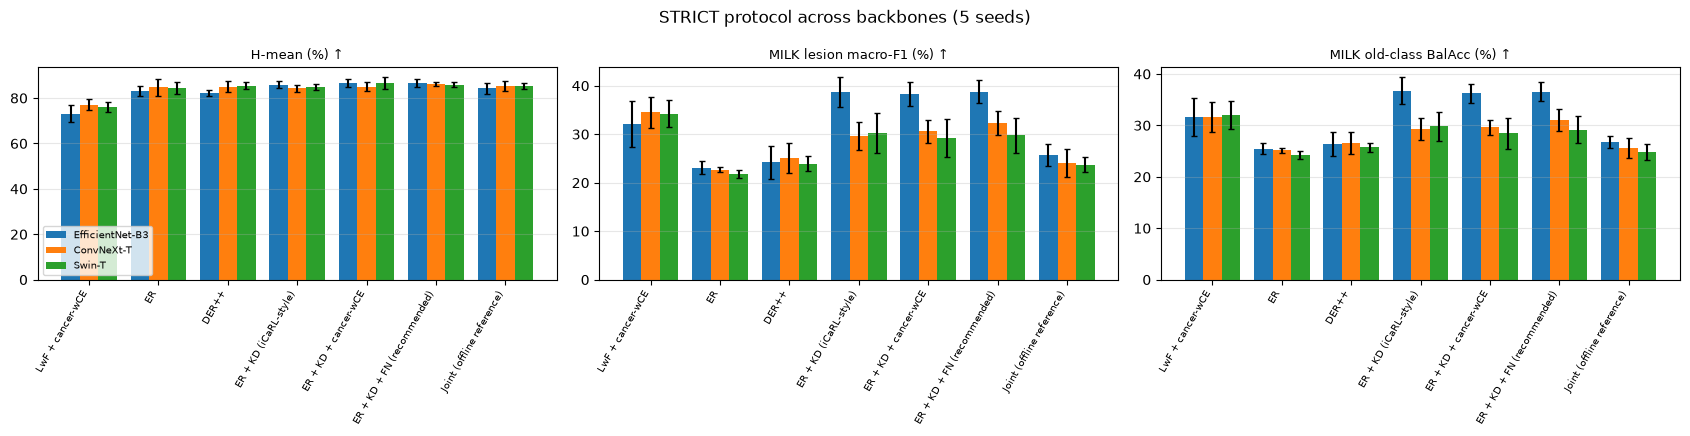

In [52]:
FINDINGS = [
    # id, description, (protocol_a, method_a), (protocol_b, method_b), metric, lower_is_better, expectation
    ("F1", "The common CDI setting hides forgetting (LwF: STRICT vs CDI)", ("STRICT", "LwF"), ("CDI", "LwF"),
     "forgetting_bal_acc_pp", True, "a_worse"),
    ("F2", "Replay prevents source-domain forgetting (ER vs LwF + cancer-wCE)", ("STRICT", "ER"), ("STRICT", "LwF_CancerWCE"),
     "forgetting_bal_acc_pp", True, "a_better"),
    ("F3", "Replay alone loses old classes in the new domain; KD restores them (MILK old-class BalAcc)",
     ("STRICT", "ER_KD"), ("STRICT", "ER"), "milk_old_bal_acc", False, "a_better"),
    ("F4", "KD on top of replay improves MILK macro-F1", ("STRICT", "ER_KD"), ("STRICT", "ER"), "milk_lesion_macro_f1", False, "a_better"),
    ("F5", "Cancer-aware FN term adds on top of ER + KD (H-mean)", ("STRICT", RECOMMENDED), ("STRICT", "ER_KD"), "h_mean", False, "a_better"),
    ("F6", "Recommended recipe beats DER++ (H-mean)", ("STRICT", RECOMMENDED), ("STRICT", "DERpp"), "h_mean", False, "a_better"),
    ("F7", "Recommended recipe beats DER++ (MILK macro-F1)", ("STRICT", RECOMMENDED), ("STRICT", "DERpp"), "milk_lesion_macro_f1", False, "a_better"),
    ("F8", "Recommended recipe beats the offline joint reference (H-mean)", ("STRICT", RECOMMENDED), ("STRICT", "Joint_UpperBound"), "h_mean", False, "a_better"),
    ("F9", "Recommended recipe beats ER in CDI (H-mean)", ("CDI", RECOMMENDED), ("CDI", "ER"), "h_mean", False, "a_better"),
    ("F10", "FN vs cancer-weighted CE: no difference expected (H-mean)", ("STRICT", RECOMMENDED), ("STRICT", "ER_KD_CancerWCE"), "h_mean", False, "equal"),
    ("F11", "Prototype term adds nothing (H-mean)", ("STRICT", "CancerIL_Full_ER"), ("STRICT", RECOMMENDED), "h_mean", False, "equal"),
]


def evaluate_findings(runs, seeds):
    rows = []
    for fid, desc, (pa, ma), (pb, mb), metric, lower, expect in FINDINGS:
        A = runs[(runs["protocol"] == pa) & (runs["method"] == ma) & runs["seed"].isin(seeds)].set_index("seed")[metric]
        B = runs[(runs["protocol"] == pb) & (runs["method"] == mb) & runs["seed"].isin(seeds)].set_index("seed")[metric]
        cs = sorted(set(A.index) & set(B.index))
        if len(cs) < 3:
            rows.append({"id": fid, "n": len(cs), "delta": np.nan, "p": np.nan, "expect": expect, "lower": lower, "metric": metric})
            continue
        diff = (A[cs] - B[cs]).values.astype(float)
        p = stats.ttest_rel(A[cs].values, B[cs].values).pvalue if diff.std(ddof=1) > 0 else 1.0
        rows.append({"id": fid, "n": len(cs), "delta": float(diff.mean()), "p": float(p), "expect": expect, "lower": lower, "metric": metric})
    r = pd.DataFrame(rows)
    ok = r["p"].notna()
    r["p_holm"] = np.nan
    r.loc[ok, "p_holm"] = holm(r.loc[ok, "p"].values)

    def verdict(x):
        if not np.isfinite(x["delta"]):
            return "–"
        sig = x["p_holm"] < ALPHA
        a_better = (x["delta"] < 0) if x["lower"] else (x["delta"] > 0)
        if x["expect"] == "equal":
            return "≈" if not sig else ("✗ (a better)" if a_better else "✗ (b better)")
        if x["expect"] == "a_worse":
            return "✓" if (sig and not a_better) else ("✗" if sig else "n.s.")
        return "✓" if (sig and a_better) else ("✗" if sig else "n.s.")
    r["verdict"] = r.apply(verdict, axis=1)
    return r


ARCH_RUNS, ARCH_M = {}, {}
b3 = main_runs.copy()
b3["arch"] = BASE_ARCH
ARCH_RUNS[BASE_ARCH] = b3
for arch in BACKBONES_C:
    M_ = collect_arch_metrics(arch, ARCH_SEEDS)
    if M_ is not None and len(M_["runs"]):
        ARCH_M[arch] = M_
        ARCH_RUNS[arch] = M_["runs"]
        M_["runs"].to_csv(RESULT_DIR / f"partC_{arch}_all_runs_metrics.csv", index=False)

rep = pd.DataFrame({"id": [f[0] for f in FINDINGS], "Finding": [f[1] for f in FINDINGS],
                    "Metric": [f[4] for f in FINDINGS]})
for arch, runs in ARCH_RUNS.items():
    r = evaluate_findings(runs, ARCH_SEEDS).set_index("id")
    k = lambda m: 1.0 if m.endswith("_pp") else 100.0
    rep[DISPLAY_C.get(arch, arch)] = [
        (f"{r.loc[f[0], 'delta'] * k(f[4]):+.2f} (p={r.loc[f[0], 'p_holm']:.3f}) {r.loc[f[0], 'verdict']}"
         if np.isfinite(r.loc[f[0], "delta"]) else f"– (n={r.loc[f[0], 'n']})") for f in FINDINGS]
rep.to_csv(RESULT_DIR / "paper_C_cross_backbone_replication.csv", index=False)
print(f"Cross-backbone replication (seeds {ARCH_SEEDS}; Δ in pp; Holm-corrected paired t-test within each backbone)")
display(rep)

# per-backbone main tables (+ LaTeX)
for arch in BACKBONES_C:
    if arch not in ARCH_RUNS:
        print(f"{arch}: no finished runs yet")
        continue
    for protocol in ARCH_PROTOCOLS:
        d = ARCH_RUNS[arch][ARCH_RUNS[arch]["protocol"] == protocol].copy()
        methods = ["Stage1_Only"] + [m for m in ARCH_METHODS if m in set(d["method"])]
        seeds = complete_seeds(d, methods)
        if not seeds:
            continue
        s = summarise(d, methods, seeds)
        s["display"] = [DISPLAY_C.get(m, m) for m in s["method"]]
        s.to_csv(RESULT_DIR / f"paper_C_summary_{arch}_{protocol}.csv", index=False)
        tex = to_latex_table(s, f"{DISPLAY_C.get(arch, arch)}, {protocol} protocol: mean $\\pm$ SD over {len(seeds)} replicates.",
                             f"tab:{arch}_{protocol.lower()}")
        (RESULT_DIR / f"paper_C_table_{arch}_{protocol}.tex").write_text(tex, encoding="utf-8")
        show = pd.DataFrame({"Method": s["display"]})
        for c, lab, hib, frac in TABLE_METRICS:
            kk = 100.0 if frac else 1.0
            show[lab + (" ↑" if hib else " ↓")] = [f"{a * kk:.2f} ± {b * kk:.2f}" if np.isfinite(b) else "–"
                                                   for a, b in zip(s[f"{c}_mean"], s[f"{c}_sd"])]
        print(f"\n==== {DISPLAY_C.get(arch, arch)} — {protocol} ({len(seeds)} seeds) ====")
        display(show)

# cross-backbone figure: H-mean and MILK macro-F1 for the key methods (STRICT)
KEY_M = ["LwF_CancerWCE", "ER", "DERpp", "ER_KD", "ER_KD_CancerWCE", RECOMMENDED, "Joint_UpperBound"]
archs = [a for a in [BASE_ARCH] + BACKBONES_C if a in ARCH_RUNS]
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (c, lab) in zip(axs, [("h_mean", "H-mean (%) ↑"), ("milk_lesion_macro_f1", "MILK lesion macro-F1 (%) ↑"),
                              ("milk_old_bal_acc", "MILK old-class BalAcc (%) ↑")]):
    w = 0.8 / max(1, len(archs))
    for j, a in enumerate(archs):
        d = ARCH_RUNS[a]
        d = d[(d["protocol"] == "STRICT") & d["seed"].isin(ARCH_SEEDS)]
        mu = [d[d["method"] == m][c].mean() * 100 for m in KEY_M]
        sd = [d[d["method"] == m][c].std(ddof=1) * 100 for m in KEY_M]
        ax.bar(np.arange(len(KEY_M)) + (j - (len(archs) - 1) / 2) * w, mu, w, yerr=np.nan_to_num(sd), capsize=2,
               label=DISPLAY_C.get(a, a))
    ax.set_xticks(np.arange(len(KEY_M)))
    ax.set_xticklabels([DISPLAY_C.get(m, m) for m in KEY_M], rotation=60, ha="right", fontsize=7)
    ax.set_title(lab, fontsize=9)
    ax.grid(axis="y", alpha=0.3)
axs[0].legend(fontsize=7)
fig.suptitle(f"STRICT protocol across backbones ({len(ARCH_SEEDS)} seeds)")
plt.tight_layout()
fig.savefig(FIG_DIR / "partC_cross_backbone_STRICT.png", dpi=300, bbox_inches="tight")
plt.show()

## C10. Grad-CAM: where does each model look? (qualitative)

MILK10k test lesions (dermoscopic images) of the **old** cancer classes. The examples are cases where the recommended recipe is correct and plain ER is not (padded with other cases if there are few). Grad-CAM is computed for the true class. Present it as qualitative illustration only, never as evidence.

Old-class dermoscopic test images: 492 | ours correct & ER wrong: 150 | ER correct & ours wrong: 0


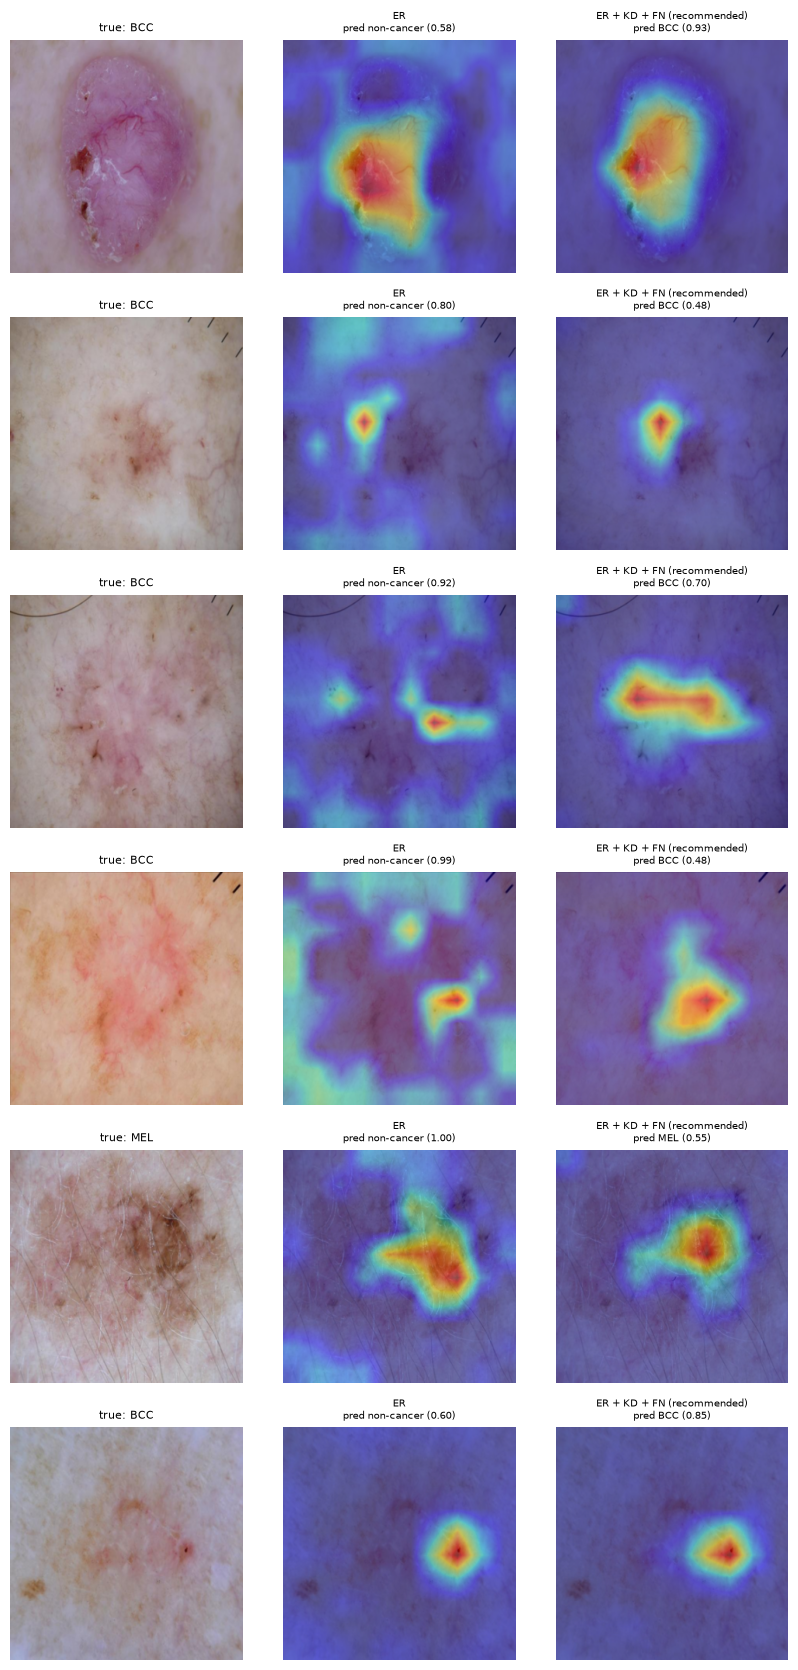

In [53]:
split = make_milk_split(GRADCAM_SEED)
te = split["test"]
sub = te[te["label"].isin(OLD_CANCER) & (te["modality"] == "dermoscopic")].reset_index(drop=True)
keys = {p["method"]: p["key"] for p in plan_main_B([GRADCAM_SEED]) if p["protocol"] == GRADCAM_PROTOCOL}
m_er, m_ours = load_stage2_b3(keys["ER"]), load_stage2_b3(keys[RECOMMENDED])
y = sub["label"].map(MILK_CLASSES.index).values
p_er = predict_probs(m_er, sub["gidx"].values).argmax(1)
p_ours = predict_probs(m_ours, sub["gidx"].values).argmax(1)
pick = list(np.where((p_ours == y) & (p_er != y))[0])
pick += [i for i in np.where(p_ours == y)[0] if i not in pick]
pick = pick[:GRADCAM_N]
print(f"Old-class dermoscopic test images: {len(sub)} | ours correct & ER wrong: {int(((p_ours == y) & (p_er != y)).sum())} "
      f"| ER correct & ours wrong: {int(((p_er == y) & (p_ours != y)).sum())}")
if pick:
    g, t = sub["gidx"].values[pick], y[pick]
    cam_er, pr_er, img = gradcam(m_er, g, t)
    cam_ou, pr_ou, _ = gradcam(m_ours, g, t)
    fig, axs = plt.subplots(len(pick), 3, figsize=(8.4, 2.8 * len(pick)), squeeze=False)
    for r in range(len(pick)):
        axs[r, 0].imshow(img[r])
        axs[r, 0].set_title(f"true: {MILK_CLASSES[t[r]]}", fontsize=8)
        for c, (cam, pr, name) in enumerate([(cam_er, pr_er, "ER"), (cam_ou, pr_ou, DISPLAY_C[RECOMMENDED])], start=1):
            axs[r, c].imshow(img[r])
            axs[r, c].imshow(cam[r], cmap="jet", alpha=0.45)
            axs[r, c].set_title(f"{name}\npred {MILK_CLASSES[pr[r].argmax()]} ({pr[r].max():.2f})", fontsize=7)
        for c in range(3):
            axs[r, c].axis("off")
    plt.tight_layout()
    fig.savefig(FIG_DIR / "partC_gradcam_ER_vs_recommended.png", dpi=200, bbox_inches="tight")
    plt.show()
del m_er, m_ours
torch.cuda.empty_cache()

## C11. How Part C changes the paper

**Method.** Report **ER + KD + FN** (`ER_KD_FN`) as the recommended recipe. The prototype term is an ablation (Part B: no contribution; C9 row F11). Be explicit that the FN term performs on par with cancer-weighted CE (row F10). The contribution is the *recipe and the evidence for it*, not a new loss.

**Main message** (keep a finding only if C9 shows ✓/≈ on at least two of the three backbones):
1. The widely used class+domain setting (CDI) hides forgetting (F1).
2. Replay prevents source-domain forgetting (F2), but **source-domain forgetting metrics miss cross-domain forgetting**: plain replay loses old-class performance in the new domain, and distillation restores it (F3, F4; C5 table and figure). C6 (CKA) gives the mechanism.
3. Cancer-aware weighting on top of ER + KD gives the best stability/plasticity trade-off (F5–F9), robust across memory budgets (B13), selection rules (B14), 7 seeds, and **three backbones** (C9).
4. Continual expansion widens the skin-tone performance gap on DDI (B15), an important limitation for clinical use.

**New figures/tables.** `partC_cross_domain_forgetting.png` (a candidate for Figure 1), `paper_C_cross_backbone_replication.csv` (a main-text table), `partC_cka_drift.png`, `paper_C_table_<backbone>_<protocol>.tex` (appendix), `paper_C_compute_cost.csv`, `partC_gradcam_ER_vs_recommended.png`.

**Disclose.** λs tuned on EfficientNet-B3 and reused for the other backbones; each backbone at its native resolution (300 / 224 / 224); the final EWC grid and whether its optimum is interior (`tuned_ewc_norm_*.json`); Grad-CAM is qualitative.